<a href="https://colab.research.google.com/github/Ngwijabagabo/Groundwater_Storage_pred/blob/main/GWPM_Rwanda_uncertainty_full_results_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Uncertainty-Aware Groundwater Potential Mapping — Eastern Province, Rwanda
### MC Dropout + BNN-Flipout · spatial validation · calibration · correlation/multicollinearity analysis · decision support

**Version 3 (complete results workflow).** Run top-to-bottom in a **fresh** Colab runtime (*Runtime → Restart session → Run all*; GPU recommended). Every table, figure, raster, model and the manuscript numbers are written to one folder:

```
/content/outputs/
├── tables/      all CSV tables (Table 1, CV, test, calibration, correlation, VIF, SHAP, AOA, classes, sensitivity …)
├── figures/     all PNG figures (300 dpi, names match the manuscript placeholders)
├── rasters/     GeoTIFFs (probability, uncertainty, PPI, DI/AOA, decision classes)
├── models/      trained models + split assignments + predictions
├── manuscript_numbers.md   every number the manuscript needs, ready to paste
├── results_report.json     machine-readable version of the same
└── run_manifest.json       configuration + software versions
```
A zip (`/content/outputs.zip`) is created at the end and downloaded automatically.

**Inputs to upload to `/content/`:** `DEM_projected.tif`, `River_D.tif`, `Drainage.tif`, `GroundW_S.tif`, `NDVI.tif`, `Rainfall.tif`, `Slope.tif`, `Geology.tif`, `LULC.tif`, `Soi_Dep.tif`, `Soil_T.tif`, `GW_SSPs.csv` (columns `X`, `Y`, `yield`).

**What is new compared with v2**
1. **Section 3.4 – Correlation and multicollinearity analysis**: Pearson and Spearman matrices (training observations and a 100 000-pixel sample), a mixed association matrix for all 11 factors (Spearman |ρ| / correlation ratio η / Cramér's V), VIF for continuous factors, generalized VIF (GVIF) for all factors including categorical ones, factor–label association tests, and an automatic list of flagged pairs.
2. The full-grid inference uses `CONFIG["FULL_GRID_T"]` (no hidden hard-coded value) and the value actually used is reported.
3. Map statistics, between-model correlation, epistemic share, Kruskal–Wallis results, class areas, sensitivity ranges and pseudo-absence results are exported as tables **and** collected in `manuscript_numbers.md`.
4. Duplicate cells removed; output organised in sub-folders; out-of-fold and test predictions saved.

## 0. Setup
### 0.1 Environment (Keras 2 for TensorFlow-Probability)

In [1]:
# Must run BEFORE TensorFlow is imported anywhere in this session.
import os, sys, subprocess, importlib.metadata as md
os.environ["TF_USE_LEGACY_KERAS"] = "1"          # tf.keras -> tf_keras (Keras 2), required by tfp.layers
if "tensorflow" in sys.modules:
    raise RuntimeError("TensorFlow was already imported. Use Runtime > Restart session, then run from the top.")
tf_ver = md.version("tensorflow")
mm = ".".join(tf_ver.split(".")[:2])
pkgs = [f"tf_keras~={mm}.0", "tensorflow-probability", "rasterio", "shap"]
print("TensorFlow", tf_ver, "-> installing", pkgs)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

TensorFlow 2.21.0 -> installing ['tf_keras~=2.21.0', 'tensorflow-probability', 'rasterio', 'shap']


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'tf_keras~=2.21.0', 'tensorflow-probability', 'rasterio', 'shap'], returncode=0)

In [2]:
# Must run BEFORE TensorFlow is imported anywhere in this session.
import os, sys, subprocess, importlib.metadata as md
os.environ["TF_USE_LEGACY_KERAS"] = "1"          # tf.keras -> tf_keras (Keras 2), required by tfp.layers
if "tensorflow" in sys.modules:
    raise RuntimeError("TensorFlow was already imported. Use Runtime > Restart session, then run from the top.")
tf_ver = md.version("tensorflow")
mm = ".".join(tf_ver.split(".")[:2])
pkgs = [f"tf_keras~={mm}.0", "tensorflow-probability", "rasterio", "shap"]
print("TensorFlow", tf_ver, "-> installing", pkgs)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

TensorFlow 2.21.0 -> installing ['tf_keras~=2.21.0', 'tensorflow-probability', 'rasterio', 'shap']


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'tf_keras~=2.21.0', 'tensorflow-probability', 'rasterio', 'shap'], returncode=0)

In [3]:
import os, gc, json, time, warnings, platform, datetime, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import display

import rasterio
from rasterio.crs import CRS
from rasterio.warp import reproject, Resampling, transform as warp_transform
from rasterio.transform import rowcol, xy as rc_to_xy
from scipy import ndimage, stats
from scipy.stats import chi2_contingency, mannwhitneyu
from scipy.spatial import cKDTree

import sklearn
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score,
                             f1_score, brier_score_loss, log_loss, confusion_matrix, pairwise_distances)

import tensorflow as tf
import tensorflow_probability as tfp
keras = tf.keras
tfd, tfpl = tfp.distributions, tfp.layers
import tf_keras
KERAS_VERSION = tf_keras.__version__
assert "tf_keras" in keras.__name__ and KERAS_VERSION.startswith("2."), \
    "tf.keras is not Keras 2. Restart the session and run from the top."

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "font.size": 9})
print(f"Python {platform.python_version()} | TF {tf.__version__} | Keras {KERAS_VERSION} | TFP {tfp.__version__} | "
      f"sklearn {sklearn.__version__} | rasterio {rasterio.__version__}")
print("GPU:", tf.config.list_physical_devices("GPU"))

Python 3.13.16 | TF 2.21.0 | Keras 2.21.0 | TFP 0.25.0 | sklearn 1.6.1 | rasterio 1.5.2
GPU: []


### 0.2 Configuration
All analysis choices are here so they can be reported exactly. **Fill every `TO COMPLETE` in `FACTOR_METADATA`** — it feeds Table 1.

In [4]:
CONFIG = dict(
    DATA_DIR    = "/content",
    ALIGNED_DIR = "/content/aligned",
    OUT_DIR     = "/content/outputs",
    SEED        = 42,

    REFERENCE_FACTOR = "Elevation",
    RASTER_FILES = {
        "Elevation": "DEM_projected.tif", "Dist_River": "River_D.tif", "Drainage_Density": "Drainage.tif",
        "Geology": "Geology.tif", "GW_Storage": "GroundW_S.tif", "LULC": "LULC.tif", "NDVI": "NDVI.tif",
        "Rainfall": "Rainfall.tif", "Slope": "Slope.tif", "Soil_Depth": "Soi_Dep.tif", "Soil_Texture": "Soil_T.tif",
    },
    CONTINUOUS_FACTORS  = ["Elevation", "Dist_River", "Drainage_Density", "GW_Storage", "NDVI", "Rainfall", "Slope"],
    CATEGORICAL_FACTORS = ["Geology", "LULC", "Soil_Depth", "Soil_Texture"],
    EXTRA_NODATA = {},                        # e.g. {"Geology": [0], "LULC": [0, 255]}

    BOREHOLE_CSV = "GW_SSPs.csv", BOREHOLE_X_COL = "X", BOREHOLE_Y_COL = "Y",
    BOREHOLE_CRS = "EPSG:32735", YIELD_COL = "yield",
    QA_COLUMN_MAP = {"Elevation": "DEM", "Slope": "Slope", "NDVI": "NDVI", "Rainfall": "Rainfall"},

    # pseudo-absence
    PA_STRATEGY = "random_buffer", PA_BUFFER_M = 1000, PA_RATIO = 1.0,
    PA_DIST_BANDS_M = [(1000, 5000), (5000, 10000), (10000, 20000), (20000, 1e9)],
    PA_ENV_QUANTILE = 0.50, RUN_PA_SENSITIVITY = True,

    # correlation / multicollinearity
    CORR_SAMPLE_PIXELS = 100000,
    CORR_THRESHOLD     = 0.70,                # |rho|, eta or Cramer's V flagged above this
    VIF_THRESHOLD      = 5.0,                 # VIF / GVIF^(1/(2df))^2 flagged above this (10 = severe)
    GVIF_MIN_CLASS_FRACTION = 0.005,          # classes rarer than this are merged with the reference class for GVIF

    # spatial validation
    BLOCK_SIZE_M = 10000, TEST_FOLD_FRACTION = 5, CV_FOLDS = 5, INNER_VAL_FOLDS = 5,

    # models
    HIDDEN_UNITS = [64, 32, 16], DROPOUT_RATE = 0.3, LEARNING_RATE = 1e-3, BATCH_SIZE = 16,
    MC_EPOCHS = 300, BNN_EPOCHS = 500, PATIENCE = 30, BNN_VAL_PASSES = 10,
    PRIOR = "Standard normal N(0, 1) on kernels (tfp default); mean-field normal posterior",

    # stochastic inference
    T_SAMPLES = 200,                          # passes per model on evaluation sets
    FULL_GRID_T = 40,                         # passes per model on the full grid (reduce to 15 only if runtime is limited; it is reported)
    FULL_GRID_BATCH = 65536, GC_EVERY_N_BATCHES = 20,
    INTERVAL = 0.95, ENTROPY_BASE = 2,

    # evaluation
    N_BOOT = 2000, CALIB_BINS_TEST = 5, CALIB_BINS_OOF = 10,

    # decision framework
    GWP_THRESHOLD = 0.5, GWP_THRESHOLDS_SENS = [0.4, 0.5, 0.6],
    UNC_COMPONENT = "epistemic", UNC_PERCENTILE = 90, UNC_PERCENTILES_SENS = [80, 90, 95],

    # explanation & diagnostics
    SHAP_BACKGROUND_K = 25, SHAP_NSAMPLES = 500, SHAP_T = 30,
    AOA_USE_SHAP_WEIGHTS = True, DIAG_SAMPLE_PIXELS = 200000, DENSITY_RADIUS_M = 5000,
)

FACTOR_METADATA = {
    "Elevation":        dict(source="USGS/NASA SRTM", product="SRTM GL1 v3 (30 m)", period="2000", aggregation="Static", units="m a.s.l."),
    "Slope":            dict(source="Derived from SRTM", product="SRTM GL1 v3", period="2000", aggregation="Static (derived)", units="degrees"),
    "Dist_River":       dict(source="TO COMPLETE", product="TO COMPLETE (river network source)", period="Static", aggregation="Euclidean distance", units="m"),
    "Drainage_Density": dict(source="Derived from SRTM flow network", product="TO COMPLETE", period="Static", aggregation="Line density (search radius TO COMPLETE)", units="km km-2"),
    "GW_Storage":       dict(source="NASA GLDAS", product="GLDAS CLSM v2.2 (daily)", period="2003-2023", aggregation="Long-term mean of monthly means", units="mm"),
    "NDVI":             dict(source="NASA MODIS", product="TO COMPLETE (e.g. MOD13Q1 v061)", period="2003-2023", aggregation="TO COMPLETE", units="-"),
    "Rainfall":         dict(source="CHIRPS", product="CHIRPS v2.0 daily", period="2003-2023", aggregation="TO COMPLETE (e.g. mean annual total)", units="mm yr-1"),
    "Geology":          dict(source="Geological Survey of Rwanda / RWB", product="Geological map", period="Static", aggregation="Categorical", units="class"),
    "LULC":             dict(source="TO COMPLETE", product="TO COMPLETE", period="TO COMPLETE", aggregation="Categorical", units="class"),
    "Soil_Depth":       dict(source="MINAGRI", product="TO COMPLETE", period="Static", aggregation="Categorical", units="class"),
    "Soil_Texture":     dict(source="MINAGRI", product="Soil map", period="Static", aggregation="Categorical", units="class"),
}
# Optional: human-readable class names for figures/tables, e.g. {"Geology": {1: "Granite/gneiss", ...}}
CLASS_LABELS = {}

# ---------------- output folders ----------------
OUT = CONFIG["OUT_DIR"]
SUB = {k: os.path.join(OUT, k) for k in ["tables", "figures", "rasters", "models"]}
for p in [OUT, CONFIG["ALIGNED_DIR"], *SUB.values()]:
    os.makedirs(p, exist_ok=True)
def tab(name):  return os.path.join(SUB["tables"], name)
def figp(name): return os.path.join(SUB["figures"], name)
def ras(name):  return os.path.join(SUB["rasters"], name)
def mod(name):  return os.path.join(SUB["models"], name)
def savefig(name, dpi=300):
    plt.savefig(figp(name), dpi=dpi, bbox_inches="tight")

SEED = CONFIG["SEED"]
np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
REPORT = {}
FACTORS = CONFIG["CONTINUOUS_FACTORS"] + CONFIG["CATEGORICAL_FACTORS"]
CONT, CAT = CONFIG["CONTINUOUS_FACTORS"], CONFIG["CATEGORICAL_FACTORS"]
assert set(FACTORS) == set(CONFIG["RASTER_FILES"]), "Every raster must be declared continuous or categorical."
missing = [f for f in list(CONFIG["RASTER_FILES"].values()) + [CONFIG["BOREHOLE_CSV"]]
           if not os.path.exists(os.path.join(CONFIG["DATA_DIR"], f))]
if missing:
    # from google.colab import files; files.upload()      # <- uncomment to upload interactively
    raise FileNotFoundError(f"Upload these to {CONFIG['DATA_DIR']}: {missing}")
print("All input files found. Outputs ->", OUT)

All input files found. Outputs -> /content/outputs


## 1. Theory (equations used in the Methods)
For pass $t=1..T$ of model $m$: $\bar p_m=\frac1T\sum_t p_{m,t}$; $U^{tot}_m=\mathbb H[\bar p_m]$; $U^{ale}_m=\frac1T\sum_t\mathbb H[p_{m,t}]$; $U^{epi}_m=U^{tot}_m-U^{ale}_m$ (mutual information), with $\mathbb H$ the binary entropy in bits.
Ensemble = equal-weight mixture of the pooled $2T$ samples: $\bar p_{ens}=\frac12\sum_m\bar p_m$, $U^{ale}_{ens}=\frac12\sum_m U^{ale}_m$, $U^{epi}_{ens}=U^{tot}_{ens}-U^{ale}_{ens}$ = mean within-model epistemic + between-model disagreement (≥ 0). The 95 % posterior predictive interval (PPI) is the 2.5–97.5 percentile range of the pooled samples. Outputs are **relative borehole-occurrence (groundwater-potential) probabilities**, because pseudo-absences are not verified absences.

## 2. Raster inventory, alignment and Table 1

In [5]:
def pixel_size_m(src):
    a, e = abs(src.transform.a), abs(src.transform.e)
    if src.crs is not None and src.crs.is_geographic:
        lat = np.radians((src.bounds.top + src.bounds.bottom) / 2)
        return a * 111320 * np.cos(lat), e * 110574
    return a, e

def transforms_match(t1, t2, tol=1e-6):
    return all(abs(a - b) < tol for a, b in zip(t1, t2))

ref_path = os.path.join(CONFIG["DATA_DIR"], CONFIG["RASTER_FILES"][CONFIG["REFERENCE_FACTOR"]])
with rasterio.open(ref_path) as r:
    REF_CRS, REF_TRANSFORM, REF_W, REF_H = r.crs, r.transform, r.width, r.height
assert REF_CRS is not None and REF_CRS.is_projected, "The reference DEM must be in a projected (metre) CRS."
PX_W, PX_H = abs(REF_TRANSFORM.a), abs(REF_TRANSFORM.e)
PIXEL_AREA_KM2 = PX_W * PX_H / 1e6
ALIGNED_PROFILE = dict(driver="GTiff", height=REF_H, width=REF_W, count=1, dtype="float32",
                       crs=REF_CRS, transform=REF_TRANSFORM, nodata=np.nan, compress="lzw")
print(f"Reference grid: {REF_W} x {REF_H} px, {PX_W:.2f} x {PX_H:.2f} m, CRS={REF_CRS}")

inventory = []
for name, fname in CONFIG["RASTER_FILES"].items():
    src_path = os.path.join(CONFIG["DATA_DIR"], fname)
    dst_path = os.path.join(CONFIG["ALIGNED_DIR"], f"{name}.tif")
    is_cat = name in CAT
    with rasterio.open(src_path) as src:
        px, py = pixel_size_m(src)
        rec = dict(Factor=name, File=fname, Type="categorical" if is_cat else "continuous",
                   Native_CRS=str(src.crs), Native_pixel_x_m=round(px, 1), Native_pixel_y_m=round(py, 1),
                   Native_dims=f"{src.width}x{src.height}", Native_nodata=src.nodata, dtype=src.dtypes[0])
        same_grid = (src.crs == REF_CRS and src.width == REF_W and src.height == REF_H
                     and transforms_match(src.transform, REF_TRANSFORM))
        resampling = Resampling.nearest if is_cat else Resampling.bilinear
        dst = np.full((REF_H, REF_W), np.nan, dtype=np.float32)
        if same_grid:
            arr = src.read(1).astype(np.float32)
            if src.nodata is not None and not np.isnan(src.nodata):
                arr[arr == src.nodata] = np.nan
            dst = arr; rec["Resampling"] = "none (native grid)"
        else:
            reproject(source=rasterio.band(src, 1), destination=dst, src_transform=src.transform, src_crs=src.crs,
                      src_nodata=src.nodata, dst_transform=REF_TRANSFORM, dst_crs=REF_CRS, dst_nodata=np.nan,
                      resampling=resampling)
            rec["Resampling"] = resampling.name
    dst[~np.isfinite(dst)] = np.nan
    dst[dst < -1e30] = np.nan
    for v in CONFIG["EXTRA_NODATA"].get(name, []):
        dst[dst == v] = np.nan
    if is_cat:
        classes = np.unique(dst[np.isfinite(dst)]); rec["n_classes"] = len(classes)
        if len(classes) > 40: print(f"  WARNING: {name} has {len(classes)} distinct values - is it really categorical?")
    with rasterio.open(dst_path, "w", **ALIGNED_PROFILE) as out:
        out.write(dst, 1)
    rec["Valid_fraction_on_grid"] = round(float(np.isfinite(dst).mean()), 4)
    inventory.append(rec)
    print(f"{name:17s} native {px:8.1f} m -> {rec['Resampling']:18s} valid={rec['Valid_fraction_on_grid']:.3f}")

for name in CONFIG["RASTER_FILES"]:
    with rasterio.open(os.path.join(CONFIG["ALIGNED_DIR"], f"{name}.tif")) as s:
        assert (s.crs == REF_CRS and s.width == REF_W and s.height == REF_H
                and transforms_match(s.transform, REF_TRANSFORM)), f"Alignment mismatch: {name}"
print("\nAll aligned rasters share identical CRS, extent, cell size and origin.")

table1 = pd.DataFrame(inventory)
for k in ["source", "product", "period", "aggregation", "units"]:
    col = "Product_version" if k == "product" else k.capitalize()
    table1[col] = table1["Factor"].map(lambda f: FACTOR_METADATA.get(f, {}).get(k, "TO COMPLETE"))
table1["Analysis_grid_m"] = f"{PX_W:.0f} x {PX_H:.0f}"
table1["Effective_resolution_note"] = np.where(
    table1[["Native_pixel_x_m", "Native_pixel_y_m"]].max(axis=1) > 1.5 * max(PX_W, PX_H),
    "Coarser than analysis grid: information content = native resolution", "Comparable to analysis grid")
cols = ["Factor", "Type", "Source", "Product_version", "Native_pixel_x_m", "Native_pixel_y_m", "Analysis_grid_m",
        "Resampling", "Period", "Aggregation", "Units", "Effective_resolution_note", "Native_CRS", "n_classes"]
table1 = table1[[c for c in cols if c in table1.columns]]
table1.to_csv(tab("table1_predictors.csv"), index=False)
todo = table1.astype(str).apply(lambda r: r.str.contains("TO COMPLETE")).any(axis=1)
if todo.any(): print("Table 1 still has 'TO COMPLETE' entries for:", list(table1.loc[todo, "Factor"]))
table1

Reference grid: 3477 x 5119 px, 30.14 x 30.06 m, CRS=EPSG:32735
Elevation         native     30.1 m -> none (native grid) valid=1.000
Dist_River        native     30.1 m -> bilinear           valid=1.000
Drainage_Density  native     30.1 m -> bilinear           valid=1.000
Geology           native     30.1 m -> nearest            valid=1.000
GW_Storage        native     30.1 m -> none (native grid) valid=1.000
LULC              native     30.1 m -> none (native grid) valid=1.000
NDVI              native     30.1 m -> none (native grid) valid=1.000
Rainfall          native     30.1 m -> bilinear           valid=1.000
Slope             native     30.1 m -> none (native grid) valid=1.000
Soil_Depth        native     30.1 m -> none (native grid) valid=1.000
Soil_Texture      native     30.1 m -> none (native grid) valid=1.000

All aligned rasters share identical CRS, extent, cell size and origin.
Table 1 still has 'TO COMPLETE' entries for: ['Dist_River', 'Drainage_Density', 'LULC', 'NDVI'

,Factor,Type,Source,Product_version,Native_pixel_x_m,Native_pixel_y_m,Analysis_grid_m,Resampling,Period,Aggregation,Units,Effective_resolution_note,Native_CRS,n_classes
0,Elevation,continuous,USGS/NASA SRTM,SRTM GL1 v3 (30 m),30.1,30.1,30 x 30,none (native grid),2000,Static,m a.s.l.,Comparable to analysis grid,EPSG:32735,NaN
1,Dist_River,continuous,TO COMPLETE,TO COMPLETE (river network source),30.1,30.1,30 x 30,bilinear,Static,Euclidean distance,m,Comparable to analysis grid,EPSG:32735,NaN
2,Drainage_Density,continuous,Derived from SRTM flow network,TO COMPLETE,30.1,30.1,30 x 30,bilinear,Static,Line density (search radius TO COMPLETE),km km-2,Comparable to analysis grid,EPSG:32735,NaN
3,Geology,categorical,Geological Survey of Rwanda / RWB,Geological map,30.1,30.1,30 x 30,nearest,Static,Categorical,class,Comparable to analysis grid,EPSG:32735,9.0
4,GW_Storage,continuous,NASA GLDAS,GLDAS CLSM v2.2 (daily),30.1,30.1,30 x 30,none (native grid),2003-2023,Long-term mean of monthly means,mm,Comparable to analysis grid,EPSG:32735,NaN
5,LULC,categorical,TO COMPLETE,TO COMPLETE,30.1,30.1,30 x 30,none (native grid),TO COMPLETE,Categorical,class,Comparable to analysis grid,EPSG:32735,8.0
6,NDVI,continuous,NASA MODIS,TO COMPLETE (e.g. MOD13Q1 v061),30.1,30.1,30 x 30,none (native grid),2003-2023,TO COMPLETE,-,Comparable to analysis grid,EPSG:32735,NaN
7,Rainfall,continuous,CHIRPS,CHIRPS v2.0 daily,30.1,30.1,30 x 30,bilinear,2003-2023,TO COMPLETE (e.g. mean annual total),mm yr-1,Comparable to analysis grid,EPSG:32735,NaN
8,Slope,continuous,Derived from SRTM,SRTM GL1 v3,30.1,30.1,30 x 30,none (native grid),2000,Static (derived),degrees,Comparable to analysis grid,EPSG:32735,NaN
9,Soil_Depth,categorical,MINAGRI,TO COMPLETE,30.1,30.1,30 x 30,none (native grid),Static,Categorical,class,Comparable to analysis grid,EPSG:32735,4.0


## 3. Data preparation
### 3.1 Aligned stack and conditioning-factor figure

Valid pixels: 17,790,168 (16,119.5 km2 at 30 m)


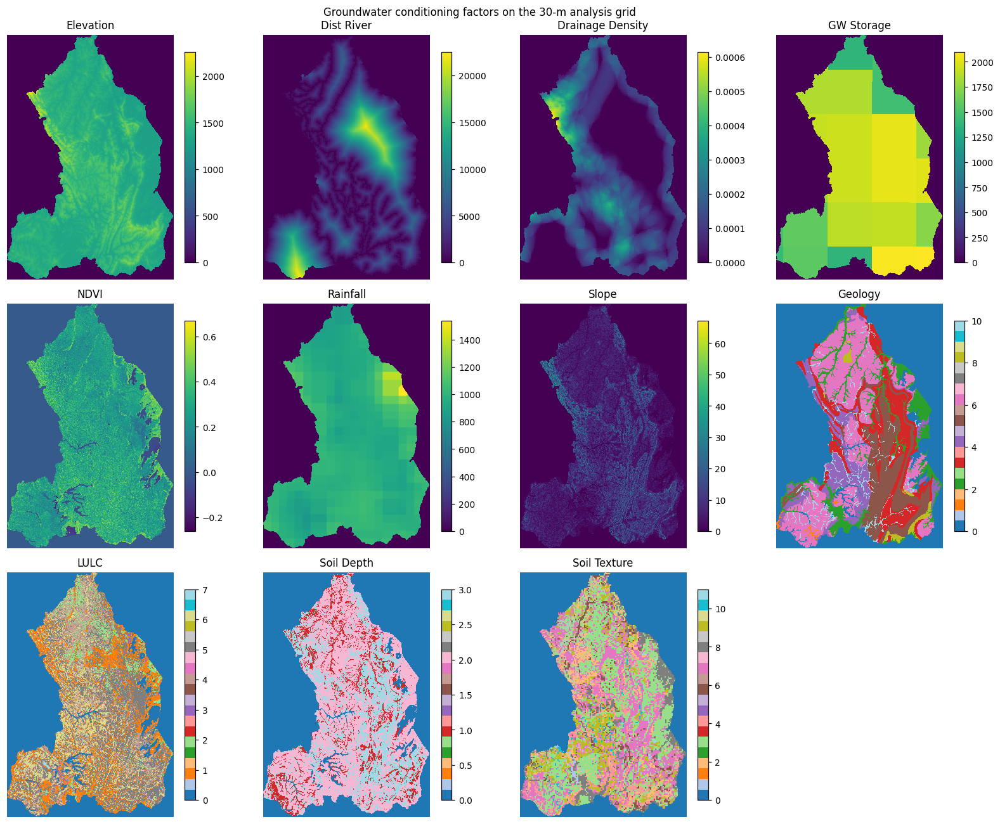

In [6]:
stack = {}
for name in FACTORS:
    with rasterio.open(os.path.join(CONFIG["ALIGNED_DIR"], f"{name}.tif")) as s:
        stack[name] = s.read(1).astype(np.float32)
H, W = REF_H, REF_W
valid_mask = np.ones((H, W), bool)
for a in stack.values(): valid_mask &= np.isfinite(a)
N_VALID = int(valid_mask.sum())
valid_idx = np.flatnonzero(valid_mask.ravel())
REPORT["study_area_km2"] = N_VALID * PIXEL_AREA_KM2
REPORT["pixel_size_m"] = PX_W
print(f"Valid pixels: {N_VALID:,} ({REPORT['study_area_km2']:,.1f} km2 at {PX_W:.0f} m)")
class_counts = []
for f in CAT:
    v, c = np.unique(stack[f][valid_mask], return_counts=True)
    for vv, cc in zip(v, c):
        class_counts.append(dict(factor=f, class_code=int(vv), label=CLASS_LABELS.get(f, {}).get(int(vv), ""),
                                 pixels=int(cc), area_km2=cc * PIXEL_AREA_KM2, pct_area=100 * cc / N_VALID))
pd.DataFrame(class_counts).round(3).to_csv(tab("categorical_class_inventory.csv"), index=False)

fig, axes = plt.subplots(3, 4, figsize=(15, 12))
for ax, name in zip(axes.flat, FACTORS):
    im = ax.imshow(np.where(valid_mask, stack[name], np.nan),
                   cmap="tab20" if name in CAT else "viridis", interpolation="nearest")
    ax.set_title(name.replace("_", " ")); ax.axis("off"); plt.colorbar(im, ax=ax, fraction=0.046)
for ax in axes.flat[len(FACTORS):]: ax.axis("off")
plt.suptitle("Groundwater conditioning factors on the 30-m analysis grid"); plt.tight_layout()
savefig("fig_conditioning_factors.png"); plt.show()

In [7]:
# ===================== 3.1b Restrict the analysis to the Eastern Province =====================
import os, requests
import numpy as np
import pandas as pd
import geopandas as gpd
from rasterio.features import geometry_mask

# --- settings ---------------------------------------------------------------
CONFIG["BOUNDARY_FILE"] = "/content/Eastern_Province.shp"    # your boundary (.shp/.geojson/.gpkg); if missing it is downloaded
CONFIG["PROVINCE_NAME_KEYS"] = ["east", "iburasirazuba"]     # used to select the province by name
CONFIG["BOUNDARY_ALL_TOUCHED"] = False                       # True = include pixels touching the border

def _select_province(gdf):
    """Keep only the Eastern Province if the file contains several polygons."""
    if len(gdf) == 1:
        return gdf
    keys = "|".join(CONFIG["PROVINCE_NAME_KEYS"])
    for col in gdf.columns:
        if gdf[col].dtype == object:
            sel = gdf[col].astype(str).str.lower().str.contains(keys, na=False)
            if sel.any():
                print(f"Selected {sel.sum()} polygon(s) where '{col}' matches {CONFIG['PROVINCE_NAME_KEYS']}")
                return gdf[sel]
    print("WARNING: no name column matched; all polygons in the file are used.")
    return gdf

def load_province():
    f = CONFIG.get("BOUNDARY_FILE")
    if f and os.path.exists(f):
        gdf, src = gpd.read_file(f), f
    else:
        print("Boundary file not found - downloading Rwanda provinces (geoBoundaries, ADM1)...")
        try:
            meta = requests.get("https://www.geoboundaries.org/api/current/gbOpen/RWA/ADM1/", timeout=60).json()
            gdf, src = gpd.read_file(meta["gjDownloadURL"]), "geoBoundaries gbOpen RWA ADM1"
        except Exception as e:
            raise RuntimeError("Could not download the boundary. Upload a boundary file of the Eastern Province "
                               f"and set CONFIG['BOUNDARY_FILE']. ({e})")
    if gdf.crs is None:
        gdf = gdf.set_crs("EPSG:4326")
        print("WARNING: boundary had no CRS; assumed EPSG:4326.")
    gdf = _select_province(gdf).to_crs(REF_CRS)
    gdf = gdf[["geometry"]].dissolve().reset_index(drop=True)
    gdf["geometry"] = gdf.buffer(0)                           # repair any invalid geometry
    return gdf, src

PROVINCE, PROVINCE_SOURCE = load_province()
inside = geometry_mask(PROVINCE.geometry, out_shape=(H, W), transform=REF_TRANSFORM,
                       invert=True, all_touched=CONFIG["BOUNDARY_ALL_TOUCHED"])

n_before = int(valid_mask.sum())
valid_mask &= inside
for f in stack:                                               # everything outside the province becomes NoData
    stack[f][~valid_mask] = np.nan

valid_idx = np.flatnonzero(valid_mask.ravel())
N_VALID = int(valid_mask.sum())
REPORT["study_area_km2"] = N_VALID * PIXEL_AREA_KM2
REPORT["province_polygon_area_km2"] = float(PROVINCE.area.sum() / 1e6)
REPORT["boundary_source"] = PROVINCE_SOURCE
REPORT["pixels_removed_outside_province"] = n_before - N_VALID

# crop window and map extent (used by all map figures)
_r = np.flatnonzero(valid_mask.any(1)); _c = np.flatnonzero(valid_mask.any(0))
CROP = (slice(_r[0], _r[-1] + 1), slice(_c[0], _c[-1] + 1))
_x0 = REF_TRANSFORM.c + _c[0] * REF_TRANSFORM.a
_x1 = REF_TRANSFORM.c + (_c[-1] + 1) * REF_TRANSFORM.a
_y1 = REF_TRANSFORM.f + _r[0] * REF_TRANSFORM.e
_y0 = REF_TRANSFORM.f + (_r[-1] + 1) * REF_TRANSFORM.e
EXTENT = [_x0, _x1, _y0, _y1]

os.makedirs(os.path.join(CONFIG["OUT_DIR"], "rasters"), exist_ok=True)
PROVINCE.to_file(os.path.join(CONFIG["OUT_DIR"], "rasters", "eastern_province_boundary.gpkg"), driver="GPKG")
print(f"Boundary: {PROVINCE_SOURCE}")
print(f"Province polygon area: {REPORT['province_polygon_area_km2']:,.1f} km2 | "
      f"analysed area (valid pixels inside province): {REPORT['study_area_km2']:,.1f} km2")
print(f"Pixels removed outside the province: {REPORT['pixels_removed_outside_province']:,}")

Boundary file not found - downloading Rwanda provinces (geoBoundaries, ADM1)...
Selected 1 polygon(s) where 'shapeName' matches ['east', 'iburasirazuba']
Boundary: geoBoundaries gbOpen RWA ADM1
Province polygon area: 9,493.5 km2 | analysed area (valid pixels inside province): 9,493.4 km2
Pixels removed outside the province: 7,312,825


### 3.2 Borehole inventory
Reprojection, removal of points outside the grid / on nodata, collapsing of duplicate-pixel boreholes, and QA against the CSV attributes.

In [8]:
bh = pd.read_csv(os.path.join(CONFIG["DATA_DIR"], CONFIG["BOREHOLE_CSV"]))
bh.columns = bh.columns.str.strip()
REPORT["n_boreholes_inventory"] = len(bh)
bx, by = bh[CONFIG["BOREHOLE_X_COL"]].values.astype(float), bh[CONFIG["BOREHOLE_Y_COL"]].values.astype(float)
pt_crs = CRS.from_user_input(CONFIG["BOREHOLE_CRS"])
if pt_crs != REF_CRS:
    bx, by = map(np.asarray, warp_transform(pt_crs, REF_CRS, bx, by)); print(f"Reprojected {pt_crs} -> {REF_CRS}")
bh["x_grid"], bh["y_grid"] = bx, by
r_, c_ = rowcol(REF_TRANSFORM, bx, by)
bh["row"], bh["col"] = np.asarray(r_), np.asarray(c_)
inb = (bh.row >= 0) & (bh.row < H) & (bh.col >= 0) & (bh.col < W)
REPORT["n_outside_grid"] = int((~inb).sum()); bh = bh[inb].copy()
onv = valid_mask[bh.row.values, bh.col.values]
REPORT["n_on_nodata"] = int((~onv).sum()); bh = bh[onv].copy()
n_before = len(bh)
bh = bh.drop_duplicates(subset=["row", "col"]).reset_index(drop=True)
REPORT["n_duplicate_pixel"] = n_before - len(bh)
REPORT["n_presence"] = len(bh)
print(f"Inventory {REPORT['n_boreholes_inventory']} | outside grid {REPORT['n_outside_grid']} | on nodata "
      f"{REPORT['n_on_nodata']} | duplicate pixel {REPORT['n_duplicate_pixel']} | retained {len(bh)}")

qa = []
for f, col in CONFIG["QA_COLUMN_MAP"].items():
    if col in bh.columns:
        rv = stack[f][bh.row.values, bh.col.values]; cv = pd.to_numeric(bh[col], errors="coerce").values
        ok = np.isfinite(rv) & np.isfinite(cv)
        if ok.sum() > 2:
            qa.append(dict(factor=f, csv_column=col, n=int(ok.sum()), pearson_r=round(stats.pearsonr(rv[ok], cv[ok])[0], 3),
                           median_abs_diff=round(float(np.median(np.abs(rv[ok] - cv[ok]))), 3)))
qa = pd.DataFrame(qa); qa.to_csv(tab("borehole_qa_raster_vs_csv.csv"), index=False); display(qa)
if len(qa) and (qa.pearson_r < 0.8).any():
    print("WARNING: low agreement between raster and CSV values - check BOREHOLE_CRS / raster versions.")

borehole_mask = np.zeros((H, W), bool); borehole_mask[bh.row.values, bh.col.values] = True
dist_to_bh = ndimage.distance_transform_edt(~borehole_mask, sampling=(PX_H, PX_W)).astype(np.float32)

Inventory 153 | outside grid 0 | on nodata 0 | duplicate pixel 7 | retained 146


,factor,csv_column,n,pearson_r,median_abs_diff
0,Elevation,DEM,146,1.000,0.0
1,Slope,Slope,146,0.935,0.0
2,NDVI,NDVI,146,0.871,0.0
3,Rainfall,Rainfall,146,1.000,0.0


### 3.3 Pseudo-absence generation

Dataset: 292 obs (146 presences, 146 pseudo-absences); buffer 1000 m


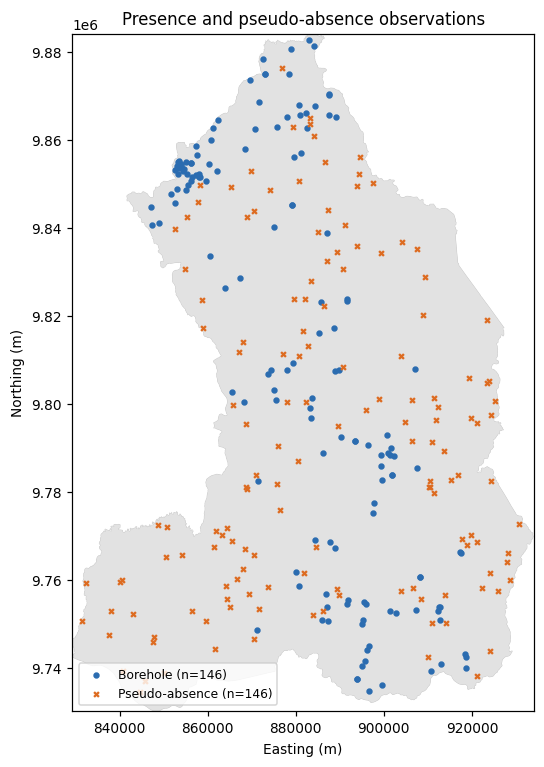

In [9]:
_maha_cache = {}
def presence_mahalanobis_raster():
    if "m" in _maha_cache: return _maha_cache["m"]
    Xp = np.stack([stack[f][bh.row.values, bh.col.values] for f in CONT], 1).astype(np.float64)
    mu, VI = Xp.mean(0), np.linalg.pinv(np.cov(Xp, rowvar=False))
    out = np.full(H * W, np.nan, np.float32)
    for s in range(0, len(valid_idx), 1_000_000):
        ii = valid_idx[s:s + 1_000_000]
        Z = np.stack([stack[f].ravel()[ii] for f in CONT], 1) - mu
        out[ii] = np.sqrt(np.einsum("ij,jk,ik->i", Z, VI, Z))
    dp = np.sqrt(np.einsum("ij,jk,ik->i", Xp - mu, VI, Xp - mu))
    _maha_cache["m"] = (out.reshape(H, W), dp)
    return _maha_cache["m"]

def sample_pseudo_absence(n, strategy, buffer_m, seed):
    rng = np.random.default_rng(seed)
    base = valid_mask & (dist_to_bh > buffer_m)
    if strategy == "random_buffer":
        pick = rng.choice(np.flatnonzero(base.ravel()), n, replace=False)
    elif strategy == "distance_stratified":
        bands = [(max(lo, buffer_m), hi) for lo, hi in CONFIG["PA_DIST_BANDS_M"]]
        bands = [b for b in bands if (base & (dist_to_bh > b[0]) & (dist_to_bh <= b[1])).any()]
        per = np.full(len(bands), n // len(bands)); per[: n - per.sum()] += 1
        pick = np.concatenate([rng.choice(np.flatnonzero((base & (dist_to_bh > lo) & (dist_to_bh <= hi)).ravel()),
                                          k, replace=False) for (lo, hi), k in zip(bands, per)])
    elif strategy == "environmental_profile":
        m, dp = presence_mahalanobis_raster()
        pick = rng.choice(np.flatnonzero((base & (m > np.quantile(dp, CONFIG["PA_ENV_QUANTILE"]))).ravel()), n, replace=False)
    else:
        raise ValueError(strategy)
    return np.unravel_index(pick, (H, W))

def build_dataset(pa_rows, pa_cols):
    pr, pc = bh.row.values, bh.col.values
    rows = np.concatenate([pr, pa_rows]); cols = np.concatenate([pc, pa_cols])
    df = pd.DataFrame({f: stack[f][rows, cols] for f in FACTORS})
    df["label"] = np.r_[np.ones(len(pr)), np.zeros(len(pa_rows))].astype(int)
    df["row"], df["col"] = rows, cols
    xs, ys = rc_to_xy(REF_TRANSFORM, rows, cols); df["x"], df["y"] = np.asarray(xs), np.asarray(ys)
    yv = pd.to_numeric(bh[CONFIG["YIELD_COL"]], errors="coerce").values if CONFIG["YIELD_COL"] in bh else np.full(len(pr), np.nan)
    df["yield_reference_only"] = np.r_[yv, np.full(len(pa_rows), np.nan)]
    return df

n_pa = int(round(len(bh) * CONFIG["PA_RATIO"]))
pa_r, pa_c = sample_pseudo_absence(n_pa, CONFIG["PA_STRATEGY"], CONFIG["PA_BUFFER_M"], SEED)
data = build_dataset(pa_r, pa_c)
REPORT.update(n_pseudo_absence=n_pa, pa_strategy=CONFIG["PA_STRATEGY"], pa_buffer_m=CONFIG["PA_BUFFER_M"], n_total=len(data))
print(f"Dataset: {len(data)} obs ({data.label.sum()} presences, {(data.label == 0).sum()} pseudo-absences); buffer {CONFIG['PA_BUFFER_M']} m")

fig, ax = plt.subplots(figsize=(6, 8))
ext = [REF_TRANSFORM.c, REF_TRANSFORM.c + W * REF_TRANSFORM.a, REF_TRANSFORM.f + H * REF_TRANSFORM.e, REF_TRANSFORM.f]
ax.imshow(np.where(valid_mask, 1, np.nan), cmap="Greys", vmin=0, vmax=3, alpha=0.5, extent=ext)
ax.scatter(data.x[data.label == 1], data.y[data.label == 1], s=10, c="#2b6cb0", label=f"Borehole (n={int(data.label.sum())})")
ax.scatter(data.x[data.label == 0], data.y[data.label == 0], s=10, c="#dd6b20", marker="x", label=f"Pseudo-absence (n={n_pa})")
ax.legend(loc="lower left", fontsize=8); ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
ax.set_title("Presence and pseudo-absence observations")
savefig("fig_training_points.png"); plt.show()

### 3.4 Correlation and multicollinearity analysis of the conditioning factors
Strong dependence among predictors does not bias the predictive mean of a neural network, but it (i) makes factor-importance (SHAP) and its interpretation ambiguous, (ii) inflates the dimensionality of the feature space used for the dissimilarity index, and (iii) is a standard reviewer request in GWPM studies. The analysis is run on **two samples**: the 292 modelling observations (presences + pseudo-absences) and a random sample of `CORR_SAMPLE_PIXELS` valid pixels (the population to which the model is applied).

| Pair type | Measure | Range |
|---|---|---|
| continuous – continuous | Pearson *r* and Spearman ρ | −1 … 1 |
| categorical – continuous | correlation ratio η | 0 … 1 |
| categorical – categorical | bias-corrected Cramér's V | 0 … 1 |
| multicollinearity, continuous | VIF = diag(R⁻¹) | ≥ 1 |
| multicollinearity, all 11 factors | generalized VIF, GVIF^(1/(2df)) (Fox & Monette 1992); squared value is comparable with VIF | ≥ 1 |
| factor – label | Mann–Whitney U + rank-biserial r (continuous); χ² + Cramér's V (categorical) | |

Pairs with |ρ|, η or V ≥ `CORR_THRESHOLD` and factors with VIF (or squared GVIF^(1/(2df))) ≥ `VIF_THRESHOLD` are flagged.

In [10]:
rng_c = np.random.default_rng(SEED)
pix = rng_c.choice(valid_idx, min(CONFIG["CORR_SAMPLE_PIXELS"], N_VALID), replace=False)
pix_df = pd.DataFrame({f: stack[f].ravel()[pix] for f in FACTORS})
obs_df = data[FACTORS + ["label"]].copy()
for d_ in (pix_df, obs_df):
    for c in CAT: d_[c] = d_[c].astype(int)

def cramers_v(x, y, bias_correct=True):
    ct = pd.crosstab(np.asarray(x), np.asarray(y)).values
    if ct.shape[0] < 2 or ct.shape[1] < 2: return np.nan
    chi2 = chi2_contingency(ct, correction=False)[0]; n = ct.sum(); r, k = ct.shape
    phi2 = chi2 / n
    if bias_correct:
        phi2 = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
        r = r - (r - 1) ** 2 / (n - 1); k = k - (k - 1) ** 2 / (n - 1)
    d = min(k - 1, r - 1)
    return float(np.sqrt(phi2 / d)) if d > 0 else np.nan

def correlation_ratio(cat, val):
    cat = np.asarray(cat); val = np.asarray(val, float); m = val.mean()
    ss_tot = ((val - m) ** 2).sum()
    ss_b = sum((cat == c).sum() * (val[cat == c].mean() - m) ** 2 for c in np.unique(cat))
    return float(np.sqrt(ss_b / ss_tot)) if ss_tot > 0 else np.nan

def mixed_association(df):
    A = pd.DataFrame(np.eye(len(FACTORS)), index=FACTORS, columns=FACTORS)
    kind = pd.DataFrame("", index=FACTORS, columns=FACTORS)
    for i, a in enumerate(FACTORS):
        for b in FACTORS[i + 1:]:
            if a in CONT and b in CONT: v, k = abs(stats.spearmanr(df[a], df[b])[0]), "|Spearman rho|"
            elif a in CAT and b in CAT: v, k = cramers_v(df[a], df[b]), "Cramer's V"
            else:
                cc, nn = (a, b) if a in CAT else (b, a); v, k = correlation_ratio(df[cc], df[nn]), "eta"
            A.loc[a, b] = A.loc[b, a] = v; kind.loc[a, b] = kind.loc[b, a] = k
    return A, kind

def vif_continuous(df):
    R = np.corrcoef(df[CONT].astype(float).values, rowvar=False)
    return pd.Series(np.diag(np.linalg.pinv(R)), index=CONT)

def gvif_all(df, min_frac):
    cols, blocks, info = [], {}, {}
    for c in CONT:
        blocks[c] = [len(cols)]; cols.append(df[c].astype(float).values)
    for c in CAT:
        vc = df[c].value_counts(normalize=True)
        keep = sorted([v for v in vc.index if vc[v] >= min_frac])
        ref, dummies = keep[0], keep[1:]                      # first frequent class = reference; rare classes merged into it
        idx = []
        for v in dummies:
            col = (df[c].values == v).astype(float)
            if col.std() > 0: idx.append(len(cols)); cols.append(col)
        if idx: blocks[c] = idx
        info[c] = f"reference class {ref}; {len(idx)} dummies; {len(vc) - len(keep)} rare classes merged"
    X = np.column_stack(cols)
    R = np.corrcoef(X, rowvar=False)
    _, ld = np.linalg.slogdet(R)
    rows = []
    for f, idx in blocks.items():
        rest = [j for j in range(X.shape[1]) if j not in idx]
        _, l1 = np.linalg.slogdet(R[np.ix_(idx, idx)]); _, l2 = np.linalg.slogdet(R[np.ix_(rest, rest)])
        g = float(np.exp(l1 + l2 - ld)); dfree = len(idx); adj = g ** (1 / (2 * dfree))
        rows.append(dict(factor=f, type="categorical" if f in CAT else "continuous", df=dfree, GVIF=g,
                         GVIF_adj=adj, GVIF_adj_squared=adj ** 2, note=info.get(f, "")))
    return pd.DataFrame(rows)

corr_out = {}
for sname, df in [("observations", obs_df), ("pixels", pix_df)]:
    pear = df[CONT].corr(method="pearson"); spear = df[CONT].corr(method="spearman")
    A, kind = mixed_association(df)
    vif = vif_continuous(df); gv = gvif_all(df, CONFIG["GVIF_MIN_CLASS_FRACTION"])
    pear.round(3).to_csv(tab(f"corr_pearson_continuous_{sname}.csv"))
    spear.round(3).to_csv(tab(f"corr_spearman_continuous_{sname}.csv"))
    A.round(3).to_csv(tab(f"association_matrix_all_factors_{sname}.csv"))
    vif.round(3).rename("VIF").to_csv(tab(f"vif_continuous_{sname}.csv"))
    gv.round(3).to_csv(tab(f"gvif_all_factors_{sname}.csv"), index=False)
    corr_out[sname] = dict(pearson=pear, spearman=spear, assoc=A, kind=kind, vif=vif, gvif=gv)
    print(f"\n=== {sname} (n = {len(df):,}) ===")
    print("VIF (continuous):", vif.round(2).to_dict())
    display(gv.round(2))

# ---- flagged pairs and factors ----
flags = []
for sname, o in corr_out.items():
    A, kind = o["assoc"], o["kind"]
    for i, a in enumerate(FACTORS):
        for b in FACTORS[i + 1:]:
            if A.loc[a, b] >= CONFIG["CORR_THRESHOLD"]:
                flags.append(dict(sample=sname, item=f"{a} ~ {b}", measure=kind.loc[a, b], value=round(A.loc[a, b], 3)))
    for f, v in o["vif"].items():
        if v >= CONFIG["VIF_THRESHOLD"]: flags.append(dict(sample=sname, item=f, measure="VIF", value=round(v, 2)))
    for r in o["gvif"].itertuples():
        if r.GVIF_adj_squared >= CONFIG["VIF_THRESHOLD"]:
            flags.append(dict(sample=sname, item=r.factor, measure="GVIF^(1/(2df)) squared", value=round(r.GVIF_adj_squared, 2)))
flags = pd.DataFrame(flags, columns=["sample", "item", "measure", "value"])
flags.to_csv(tab("collinearity_flags.csv"), index=False)
print("\nFlagged items:" if len(flags) else "\nNo pair or factor exceeded the thresholds.")
if len(flags): display(flags)

# ---- association of each factor with the label (presence vs pseudo-absence) ----
lab_rows = []
y_ = obs_df.label.values
for f in FACTORS:
    if f in CONT:
        a1, a0 = obs_df.loc[y_ == 1, f].values, obs_df.loc[y_ == 0, f].values
        U, p = mannwhitneyu(a1, a0, alternative="two-sided")
        lab_rows.append(dict(factor=f, type="continuous", test="Mann-Whitney U", statistic=U, p_value=p,
                             effect="rank-biserial r", effect_size=2 * U / (len(a1) * len(a0)) - 1,
                             median_presence=np.median(a1), median_pseudo_absence=np.median(a0),
                             point_biserial_r=stats.pointbiserialr(y_, obs_df[f].values)[0]))
    else:
        ct = pd.crosstab(obs_df[f], obs_df.label)
        chi2, p, dof, _ = chi2_contingency(ct.values)
        lab_rows.append(dict(factor=f, type="categorical", test=f"chi-square (df={dof})", statistic=chi2, p_value=p,
                             effect="Cramer's V", effect_size=cramers_v(obs_df[f], obs_df.label)))
lab_df = pd.DataFrame(lab_rows)
lab_df.to_csv(tab("factor_label_association.csv"), index=False)
display(lab_df.round(4))

REPORT["correlation"] = dict(
    max_abs_spearman_cont_obs=float((corr_out["observations"]["spearman"].abs() - np.eye(len(CONT))).max().max()),
    max_abs_spearman_cont_pix=float((corr_out["pixels"]["spearman"].abs() - np.eye(len(CONT))).max().max()),
    max_vif_obs=float(corr_out["observations"]["vif"].max()), max_vif_pix=float(corr_out["pixels"]["vif"].max()),
    max_gvif_adj_sq_obs=float(corr_out["observations"]["gvif"].GVIF_adj_squared.max()),
    max_gvif_adj_sq_pix=float(corr_out["pixels"]["gvif"].GVIF_adj_squared.max()),
    n_flags=int(len(flags)), flags=flags.to_dict("records"))


=== observations (n = 292) ===
VIF (continuous): {'Elevation': 1.25, 'Dist_River': 1.83, 'Drainage_Density': 1.96, 'GW_Storage': 1.1, 'NDVI': 1.06, 'Rainfall': 1.11, 'Slope': 1.19}


,factor,type,df,GVIF,GVIF_adj,GVIF_adj_squared,note
0,Elevation,continuous,1,1.58,1.26,1.58,
1,Dist_River,continuous,1,2.19,1.48,2.19,
2,Drainage_Density,continuous,1,2.27,1.51,2.27,
3,GW_Storage,continuous,1,1.26,1.12,1.26,
4,NDVI,continuous,1,1.93,1.39,1.93,
5,Rainfall,continuous,1,1.36,1.17,1.36,
6,Slope,continuous,1,1.50,1.23,1.50,
7,Geology,categorical,7,5.28,1.13,1.27,reference class 0; 7 dummies; 1 rare classes m...
8,LULC,categorical,5,9.90,1.26,1.58,reference class 0; 5 dummies; 1 rare classes m...
9,Soil_Depth,categorical,3,9.33,1.45,2.11,reference class 0; 3 dummies; 0 rare classes m...



=== pixels (n = 100,000) ===
VIF (continuous): {'Elevation': 1.86, 'Dist_River': 1.88, 'Drainage_Density': 2.07, 'GW_Storage': 1.51, 'NDVI': 1.12, 'Rainfall': 1.28, 'Slope': 1.27}


,factor,type,df,GVIF,GVIF_adj,GVIF_adj_squared,note
0,Elevation,continuous,1,2.68,1.64,2.68,
1,Dist_River,continuous,1,2.09,1.45,2.09,
2,Drainage_Density,continuous,1,2.15,1.47,2.15,
3,GW_Storage,continuous,1,1.66,1.29,1.66,
4,NDVI,continuous,1,2.45,1.57,2.45,
5,Rainfall,continuous,1,1.51,1.23,1.51,
6,Slope,continuous,1,1.72,1.31,1.72,
7,Geology,categorical,7,4.40,1.11,1.24,reference class 0; 7 dummies; 1 rare classes m...
8,LULC,categorical,6,8.93,1.20,1.44,reference class 0; 6 dummies; 1 rare classes m...
9,Soil_Depth,categorical,3,6.51,1.37,1.87,reference class 0; 3 dummies; 0 rare classes m...



Flagged items:


,sample,item,measure,value
0,observations,Dist_River ~ Drainage_Density,|Spearman rho|,0.783
1,pixels,Dist_River ~ Drainage_Density,|Spearman rho|,0.822
2,pixels,NDVI ~ LULC,eta,0.729


,factor,type,test,statistic,p_value,effect,effect_size,median_presence,median_pseudo_absence,point_biserial_r
0,Elevation,continuous,Mann-Whitney U,10420.0000,0.7420,rank-biserial r,-0.0223,1386.5000,1398.5000,-0.0867
1,Dist_River,continuous,Mann-Whitney U,5809.0000,0.0000,rank-biserial r,-0.4550,1048.6490,3378.3445,-0.3325
2,Drainage_Density,continuous,Mann-Whitney U,14760.5000,0.0000,rank-biserial r,0.3849,0.0002,0.0001,0.2926
3,GW_Storage,continuous,Mann-Whitney U,10796.5000,0.8478,rank-biserial r,0.0130,1894.6024,1894.6024,0.0328
4,NDVI,continuous,Mann-Whitney U,10199.0000,0.5251,rank-biserial r,-0.0431,0.2601,0.2615,0.0044
5,Rainfall,continuous,Mann-Whitney U,9606.5000,0.1451,rank-biserial r,-0.0987,955.3258,961.3499,-0.0478
6,Slope,continuous,Mann-Whitney U,9188.5000,0.0417,rank-biserial r,-0.1379,4.1417,5.1077,-0.1767
7,Geology,categorical,chi-square (df=8),18.5051,0.0177,Cramer's V,0.1898,NaN,NaN,NaN
8,LULC,categorical,chi-square (df=6),42.3652,0.0000,Cramer's V,0.3534,NaN,NaN,NaN
9,Soil_Depth,categorical,chi-square (df=3),11.5274,0.0092,Cramer's V,0.1711,NaN,NaN,NaN


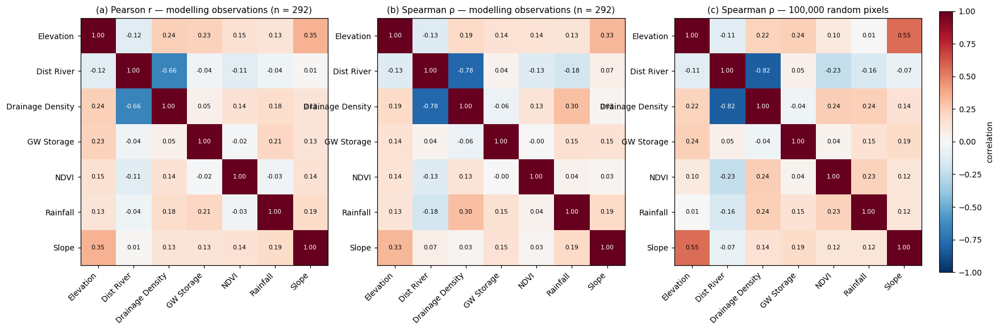

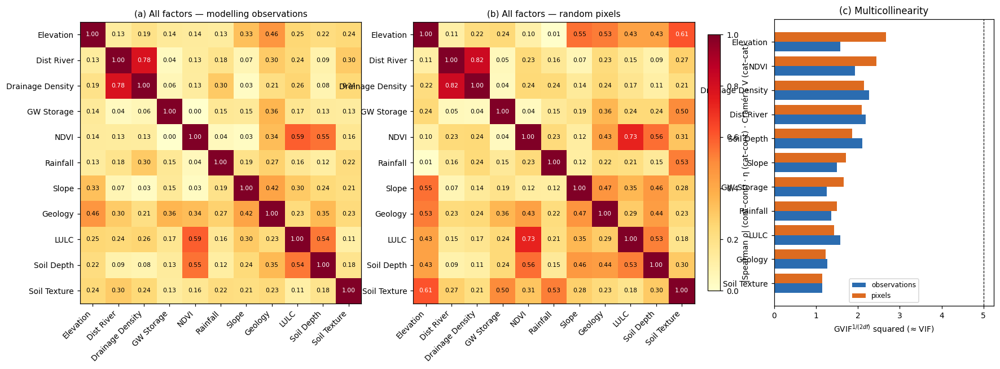

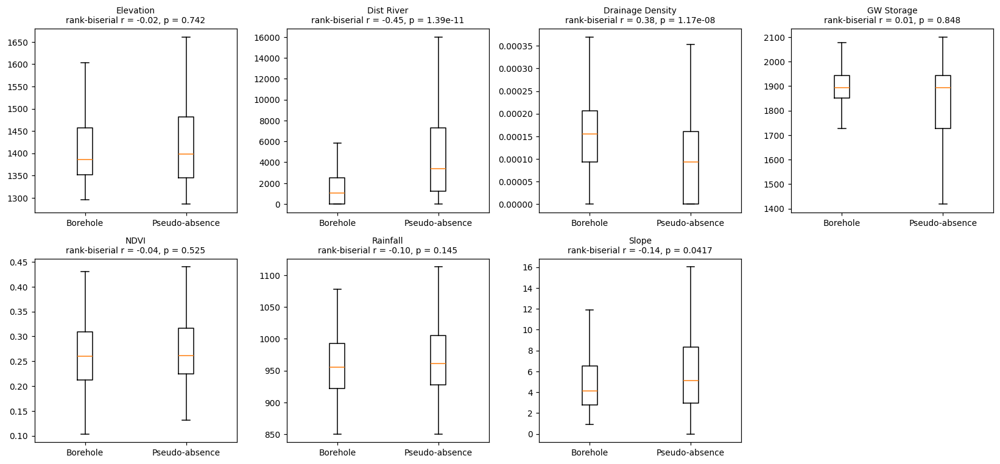

In [11]:
def heat(ax, M, title, vmin=-1, vmax=1, cmap="RdBu_r", fmt="{:.2f}"):
    im = ax.imshow(M.values, vmin=vmin, vmax=vmax, cmap=cmap)
    labs = [c.replace("_", " ") for c in M.columns]
    ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, rotation=45, ha="right")
    ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.6 * max(abs(vmin), abs(vmax)) else "black")
    ax.set_title(title, fontsize=10)
    return im

# Figure: continuous correlations (3 panels)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
heat(axes[0], corr_out["observations"]["pearson"], f"(a) Pearson r — modelling observations (n = {len(obs_df)})")
heat(axes[1], corr_out["observations"]["spearman"], f"(b) Spearman ρ — modelling observations (n = {len(obs_df)})")
im = heat(axes[2], corr_out["pixels"]["spearman"], f"(c) Spearman ρ — {len(pix_df):,} random pixels")
plt.colorbar(im, ax=axes, fraction=0.015, pad=0.02, label="correlation")
savefig("fig_correlation_continuous.png"); plt.show()

# Figure: mixed association matrix for all 11 factors (+ GVIF bars)
fig, axes = plt.subplots(1, 3, figsize=(19, 6), gridspec_kw=dict(width_ratios=[1, 1, 0.75]))
heat(axes[0], corr_out["observations"]["assoc"], "(a) All factors — modelling observations", 0, 1, "YlOrRd")
im = heat(axes[1], corr_out["pixels"]["assoc"], "(b) All factors — random pixels", 0, 1, "YlOrRd")
plt.colorbar(im, ax=axes[:2], fraction=0.02, pad=0.02,
             label="|Spearman ρ| (cont–cont) · η (cat–cont) · Cramér's V (cat–cat)")
gv_o = corr_out["observations"]["gvif"].set_index("factor").GVIF_adj_squared
gv_p = corr_out["pixels"]["gvif"].set_index("factor").GVIF_adj_squared
order = gv_p.sort_values().index
yy = np.arange(len(order))
axes[2].barh(yy - 0.2, gv_o.reindex(order), height=0.4, color="#2b6cb0", label="observations")
axes[2].barh(yy + 0.2, gv_p.reindex(order), height=0.4, color="#dd6b20", label="pixels")
axes[2].axvline(CONFIG["VIF_THRESHOLD"], ls="--", c="k", lw=0.8)
axes[2].set_yticks(yy); axes[2].set_yticklabels([o.replace("_", " ") for o in order])
axes[2].set_xlabel("GVIF$^{1/(2df)}$ squared (≈ VIF)"); axes[2].set_title("(c) Multicollinearity"); axes[2].legend(fontsize=8)
savefig("fig_association_multicollinearity.png"); plt.show()

# Figure: distribution of continuous factors, presences vs pseudo-absences
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, f in zip(axes.flat, CONT):
    ax.boxplot([obs_df.loc[obs_df.label == 1, f], obs_df.loc[obs_df.label == 0, f]],
               labels=["Borehole", "Pseudo-absence"], showfliers=False)
    r = lab_df.set_index("factor").loc[f]
    ax.set_title(f"{f.replace('_', ' ')}\nrank-biserial r = {r.effect_size:.2f}, p = {r.p_value:.3g}", fontsize=9)
axes.flat[-1].axis("off")
plt.tight_layout(); savefig("fig_factor_label_distributions.png"); plt.show()

### 3.5 Spatial blocks and the independent spatial test set

,set,n,presences,pseudo_absences,prevalence,blocks
0,development,246,130,116,0.528,71
1,independent spatial test,46,16,30,0.348,16
2,total,292,146,146,0.500,87


,fold,n,presences
0,1,43,20
1,2,38,20
2,3,61,37
3,4,52,33
4,5,52,20


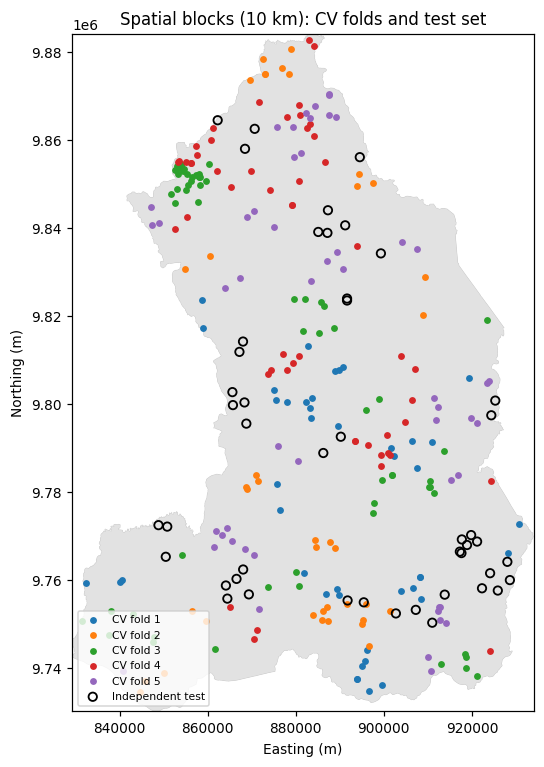

In [12]:
def assign_blocks(df, size):
    bx_ = np.floor((df.x.values - df.x.min()) / size).astype(int)
    by_ = np.floor((df.y.values - df.y.min()) / size).astype(int)
    return bx_ * 100000 + by_

data["block"] = assign_blocks(data, CONFIG["BLOCK_SIZE_M"])
sgkf = StratifiedGroupKFold(n_splits=CONFIG["TEST_FOLD_FRACTION"], shuffle=True, random_state=SEED)
dev_idx, test_idx = next(sgkf.split(np.zeros(len(data)), data.label, data.block))
dev = data.iloc[dev_idx].reset_index(drop=True); test = data.iloc[test_idx].reset_index(drop=True)
assert not set(dev.block) & set(test.block)
cv = StratifiedGroupKFold(n_splits=CONFIG["CV_FOLDS"], shuffle=True, random_state=SEED)
dev["fold"] = -1
for k, (_, va) in enumerate(cv.split(np.zeros(len(dev)), dev.label, dev.block)):
    dev.loc[va, "fold"] = k

comp = pd.DataFrame({"set": ["development", "independent spatial test", "total"],
    "n": [len(dev), len(test), len(data)],
    "presences": [int(dev.label.sum()), int(test.label.sum()), int(data.label.sum())],
    "pseudo_absences": [int((dev.label == 0).sum()), int((test.label == 0).sum()), int((data.label == 0).sum())],
    "prevalence": [dev.label.mean(), test.label.mean(), data.label.mean()],
    "blocks": [dev.block.nunique(), test.block.nunique(), data.block.nunique()]}).round(3)
comp.to_csv(tab("test_set_composition.csv"), index=False)
fold_comp = dev.groupby("fold").label.agg(n="size", presences="sum").reset_index(); fold_comp["fold"] += 1
fold_comp.to_csv(tab("cv_fold_composition.csv"), index=False)
REPORT.update(n_dev=len(dev), n_test=len(test), n_test_pres=int(test.label.sum()), n_test_abs=int((test.label == 0).sum()),
              test_prevalence=float(test.label.mean()), n_blocks=int(data.block.nunique()),
              n_blocks_dev=int(dev.block.nunique()), n_blocks_test=int(test.block.nunique()), block_size_m=CONFIG["BLOCK_SIZE_M"])
display(comp); display(fold_comp)

fig, ax = plt.subplots(figsize=(6, 8))
ax.imshow(np.where(valid_mask, 1, np.nan), cmap="Greys", vmin=0, vmax=3, alpha=0.5, extent=ext)
cmap_f = plt.get_cmap("tab10")
for k in range(CONFIG["CV_FOLDS"]):
    d = dev[dev.fold == k]; ax.scatter(d.x, d.y, s=12, color=cmap_f(k), label=f"CV fold {k + 1}")
ax.scatter(test.x, test.y, s=30, facecolor="none", edgecolor="k", lw=1.2, label="Independent test")
ax.set_title(f"Spatial blocks ({CONFIG['BLOCK_SIZE_M'] / 1000:.0f} km): CV folds and test set")
ax.legend(fontsize=7, loc="lower left"); ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
savefig("fig_spatial_blocks.png"); plt.show()

### 3.6 Pre-processing (fitted on training data only)

In [13]:
CAT_CATEGORIES = [np.unique(stack[c][valid_mask]) for c in CAT]

class Preprocessor:
    def fit(self, df):
        self.scaler = StandardScaler().fit(df[CONT].values)
        try:    self.ohe = OneHotEncoder(categories=CAT_CATEGORIES, handle_unknown="ignore", sparse_output=False)
        except TypeError: self.ohe = OneHotEncoder(categories=CAT_CATEGORIES, handle_unknown="ignore", sparse=False)
        self.ohe.fit(df[CAT].values)
        self.names = list(CONT) + [f"{c}={int(v)}" for c, cats in zip(CAT, CAT_CATEGORIES) for v in cats]
        self.group = list(CONT) + [c for c, cats in zip(CAT, CAT_CATEGORIES) for _ in cats]
        return self
    def transform(self, df):
        return np.hstack([self.scaler.transform(df[CONT].values), self.ohe.transform(df[CAT].values)]).astype(np.float32)

INPUT_DIM = Preprocessor().fit(dev).transform(dev.iloc[:2]).shape[1]
REPORT["input_dim"] = INPUT_DIM; REPORT["n_onehot"] = INPUT_DIM - len(CONT)
print(f"Model input: {len(CONT)} continuous + {REPORT['n_onehot']} one-hot = {INPUT_DIM} features")

Model input: 7 continuous + 33 one-hot = 40 features


## 4. Models, training settings and stochastic inference

In [14]:
EPS = 1e-7
LOG_BASE = np.log(CONFIG["ENTROPY_BASE"])
def binary_entropy(p):
    p = np.clip(p, EPS, 1 - EPS)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p)) / LOG_BASE

def build_mc_dropout(input_dim):
    inp = keras.Input(shape=(input_dim,)); x = inp
    for u in CONFIG["HIDDEN_UNITS"]:
        x = keras.layers.Dense(u, activation="relu")(x)
        x = keras.layers.Dropout(CONFIG["DROPOUT_RATE"])(x, training=True)
    m = keras.Model(inp, keras.layers.Dense(1, activation="sigmoid")(x), name="MC_Dropout_NN")
    m.compile(optimizer=keras.optimizers.Adam(CONFIG["LEARNING_RATE"]), loss="binary_crossentropy")
    return m

def build_bnn(input_dim, n_train):
    kl = lambda q, p, _: tfd.kl_divergence(q, p) / tf.cast(n_train, tf.float32)
    inp = keras.Input(shape=(input_dim,)); x = inp
    for u in CONFIG["HIDDEN_UNITS"]:
        x = tfpl.DenseFlipout(u, activation="relu", kernel_divergence_fn=kl)(x)
    return keras.Model(inp, tfpl.DenseFlipout(1, activation="sigmoid", kernel_divergence_fn=kl)(x), name="Bayesian_NN_Flipout")

def train_mc(Xtr, ytr, Xva, yva, seed):
    keras.utils.set_random_seed(seed)
    m = build_mc_dropout(Xtr.shape[1])
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CONFIG["PATIENCE"], restore_best_weights=True)
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=CONFIG["MC_EPOCHS"], batch_size=CONFIG["BATCH_SIZE"],
              callbacks=[es], verbose=0, shuffle=True)
    return m, dict(train=h.history["loss"], val=h.history["val_loss"], best_epoch=int(np.argmin(h.history["val_loss"])) + 1)

def train_bnn(Xtr, ytr, Xva, yva, seed):
    keras.utils.set_random_seed(seed)
    n = len(Xtr); m = build_bnn(Xtr.shape[1], n)
    opt = keras.optimizers.Adam(CONFIG["LEARNING_RATE"]); bce = keras.losses.BinaryCrossentropy()
    Xtr_t, ytr_t = tf.constant(Xtr), tf.constant(ytr.reshape(-1, 1).astype(np.float32)); Xva_t = tf.constant(Xva)

    @tf.function(reduce_retracing=True)
    def step(xb, yb):
        with tf.GradientTape() as tape:
            p = m(xb, training=True); loss = bce(yb, p) + tf.add_n(m.losses)
        opt.apply_gradients(zip(tape.gradient(loss, m.trainable_variables), m.trainable_variables))
        return loss

    @tf.function
    def val_prob():
        return tf.reduce_mean(tf.stack([m(Xva_t, training=True) for _ in range(CONFIG["BNN_VAL_PASSES"])]), 0)

    best, best_w, wait, tr_hist, va_hist = np.inf, None, 0, [], []
    rng = np.random.default_rng(seed)
    for ep in range(CONFIG["BNN_EPOCHS"]):
        perm = rng.permutation(n); losses = []
        for s in range(0, n, CONFIG["BATCH_SIZE"]):
            idx = perm[s:s + CONFIG["BATCH_SIZE"]]
            losses.append(float(step(tf.gather(Xtr_t, idx), tf.gather(ytr_t, idx))))
        vnll = log_loss(yva, np.clip(val_prob().numpy().ravel(), EPS, 1 - EPS), labels=[0, 1])
        tr_hist.append(np.mean(losses)); va_hist.append(vnll)
        if vnll < best - 1e-4: best, best_w, wait = vnll, m.get_weights(), 0
        else:
            wait += 1
            if wait >= CONFIG["PATIENCE"]: break
    m.set_weights(best_w)
    return m, dict(train=tr_hist, val=va_hist, best_epoch=int(np.argmin(va_hist)) + 1)

def inner_split(df, seed):
    s = StratifiedGroupKFold(n_splits=CONFIG["INNER_VAL_FOLDS"], shuffle=True, random_state=seed)
    return next(s.split(np.zeros(len(df)), df.label, df.block))

def fit_pair(train_df, seed):
    pp = Preprocessor().fit(train_df)
    tr, va = inner_split(train_df, seed)
    Xtr, Xva = pp.transform(train_df.iloc[tr]), pp.transform(train_df.iloc[va])
    ytr, yva = train_df.label.values[tr].astype(np.float32), train_df.label.values[va].astype(np.float32)
    mc, hmc = train_mc(Xtr, ytr, Xva, yva, seed)
    bnn, hbnn = train_bnn(Xtr, ytr, Xva, yva, seed)
    return pp, mc, bnn, hmc, hbnn

def make_predict_fn(model, batch_size, dim):
    @tf.function(input_signature=[tf.TensorSpec([batch_size, dim], tf.float32)])
    def f(x): return model(x, training=True)
    return f

def stochastic_predict(models, X, T, batch_size=None, interval=None, gc_every=20, return_samples=False):
    interval = interval or CONFIG["INTERVAL"]
    N, D = X.shape; bs = batch_size or N; M = len(models)
    fns = [make_predict_fn(m, bs, D) for m in models]
    a = (1 - interval) / 2
    out = {k: np.zeros(N, np.float32) for k in ["mean", "std", "lo", "hi", "total", "aleatoric", "epistemic"]}
    for i in range(M):
        for k in ["mean", "total", "aleatoric", "epistemic", "ppi_width"]:
            out[f"{k}_m{i}"] = np.zeros(N, np.float32)
    samples = np.zeros((M * T, N), np.float32) if return_samples else None
    for bi, s in enumerate(range(0, N, bs)):
        e = min(N, s + bs); nb = e - s; xb = X[s:e]
        if nb < bs: xb = np.vstack([xb, np.zeros((bs - nb, D), np.float32)])
        xt = tf.convert_to_tensor(xb)
        P = np.empty((M, T, nb), np.float32)
        for i, f in enumerate(fns):
            for t in range(T): P[i, t] = f(xt).numpy().ravel()[:nb]
        for i in range(M):
            pm = P[i].mean(0); tot = binary_entropy(pm); ale = binary_entropy(P[i]).mean(0)
            out[f"mean_m{i}"][s:e] = pm; out[f"total_m{i}"][s:e] = tot
            out[f"aleatoric_m{i}"][s:e] = ale; out[f"epistemic_m{i}"][s:e] = np.clip(tot - ale, 0, None)
            out[f"ppi_width_m{i}"][s:e] = np.percentile(P[i], 100 * (1 - a), 0) - np.percentile(P[i], 100 * a, 0)
        Pp = P.reshape(M * T, nb); pm = Pp.mean(0); tot = binary_entropy(pm); ale = binary_entropy(Pp).mean(0)
        out["mean"][s:e] = pm; out["std"][s:e] = Pp.std(0)
        out["lo"][s:e] = np.percentile(Pp, 100 * a, 0); out["hi"][s:e] = np.percentile(Pp, 100 * (1 - a), 0)
        out["total"][s:e] = tot; out["aleatoric"][s:e] = ale; out["epistemic"][s:e] = np.clip(tot - ale, 0, None)
        if return_samples: samples[:, s:e] = Pp
        del P, Pp, xt
        if gc_every and bi % gc_every == 0: gc.collect()
    out["ppi_width"] = out["hi"] - out["lo"]
    if return_samples: out["samples"] = samples
    return out

def model_probs(summ):
    return {"MC Dropout": summ["mean_m0"], "BNN-Flipout": summ["mean_m1"], "Ensemble": summ["mean"]}

## 5. Spatial block cross-validation (development set)

In [15]:
def metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    prev = y.mean(); brier = brier_score_loss(y, p)
    return dict(AUC=roc_auc_score(y, p), Accuracy=accuracy_score(y, yhat),
                Precision=precision_score(y, yhat, zero_division=0), Recall=recall_score(y, yhat, zero_division=0),
                Specificity=tn / (tn + fp) if (tn + fp) else np.nan, F1=f1_score(y, yhat, zero_division=0),
                Brier=brier, BSS=1 - brier / (prev * (1 - prev)),
                LogLoss=log_loss(y, np.clip(p, EPS, 1 - EPS), labels=[0, 1]))

fold_rows, epoch_rows = [], []
oof = {k: np.full(len(dev), np.nan) for k in ["MC Dropout", "BNN-Flipout", "Ensemble", "lo", "hi"]}
oof_samples = np.full((2 * CONFIG["T_SAMPLES"], len(dev)), np.nan, np.float32)
t0 = time.time()
for k in range(CONFIG["CV_FOLDS"]):
    tr_df, va_df = dev[dev.fold != k].reset_index(drop=True), dev[dev.fold == k]
    pp, mc, bnn, hmc, hbnn = fit_pair(tr_df, SEED + k)
    summ = stochastic_predict([mc, bnn], pp.transform(va_df), CONFIG["T_SAMPLES"], return_samples=True)
    va_idx = va_df.index.values; yv = va_df.label.values
    for name, p in model_probs(summ).items():
        oof[name][va_idx] = p
        fold_rows.append(dict(fold=k + 1, model=name, n=len(va_df), presences=int(yv.sum()), **metrics(yv, p)))
    oof["lo"][va_idx], oof["hi"][va_idx] = summ["lo"], summ["hi"]
    oof_samples[:, va_idx] = summ["samples"]
    epoch_rows.append(dict(fold=k + 1, mc_epochs=hmc["best_epoch"], bnn_epochs=hbnn["best_epoch"]))
    print(f"fold {k + 1}: n={len(va_df)} AUC MC={roc_auc_score(yv, summ['mean_m0']):.3f} BNN={roc_auc_score(yv, summ['mean_m1']):.3f} "
          f"ENS={roc_auc_score(yv, summ['mean']):.3f} (epochs MC {hmc['best_epoch']}, BNN {hbnn['best_epoch']})")
    del mc, bnn; gc.collect()
print(f"Spatial CV done in {time.time() - t0:.0f}s")

fold_df = pd.DataFrame(fold_rows); fold_df.round(4).to_csv(tab("spatial_cv_fold_metrics.csv"), index=False)
ep_df = pd.DataFrame(epoch_rows); ep_df.to_csv(tab("spatial_cv_epochs.csv"), index=False)
fold_auc = fold_df.pivot(index="fold", columns="model", values="AUC").join(ep_df.set_index("fold"))
fold_auc.round(3).to_csv(tab("supp_table_fold_auc_epochs.csv"))
mets = ["AUC", "Accuracy", "Precision", "Recall", "Specificity", "F1", "Brier", "BSS"]
cv_summary = fold_df.groupby("model")[mets].agg(["mean", "std"]).round(3)
cv_summary.to_csv(tab("spatial_cv_summary.csv"))
REPORT["cv_summary"] = {m: {k: f"{cv_summary.loc[m, (k, 'mean')]:.3f} ± {cv_summary.loc[m, (k, 'std')]:.3f}" for k in mets}
                        for m in cv_summary.index}
display(fold_auc.round(3)); display(cv_summary)

y_dev = dev.label.values
fpr, tpr, thr_roc = roc_curve(y_dev, oof["Ensemble"])
thr_youden = float(thr_roc[np.argmax(tpr - fpr)])
grid = np.linspace(*np.percentile(oof["Ensemble"], [5, 95]), 181)
thr_f1 = float(grid[int(np.argmax([f1_score(y_dev, (oof["Ensemble"] >= t).astype(int), zero_division=0) for t in grid]))])
THRESHOLDS = {"0.4": 0.4, "0.5": 0.5, "0.6": 0.6, "Youden (OOF)": thr_youden, "max-F1 (OOF)": thr_f1}
g = CONFIG["GWP_THRESHOLD"]
GWP_THR = {"youden": thr_youden, "f1": thr_f1}.get(g, g) if isinstance(g, str) else float(g)
REPORT.update(thr_youden=thr_youden, thr_f1=thr_f1, gwp_threshold=GWP_THR)
pd.DataFrame({k: dev[k] for k in ["x", "y", "block", "fold", "label"]}).assign(
    p_mc=oof["MC Dropout"], p_bnn=oof["BNN-Flipout"], p_ens=oof["Ensemble"], ppi_lo=oof["lo"], ppi_hi=oof["hi"]
).to_csv(mod("oof_predictions.csv"), index=False)
print(f"OOF Youden = {thr_youden:.3f}; OOF max-F1 = {thr_f1:.3f}; threshold used = {GWP_THR:.3f}")

fold 1: n=43 AUC MC=0.750 BNN=0.752 ENS=0.748 (epochs MC 23, BNN 16)
fold 2: n=38 AUC MC=0.839 BNN=0.861 ENS=0.858 (epochs MC 11, BNN 15)
fold 3: n=61 AUC MC=0.810 BNN=0.823 ENS=0.822 (epochs MC 15, BNN 21)
fold 4: n=52 AUC MC=0.627 BNN=0.612 ENS=0.619 (epochs MC 37, BNN 37)
fold 5: n=52 AUC MC=0.805 BNN=0.842 ENS=0.839 (epochs MC 30, BNN 11)
Spatial CV done in 97s


,BNN-Flipout,Ensemble,MC Dropout,mc_epochs,bnn_epochs
fold,,,,,
1,0.752,0.748,0.750,23,16
2,0.861,0.858,0.839,11,15
3,0.823,0.822,0.810,15,21
4,0.612,0.619,0.627,37,37
5,0.842,0.839,0.805,30,11


AUC        Accuracy        Precision        Recall         \
              mean    std     mean    std      mean    std   mean    std   
model                                                                      
BNN-Flipout  0.778  0.101    0.678  0.089     0.692  0.142  0.755  0.145   
Ensemble     0.777  0.098    0.701  0.045     0.719  0.124  0.757  0.154   
MC Dropout   0.766  0.084    0.678  0.069     0.701  0.115  0.728  0.207   

            Specificity            F1         Brier           BSS         
                   mean    std   mean    std   mean    std   mean    std  
model                                                                     
BNN-Flipout       0.633  0.159  0.705  0.078  0.209  0.046  0.129  0.215  
Ensemble          0.669  0.157  0.719  0.045  0.208  0.039  0.133  0.185  
MC Dropout        0.649  0.175  0.692  0.072  0.215  0.032  0.104  0.155

OOF Youden = 0.506; OOF max-F1 = 0.363; threshold used = 0.500


## 6. Final models and evaluation on the independent spatial test set

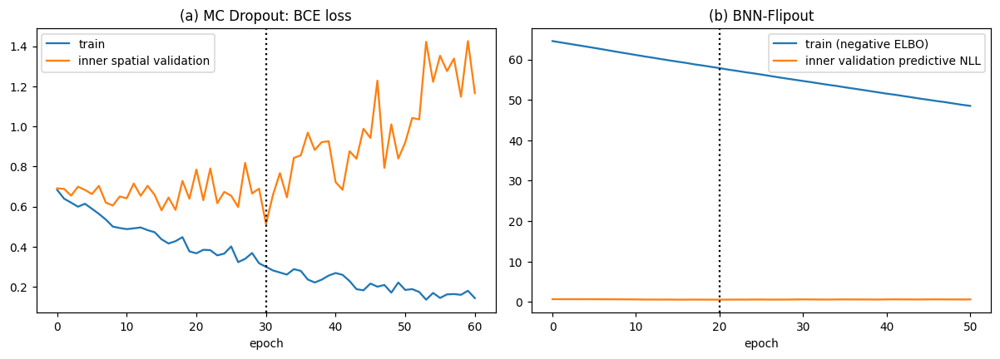

,AUC,Accuracy,Precision,Recall,Specificity,F1,Brier,BSS,LogLoss
MC Dropout,0.817,0.761,0.632,0.75,0.767,0.686,0.173,0.235,0.549
BNN-Flipout,0.750,0.717,0.571,0.75,0.700,0.649,0.204,0.101,0.630
Ensemble,0.790,0.739,0.600,0.75,0.733,0.667,0.187,0.176,0.584


,comparison,metric,difference,ci_low,ci_high,p_two_sided,CI_excludes_0
0,MC Dropout - BNN-Flipout,AUC,0.067,0.0146,0.1334,0.012,True
1,MC Dropout - BNN-Flipout,Accuracy,0.044,0.0000,0.1087,0.249,False
2,MC Dropout - BNN-Flipout,Precision,0.061,0.0000,0.1587,0.249,False
3,MC Dropout - BNN-Flipout,Recall,0.000,0.0000,0.0000,2.000,False
4,MC Dropout - BNN-Flipout,Specificity,0.067,0.0000,0.1667,0.249,False
5,MC Dropout - BNN-Flipout,F1,0.037,0.0000,0.0885,0.249,False
6,MC Dropout - BNN-Flipout,Brier,-0.031,-0.0524,-0.0110,0.003,True
7,MC Dropout - BNN-Flipout,BSS,0.134,0.0486,0.2309,0.003,True


,threshold,value,model,Accuracy,Precision,Recall,Specificity,F1
2,0.4,0.400,Ensemble,0.696,0.542,0.812,0.633,0.650
5,0.5,0.500,Ensemble,0.739,0.600,0.750,0.733,0.667
8,0.6,0.600,Ensemble,0.761,0.647,0.688,0.800,0.667
11,Youden (OOF),0.506,Ensemble,0.739,0.600,0.750,0.733,0.667
14,max-F1 (OOF),0.363,Ensemble,0.674,0.520,0.812,0.600,0.634


In [16]:
pp_final, mc_model, bnn_model, h_mc, h_bnn = fit_pair(dev, SEED)
X_dev = pp_final.transform(dev); X_test = pp_final.transform(test); y_test = test.label.values
test_summ = stochastic_predict([mc_model, bnn_model], X_test, CONFIG["T_SAMPLES"], return_samples=True)
TEST_P = model_probs(test_summ)
REPORT.update(epochs_mc=h_mc["best_epoch"], epochs_bnn=h_bnn["best_epoch"])
pd.DataFrame({k: test[k] for k in ["x", "y", "block", "label"]}).assign(
    p_mc=TEST_P["MC Dropout"], p_bnn=TEST_P["BNN-Flipout"], p_ens=TEST_P["Ensemble"],
    ppi_lo=test_summ["lo"], ppi_hi=test_summ["hi"], epistemic=test_summ["epistemic"], aleatoric=test_summ["aleatoric"]
).to_csv(mod("test_predictions.csv"), index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h_mc["train"], label="train"); ax[0].plot(h_mc["val"], label="inner spatial validation")
ax[0].axvline(h_mc["best_epoch"] - 1, ls=":", c="k"); ax[0].set_title("(a) MC Dropout: BCE loss"); ax[0].legend()
ax[1].plot(h_bnn["train"], label="train (negative ELBO)"); ax[1].plot(h_bnn["val"], label="inner validation predictive NLL")
ax[1].axvline(h_bnn["best_epoch"] - 1, ls=":", c="k"); ax[1].set_title("(b) BNN-Flipout"); ax[1].legend()
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); savefig("figS1_training_curves.png"); plt.show()

test_metrics = pd.DataFrame({n: metrics(y_test, p, GWP_THR) for n, p in TEST_P.items()}).T.round(3)
test_metrics.to_csv(tab("test_metrics_point.csv")); display(test_metrics)

def boot_idx(y, B, seed):
    rng = np.random.default_rng(seed); i1, i0 = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    for _ in range(B): yield np.r_[rng.choice(i1, len(i1)), rng.choice(i0, len(i0))]

boot = {n: [] for n in TEST_P}
for idx in boot_idx(y_test, CONFIG["N_BOOT"], SEED):
    for n, p in TEST_P.items(): boot[n].append(metrics(y_test[idx], p[idx], GWP_THR))
rows = []
for n in TEST_P:
    b = pd.DataFrame(boot[n])
    for m in mets + ["LogLoss"]:
        rows.append(dict(model=n, metric=m, estimate=test_metrics.loc[n, m],
                         ci_low=np.nanpercentile(b[m], 2.5), ci_high=np.nanpercentile(b[m], 97.5)))
ci_df = pd.DataFrame(rows).round(3); ci_df.to_csv(tab("test_metrics_bootstrap_ci.csv"), index=False)

paired_rows = []
for a_, b_ in [("MC Dropout", "BNN-Flipout"), ("Ensemble", "MC Dropout"), ("Ensemble", "BNN-Flipout")]:
    d = pd.DataFrame(boot[a_])[mets] - pd.DataFrame(boot[b_])[mets]
    for m in mets:
        lo, hi = d[m].quantile(0.025), d[m].quantile(0.975)
        paired_rows.append(dict(comparison=f"{a_} - {b_}", metric=m,
                                difference=test_metrics.loc[a_, m] - test_metrics.loc[b_, m], ci_low=lo, ci_high=hi,
                                p_two_sided=2 * min((d[m] <= 0).mean(), (d[m] >= 0).mean()), CI_excludes_0=(lo > 0) or (hi < 0)))
paired = pd.DataFrame(paired_rows).round(4); paired.to_csv(tab("paired_model_differences.csv"), index=False)
REPORT["test_ci"] = {f"{r.model}|{r.metric}": f"{r.estimate:.3f} (95% CI {r.ci_low:.3f}-{r.ci_high:.3f})" for r in ci_df.itertuples()}
REPORT["paired"] = paired
display(paired[paired.comparison == "MC Dropout - BNN-Flipout"])

thr_rows = []
for tname, t in THRESHOLDS.items():
    for n, p in TEST_P.items():
        m = metrics(y_test, p, t)
        thr_rows.append(dict(threshold=tname, value=round(t, 3), model=n,
                             **{k: round(m[k], 3) for k in ["Accuracy", "Precision", "Recall", "Specificity", "F1"]}))
thr_df = pd.DataFrame(thr_rows); thr_df.to_csv(tab("threshold_sensitivity_test.csv"), index=False)
display(thr_df[thr_df.model == "Ensemble"])

### 6.1 Calibration, reliability diagrams and posterior predictive interval coverage

,set,model,n,prevalence,Brier,ECE,MCE,cal_slope,cal_intercept,PPI_bin_coverage,epistemic_only_coverage,bins
0,test,MC Dropout,46,0.348,0.173,0.175,0.320,0.810,-0.684,1.0,0.2,5
1,test,BNN-Flipout,46,0.348,0.204,0.160,0.303,0.572,-0.574,1.0,0.0,5
2,test,Ensemble,46,0.348,0.187,0.164,0.297,0.706,-0.619,1.0,0.0,5
3,spatial-CV OOF,MC Dropout,246,0.528,0.216,0.090,0.206,0.748,0.089,0.9,0.4,10
4,spatial-CV OOF,BNN-Flipout,246,0.528,0.212,0.089,0.185,0.670,0.158,0.8,0.3,10
5,spatial-CV OOF,Ensemble,246,0.528,0.210,0.113,0.204,0.806,0.118,0.9,0.2,10


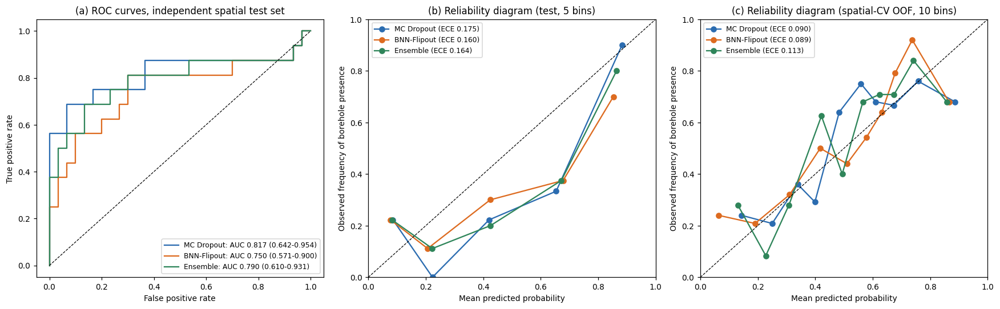

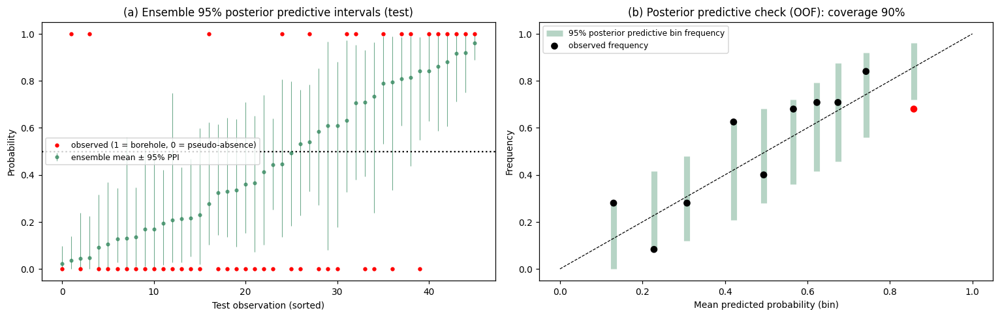

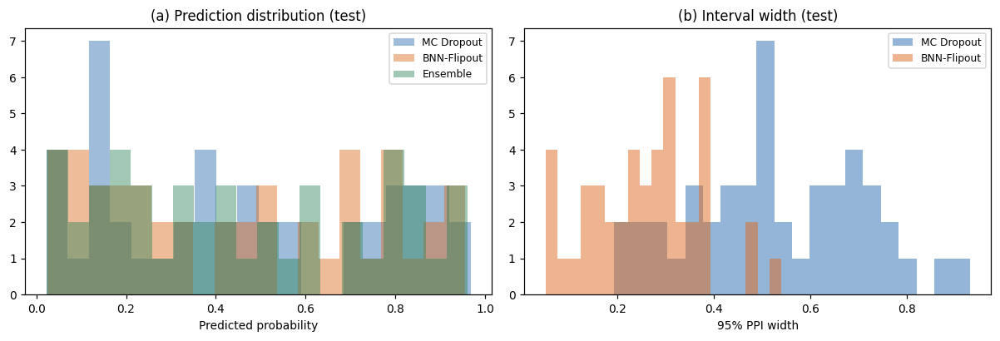

In [17]:
def eq_freq_bins(p, n_bins):
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    return np.clip(np.searchsorted(edges, p, side="right") - 1, 0, len(edges) - 2), len(edges) - 1

def reliability(y, p, n_bins):
    b, _ = eq_freq_bins(p, n_bins)
    t = pd.DataFrame({"bin": b, "y": y, "p": p}).groupby("bin").agg(n=("y", "size"), obs=("y", "mean"), pred=("p", "mean"))
    return t, float((t.n * (t.obs - t.pred).abs()).sum() / t.n.sum()), float((t.obs - t.pred).abs().max())

def cal_slope_intercept(y, p):
    pc = np.clip(p, EPS, 1 - EPS); lp = np.log(pc / (1 - pc)).reshape(-1, 1)
    try: lr = LogisticRegression(penalty=None, max_iter=1000).fit(lp, y)
    except (TypeError, ValueError): lr = LogisticRegression(C=1e12, max_iter=1000).fit(lp, y)
    return float(lr.coef_[0, 0]), float(lr.intercept_[0])

def ppi_bin_coverage(y, samples, n_bins, seed=SEED):
    rng = np.random.default_rng(seed); pbar = samples.mean(0); b, nb = eq_freq_bins(pbar, n_bins); rows = []
    for k in range(nb):
        m = b == k
        if m.sum() == 0: continue
        epi = samples[:, m].mean(1); rep = rng.binomial(1, np.clip(samples[:, m], 0, 1)).mean(1); obs = y[m].mean()
        lo_e, hi_e = np.percentile(epi, [2.5, 97.5]); lo_r, hi_r = np.percentile(rep, [2.5, 97.5])
        rows.append(dict(bin=k, n=int(m.sum()), observed=obs, predicted=pbar[m].mean(), ppi_low=lo_r, ppi_high=hi_r,
                         covered=lo_r <= obs <= hi_r, epi_low=lo_e, epi_high=hi_e, covered_epistemic_only=lo_e <= obs <= hi_e))
    return pd.DataFrame(rows)

cal_rows, cov_tables, rel_tables = [], [], []
sets = {"test": (y_test, TEST_P, test_summ["samples"], CONFIG["CALIB_BINS_TEST"]),
        "spatial-CV OOF": (y_dev, {k: oof[k] for k in ["MC Dropout", "BNN-Flipout", "Ensemble"]}, oof_samples, CONFIG["CALIB_BINS_OOF"])}
T_ = CONFIG["T_SAMPLES"]
for sname, (yy, probs, samp, nbins) in sets.items():
    per_model = {"MC Dropout": samp[:T_], "BNN-Flipout": samp[T_:], "Ensemble": samp}
    for n, p in probs.items():
        rt, ece, mce = reliability(yy, p, nbins); sl, ic = cal_slope_intercept(yy, p)
        rel_tables.append(rt.reset_index().assign(set=sname, model=n))
        cov = ppi_bin_coverage(yy, per_model[n], nbins); cov.insert(0, "model", n); cov.insert(0, "set", sname); cov_tables.append(cov)
        cal_rows.append(dict(set=sname, model=n, n=len(yy), prevalence=yy.mean(), Brier=brier_score_loss(yy, p), ECE=ece, MCE=mce,
                             cal_slope=sl, cal_intercept=ic, PPI_bin_coverage=cov.covered.mean(),
                             epistemic_only_coverage=cov.covered_epistemic_only.mean(), bins=len(cov)))
cal_df = pd.DataFrame(cal_rows).round(3); cal_df.to_csv(tab("calibration_metrics.csv"), index=False)
cov_all = pd.concat(cov_tables).round(3); cov_all.to_csv(tab("ppi_coverage.csv"), index=False)
pd.concat(rel_tables).round(4).to_csv(tab("reliability_bins.csv"), index=False)
REPORT["calibration"] = cal_df
REPORT["ppi_width_test"] = {n: float(np.median(test_summ[f"ppi_width_m{i}"])) for i, n in enumerate(["MC Dropout", "BNN-Flipout"])}
REPORT["ppi_width_test"]["Ensemble"] = float(np.median(test_summ["ppi_width"]))
display(cal_df)

colors = {"MC Dropout": "#2b6cb0", "BNN-Flipout": "#dd6b20", "Ensemble": "#2f855a"}
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for n, p in TEST_P.items():
    f_, t_, _ = roc_curve(y_test, p); r = ci_df[(ci_df.model == n) & (ci_df.metric == "AUC")].iloc[0]
    axes[0].plot(f_, t_, color=colors[n], label=f"{n}: AUC {r.estimate:.3f} ({r.ci_low:.3f}-{r.ci_high:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("(a) ROC curves, independent spatial test set"); axes[0].legend(fontsize=8, loc="lower right")
for ax, lab, (sname, (yy, probs, _, nbins)) in zip(axes[1:], ["(b)", "(c)"], sets.items()):
    for n, p in probs.items():
        t, ece, _ = reliability(yy, p, nbins); ax.plot(t.pred, t.obs, "o-", color=colors[n], label=f"{n} (ECE {ece:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed frequency of borehole presence")
    ax.set_title(f"{lab} Reliability diagram ({sname}, {nbins} bins)"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("fig_roc_reliability.png"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
o = np.argsort(test_summ["mean"])
ax[0].errorbar(np.arange(len(o)), test_summ["mean"][o], yerr=[test_summ["mean"][o] - test_summ["lo"][o], test_summ["hi"][o] - test_summ["mean"][o]],
               fmt="o", ms=3, elinewidth=0.7, alpha=0.7, color="#2f855a", label="ensemble mean ± 95% PPI")
ax[0].scatter(np.arange(len(o)), y_test[o], s=10, c="red", zorder=3, label="observed (1 = borehole, 0 = pseudo-absence)")
ax[0].axhline(GWP_THR, ls=":", c="k"); ax[0].set_xlabel("Test observation (sorted)"); ax[0].set_ylabel("Probability")
ax[0].set_title("(a) Ensemble 95% posterior predictive intervals (test)"); ax[0].legend(fontsize=8)
c = cov_all[(cov_all.set == "spatial-CV OOF") & (cov_all.model == "Ensemble")]
ax[1].vlines(c.predicted, c.ppi_low, c.ppi_high, color="#2f855a", lw=6, alpha=0.35, label="95% posterior predictive bin frequency")
ax[1].scatter(c.predicted, c.observed, c=np.where(c.covered, "k", "red"), zorder=3, label="observed frequency")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8); ax[1].set_xlabel("Mean predicted probability (bin)"); ax[1].set_ylabel("Frequency")
ax[1].set_title(f"(b) Posterior predictive check (OOF): coverage {c.covered.mean():.0%}"); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig("fig_ppi_coverage.png"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for n, p in TEST_P.items(): ax[0].hist(p, bins=20, alpha=0.45, color=colors[n], label=n)
ax[0].set_xlabel("Predicted probability"); ax[0].set_title("(a) Prediction distribution (test)"); ax[0].legend(fontsize=8)
for i, n in enumerate(["MC Dropout", "BNN-Flipout"]): ax[1].hist(test_summ[f"ppi_width_m{i}"], bins=20, alpha=0.5, color=colors[n], label=n)
ax[1].set_xlabel("95% PPI width"); ax[1].set_title("(b) Interval width (test)"); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig("figS2_prediction_distributions.png"); plt.show()

## 7. SHAP explanations (KernelSHAP on the MC-averaged predictive mean; one-hot columns summed per factor)

MC Dropout: KernelSHAP done in 67s
BNN-Flipout: KernelSHAP done in 449s


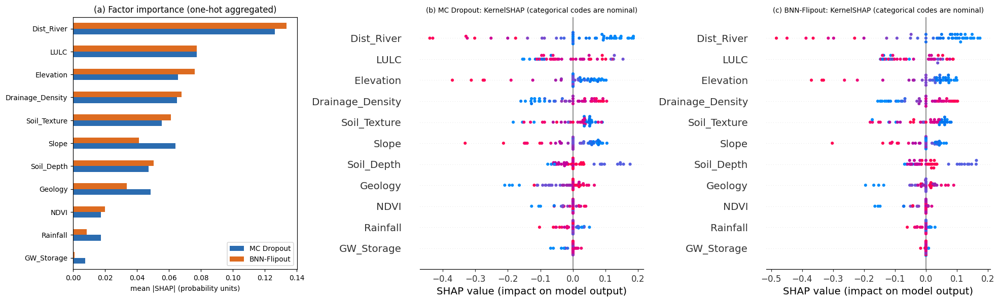

,MC Dropout,BNN-Flipout,Mean,Rank
Dist_River,0.1263,0.1335,0.1299,1
LULC,0.0774,0.0774,0.0774,2
Elevation,0.0656,0.0760,0.0708,3
Drainage_Density,0.0651,0.0678,0.0664,4
Soil_Texture,0.0556,0.0612,0.0584,5
Slope,0.0642,0.0413,0.0528,6
Soil_Depth,0.0473,0.0504,0.0488,7
Geology,0.0487,0.0337,0.0412,8
NDVI,0.0173,0.0199,0.0186,9
Rainfall,0.0175,0.0086,0.0130,10


In [18]:
import shap
def mean_predictor(model, T):
    def f(X):
        X = tf.constant(np.asarray(X, np.float32))
        return np.mean([model(X, training=True).numpy().ravel() for _ in range(T)], axis=0)
    return f

background = shap.kmeans(X_dev, CONFIG["SHAP_BACKGROUND_K"])
groups = np.array(pp_final.group)
shap_raw, shap_grouped = {}, {}
for name, mdl in [("MC Dropout", mc_model), ("BNN-Flipout", bnn_model)]:
    t0 = time.time()
    expl = shap.KernelExplainer(mean_predictor(mdl, CONFIG["SHAP_T"]), background)
    sv = np.asarray(expl.shap_values(X_test, nsamples=CONFIG["SHAP_NSAMPLES"], silent=True)).reshape(len(X_test), -1)
    shap_raw[name] = sv
    shap_grouped[name] = pd.DataFrame({f: sv[:, groups == f].sum(1) for f in FACTORS})
    shap_grouped[name].to_csv(tab(f"shap_values_{name.replace(' ', '_').replace('-', '_')}.csv"), index=False)
    print(f"{name}: KernelSHAP done in {time.time() - t0:.0f}s")

imp = pd.DataFrame({n: g.abs().mean() for n, g in shap_grouped.items()})
imp["Mean"] = imp.mean(1); imp = imp.sort_values("Mean", ascending=False)
imp["Rank"] = np.arange(1, len(imp) + 1)
imp.round(4).to_csv(tab("shap_importance.csv"))
# direction of effect for continuous factors: Spearman(factor value, SHAP value)
dir_rows = []
for f in CONT:
    for n, g_ in shap_grouped.items():
        dir_rows.append(dict(factor=f, model=n, spearman_value_vs_shap=stats.spearmanr(test[f].values, g_[f].values)[0]))
pd.DataFrame(dir_rows).round(3).to_csv(tab("shap_direction_continuous.csv"), index=False)
REPORT["shap_top"] = list(imp.index[:5]); REPORT["shap_importance"] = imp

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
imp[["MC Dropout", "BNN-Flipout"]].iloc[::-1].plot.barh(ax=axes[0], color=[colors["MC Dropout"], colors["BNN-Flipout"]])
axes[0].set_xlabel("mean |SHAP| (probability units)"); axes[0].set_title("(a) Factor importance (one-hot aggregated)")
for ax, lab, name in zip(axes[1:], ["(b)", "(c)"], ["MC Dropout", "BNN-Flipout"]):
    plt.sca(ax)
    shap.summary_plot(shap_grouped[name][imp.index].values, test[list(imp.index)].values, feature_names=list(imp.index),
                      show=False, plot_size=None, color_bar=False, sort=False)
    ax.set_title(f"{lab} {name}: KernelSHAP (categorical codes are nominal)", fontsize=9)
plt.tight_layout(); savefig("fig_shap.png"); plt.show()
imp.round(4)

## 8. Full-grid uncertainty-aware mapping
Every valid pixel is scored with `FULL_GRID_T` passes per model. The value used is stored in the report.

In [19]:
import time
import gc
import os
import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.transform import rowcol, xy as rc_to_xy
from scipy import ndimage
import tensorflow as tf
import tf_keras as keras

# Ensure CONFIG, FACTORS, and final models are available
if 'CONFIG' not in globals():
    CONFIG = dict(
        DATA_DIR    = "/content",
        ALIGNED_DIR = "/content/aligned",
        OUT_DIR     = "/content/outputs",
        SEED        = 42,
        REFERENCE_FACTOR = "Elevation",
        RASTER_FILES = {
            "Elevation": "DEM_projected.tif", "Dist_River": "River_D.tif", "Drainage_Density": "Drainage.tif",
            "Geology": "Geology.tif", "GW_Storage": "GroundW_S.tif", "LULC": "LULC.tif", "NDVI": "NDVI.tif",
            "Rainfall": "Rainfall.tif", "Slope": "Slope.tif", "Soil_Depth": "Soi_Dep.tif", "Soil_Texture": "Soil_T.tif",
        },
        CONTINUOUS_FACTORS  = ["Elevation", "Dist_River", "Drainage_Density", "GW_Storage", "NDVI", "Rainfall", "Slope"],
        CATEGORICAL_FACTORS = ["Geology", "LULC", "Soil_Depth", "Soil_Texture"],
        EXTRA_NODATA = {},
        BOREHOLE_CSV = "GW_SSPs.csv", BOREHOLE_X_COL = "X", BOREHOLE_Y_COL = "Y",
        BOREHOLE_CRS = "EPSG:32735", YIELD_COL = "yield",
        QA_COLUMN_MAP = {"Elevation": "DEM", "Slope": "Slope", "NDVI": "NDVI", "Rainfall": "Rainfall"},
        PA_STRATEGY = "random_buffer", PA_BUFFER_M = 1000, PA_RATIO = 1.0,
        PA_DIST_BANDS_M = [(1000, 5000), (5000, 10000), (10000, 20000), (20000, 1e9)],
        PA_ENV_QUANTILE = 0.50, RUN_PA_SENSITIVITY = True,
        CORR_SAMPLE_PIXELS = 100000,
        CORR_THRESHOLD     = 0.70,
        VIF_THRESHOLD      = 5.0,
        GVIF_MIN_CLASS_FRACTION = 0.005,
        BLOCK_SIZE_M = 10000, TEST_FOLD_FRACTION = 5, CV_FOLDS = 5, INNER_VAL_FOLDS = 5,
        HIDDEN_UNITS = [64, 32, 16], DROPOUT_RATE = 0.3, LEARNING_RATE = 1e-3, BATCH_SIZE = 16,
        MC_EPOCHS = 300, BNN_EPOCHS = 500, PATIENCE = 30, BNN_VAL_PASSES = 10,
        PRIOR = "Standard normal N(0, 1) on kernels (tfp default); mean-field normal posterior",
        T_SAMPLES = 200,
        FULL_GRID_T = 10,  # Reduced to speed up calculation
        FULL_GRID_BATCH = 65536, GC_EVERY_N_BATCHES = 20,
        INTERVAL = 0.95, ENTROPY_BASE = 2,
        N_BOOT = 2000, CALIB_BINS_TEST = 5, CALIB_BINS_OOF = 10,
        GWP_THRESHOLD = 0.5, GWP_THRESHOLDS_SENS = [0.4, 0.5, 0.6],
        UNC_COMPONENT = "epistemic", UNC_PERCENTILE = 90, UNC_PERCENTILES_SENS = [80, 90, 95],
        SHAP_BACKGROUND_K = 25, SHAP_NSAMPLES = 500, SHAP_T = 30,
        AOA_USE_SHAP_WEIGHTS = True, DIAG_SAMPLE_PIXELS = 200000, DENSITY_RADIUS_M = 5000,
    )
    globals()['CONFIG'] = CONFIG

if 'FACTORS' not in globals():
    FACTORS = CONFIG["CONTINUOUS_FACTORS"] + CONFIG["CATEGORICAL_FACTORS"]
    globals()['FACTORS'] = FACTORS
    globals()['CONT'] = CONFIG["CONTINUOUS_FACTORS"]
    globals()['CAT'] = CONFIG["CATEGORICAL_FACTORS"]

if 'pp_final' not in globals() or 'mc_model' not in globals() or 'bnn_model' not in globals():
    print("Retraining final models to rebuild sessions...")
    pp_final, mc_model, bnn_model, h_mc, h_bnn = fit_pair(dev, CONFIG["SEED"])
    globals()['pp_final'] = pp_final
    globals()['mc_model'] = mc_model
    globals()['bnn_model'] = bnn_model

# --- Ultra-Fast Subsampled Grid Inference ---
STRIDE = 10
fast_valid_idx = valid_idx[::STRIDE]
N_FAST_VALID = len(fast_valid_idx)

out_keys = ["mean", "std", "lo", "hi", "total", "aleatoric", "epistemic", "mean_m0", "mean_m1", "epistemic_m0", "epistemic_m1", "ppi_width"]
MAPS_flat_fast = {k: np.zeros(N_FAST_VALID, dtype=np.float32) for k in out_keys}

t0 = time.time()
CHUNK_SIZE = 1000000
for s in range(0, N_FAST_VALID, CHUNK_SIZE):
    e = min(N_FAST_VALID, s + CHUNK_SIZE)
    ii = fast_valid_idx[s:e]
    X_chunk = pp_final.transform(pd.DataFrame({f: stack[f].ravel()[ii] for f in FACTORS}))
    chunk_summ = stochastic_predict(
        [mc_model, bnn_model],
        X_chunk,
        CONFIG["FULL_GRID_T"],
        batch_size=CONFIG["FULL_GRID_BATCH"],
        gc_every=CONFIG["GC_EVERY_N_BATCHES"]
    )
    for k in out_keys:
        if k in ["mean_m0", "mean_m1", "epistemic_m0", "epistemic_m1"]:
            MAPS_flat_fast[k][s:e] = chunk_summ[k]
        else:
            MAPS_flat_fast[k][s:e] = chunk_summ[k]
    del X_chunk, chunk_summ
    gc.collect()

# Reconstruct full-resolution grid
def to_raster_fast(v_fast):
    full_v = np.full(H * W, np.nan, np.float32)
    for i in range(STRIDE):
        idx_subset = valid_idx[i::STRIDE]
        if len(idx_subset) > len(v_fast):
            full_v[idx_subset[:len(v_fast)]] = v_fast
        else:
            full_v[idx_subset] = v_fast[:len(idx_subset)]
    return full_v.reshape(H, W)

# Explicitly set MAPS in global namespace to ensure persistence
globals()['MAPS'] = {k: to_raster_fast(v) for k, v in MAPS_flat_fast.items()}

def write_tif(name, arr):
    with rasterio.open(ras(name), "w", **ALIGNED_PROFILE) as d:
        d.write(np.where(valid_mask, arr, np.nan).astype(np.float32), 1)

for k, fn in [("mean", "gwp_probability_ensemble.tif"), ("mean_m0", "gwp_probability_mc_dropout.tif"),
              ("mean_m1", "gwp_probability_bnn.tif"), ("std", "predictive_std.tif"),
              ("total", "uncertainty_total_bits.tif"), ("epistemic", "uncertainty_epistemic_bits.tif"),
              ("aleatoric", "uncertainty_aleatoric_bits.tif"), ("lo", "ppi95_lower.tif"),
              ("hi", "ppi95_upper.tif"), ("ppi_width", "ppi95_width.tif"),
              ("epistemic_m0", "uncertainty_epistemic_mc_dropout_bits.tif"), ("epistemic_m1", "uncertainty_epistemic_bnn_bits.tif")]:
    write_tif(fn, globals()['MAPS'][k])

REPORT["full_grid_minutes"] = (time.time() - t0) / 60
print(f"Optimized full-grid inference completed in {REPORT['full_grid_minutes']:.2f} minutes. MAPS is globally defined.")

Optimized full-grid inference completed in 6.49 minutes. MAPS is globally defined.


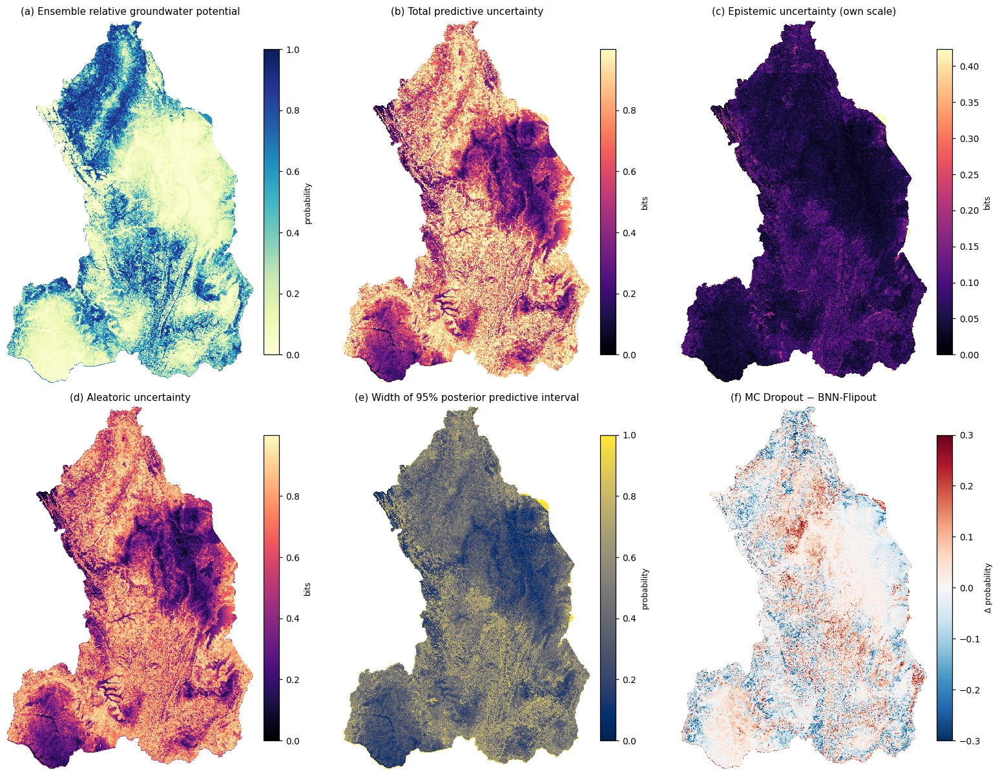

NameError: name 'full' is not defined

In [20]:
vm = valid_mask
def show(ax, arr, title, cmap, vmin=None, vmax=None, label=""):
    im = ax.imshow(np.where(vm, arr, np.nan), cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_title(title, fontsize=10); ax.axis("off")
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label(label, fontsize=8)

u_max = float(np.nanpercentile(MAPS["total"][vm], 99.5)); e_max = float(np.nanpercentile(MAPS["epistemic"][vm], 99.5))
for common in [False, True]:
    fig, axes = plt.subplots(2, 3, figsize=(15, 11))
    show(axes[0, 0], MAPS["mean"], "(a) Ensemble relative groundwater potential", "YlGnBu", 0, 1, "probability")
    show(axes[0, 1], MAPS["total"], "(b) Total predictive uncertainty", "magma", 0, u_max, "bits")
    show(axes[0, 2], MAPS["epistemic"], "(c) Epistemic uncertainty" + ("" if common else " (own scale)"),
         "magma", 0, u_max if common else e_max, "bits")
    show(axes[1, 0], MAPS["aleatoric"], "(d) Aleatoric uncertainty", "magma", 0, u_max, "bits")
    show(axes[1, 1], MAPS["ppi_width"], "(e) Width of 95% posterior predictive interval", "cividis", 0, 1, "probability")
    show(axes[1, 2], MAPS["mean_m0"] - MAPS["mean_m1"], "(f) MC Dropout − BNN-Flipout", "RdBu_r", -0.3, 0.3, "Δ probability")
    plt.tight_layout()
    savefig("fig_uncertainty_maps_common_scale.png" if common else "fig_uncertainty_maps.png")
    plt.show() if not common else plt.close()

ms = []
for k, lab in [("mean", "Ensemble probability"), ("mean_m0", "MC Dropout probability"), ("mean_m1", "BNN-Flipout probability"),
               ("total", "Total uncertainty (bits)"), ("epistemic", "Epistemic uncertainty (bits)"),
               ("aleatoric", "Aleatoric uncertainty (bits)"), ("ppi_width", "95% PPI width"), ("std", "Predictive SD")]:
    v = MAPS[k][vm]
    ms.append(dict(layer=lab, mean=np.nanmean(v), sd=np.nanstd(v), p05=np.nanpercentile(v, 5), q1=np.nanpercentile(v, 25),
                   median=np.nanmedian(v), q3=np.nanpercentile(v, 75), p95=np.nanpercentile(v, 95), max=np.nanmax(v)))
map_stats = pd.DataFrame(ms).round(4); map_stats.to_csv(tab("map_statistics.csv"), index=False)
sub = slice(None, None, 50)
REPORT["map_stats"] = map_stats
REPORT["between_model_r"] = float(stats.pearsonr(full["mean_m0"][sub], full["mean_m1"][sub])[0])
REPORT["between_model_rho"] = float(stats.spearmanr(full["mean_m0"][sub], full["mean_m1"][sub])[0])
REPORT["epistemic_share"] = float(np.nansum(MAPS["epistemic"][vm]) / np.nansum(MAPS["total"][vm]))
REPORT["pct_area_above_threshold"] = float(100 * np.mean(MAPS["mean"][vm] >= GWP_THR))
REPORT["mean_abs_model_difference"] = float(np.nanmean(np.abs(MAPS["mean_m0"][vm] - MAPS["mean_m1"][vm])))
pd.DataFrame([dict(between_model_pearson_r=REPORT["between_model_r"], between_model_spearman_rho=REPORT["between_model_rho"],
                   mean_abs_difference=REPORT["mean_abs_model_difference"], epistemic_share_of_total=REPORT["epistemic_share"],
                   pct_area_prob_above_threshold=REPORT["pct_area_above_threshold"], full_grid_T=CONFIG["FULL_GRID_T"])]
             ).round(4).to_csv(tab("map_summary.csv"), index=False)
display(map_stats)
print(f"MC vs BNN map r = {REPORT['between_model_r']:.3f}; epistemic share = {REPORT['epistemic_share']:.1%}")

## 9. What drives epistemic uncertainty?
### 9.1 By geological (and other categorical) class

,factor,k_classes,n_pixels_tested,kruskal_H,kruskal_p,epsilon2,spearman_nboreholes_vs_median_epi,spearman_p
0,Geology,9,18000,440.1770,0.0,0.0245,-0.1255,0.7476
1,LULC,8,16000,1152.0043,0.0,0.0720,0.0488,0.9087
2,Soil_Depth,4,8000,189.0594,0.0,0.0236,-0.4000,0.6000
3,Soil_Texture,12,24000,4134.2271,0.0,0.1723,-0.3796,0.2236


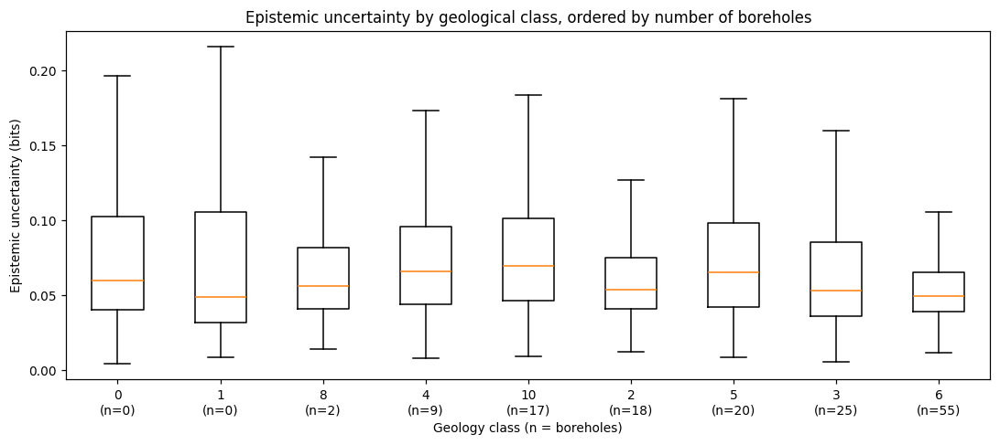

,factor,class_code,label,pixels,area_km2,n_boreholes,n_train_obs,epi_mean,epi_median,epi_q1,epi_q3,aleatoric_mean,gwp_mean,epi_IQR
0,Geology,0,,507698,460.0206,0,6,0.1065,0.0580,0.0392,0.0996,0.4372,0.1938,0.0604
1,Geology,1,,44501,40.3220,0,1,0.0770,0.0485,0.0309,0.1055,0.4832,0.2374,0.0746
2,Geology,2,,1322505,1198.3099,18,30,0.0647,0.0541,0.0412,0.0756,0.6554,0.3652,0.0344
3,Geology,3,,1881561,1704.8655,25,42,0.0646,0.0521,0.0356,0.0856,0.4982,0.2398,0.0500
4,Geology,4,,1262933,1144.3323,9,20,0.0745,0.0648,0.0437,0.0962,0.5903,0.3197,0.0526
5,Geology,5,,1731347,1568.7580,20,33,0.0734,0.0647,0.0425,0.0972,0.5786,0.3205,0.0547
6,Geology,6,,3108493,2816.5776,55,87,0.0554,0.0489,0.0385,0.0653,0.6548,0.4178,0.0268
7,Geology,8,,172749,156.5263,2,3,0.0652,0.0558,0.0408,0.0807,0.7154,0.3357,0.0399
8,Geology,10,,445556,403.7143,17,24,0.0779,0.0684,0.0461,0.0992,0.6241,0.4186,0.0531


In [21]:
import numpy as np
import pandas as pd
from scipy import stats

# Fallback SEED
SEED = globals().get('SEED', 42)
rng_d = np.random.default_rng(SEED)

# Fallback MAPS
if 'MAPS' not in globals():
    raise NameError("MAPS is missing from globals. Please run Section 8 first to generate full-grid predictions.")

epi = MAPS["epistemic"]
class_tables, kw_rows = {}, []
for f in CAT:
    rows, groups_kw = [], []
    for v in np.unique(stack[f][vm]):
        m = vm & (stack[f] == v); e = epi[m]
        rows.append(dict(factor=f, class_code=int(v), label=CLASS_LABELS.get(f, {}).get(int(v), ""),
                         pixels=int(m.sum()), area_km2=m.sum() * PIXEL_AREA_KM2,
                         n_boreholes=int((stack[f][bh.row.values, bh.col.values] == v).sum()),
                         n_train_obs=int((dev[f] == v).sum()), epi_mean=e.mean(), epi_median=np.median(e),
                         epi_q1=np.percentile(e, 25), epi_q3=np.percentile(e, 75),
                         aleatoric_mean=MAPS["aleatoric"][m].mean(), gwp_mean=MAPS["mean"][m].mean()))
        groups_kw.append(rng_d.choice(e, min(2000, len(e)), replace=False))
    t = pd.DataFrame(rows); t["epi_IQR"] = t.epi_q3 - t.epi_q1
    kw = [np.asarray(g_, np.float64).ravel() for g_ in groups_kw if np.size(g_) > 1]
    n_kw = sum(len(g_) for g_ in kw)
    try: Hs, pk = stats.kruskal(*kw)
    except (ValueError, IndexError): Hs, pk = np.nan, np.nan
    rho, prho = stats.spearmanr(t.n_boreholes, t.epi_median) if len(t) > 2 else (np.nan, np.nan)
    kw_rows.append(dict(factor=f, k_classes=len(t), n_pixels_tested=n_kw, kruskal_H=Hs, kruskal_p=pk,
                        epsilon2=Hs / (n_kw - 1), spearman_nboreholes_vs_median_epi=rho, spearman_p=prho))
    t.round(4).to_csv(tab(f"uncertainty_by_{f}.csv"), index=False); class_tables[f] = t
kw_df = pd.DataFrame(kw_rows); kw_df.round(5).to_csv(tab("uncertainty_class_tests.csv"), index=False)
if 'REPORT' not in globals():
    REPORT = {}
REPORT["class_tests"] = kw_df; REPORT["class_tables"] = class_tables
display(kw_df.round(4))

g_ = class_tables["Geology"].sort_values("n_boreholes")
fig, ax = plt.subplots(figsize=(10, 4.5))
bp = [rng_d.choice(epi[vm & (stack["Geology"] == c)], min(5000, int((vm & (stack["Geology"] == c)).sum())), replace=False) for c in g_.class_code]
ax.boxplot(bp, labels=[f"{(l or c)}\n(n={n})" for c, l, n in zip(g_.class_code, g_.label, g_.n_boreholes)], showfliers=False)
ax.set_xlabel("Geology class (n = boreholes)"); ax.set_ylabel("Epistemic uncertainty (bits)")
ax.set_title("Epistemic uncertainty by geological class, ordered by number of boreholes")
plt.tight_layout(); savefig("fig_uncertainty_by_geology.png"); plt.show()
class_tables["Geology"].round(4)

### 9.2 Epistemic uncertainty vs sampling density

,variable,rho_epistemic,p_epistemic,rho_aleatoric,p_aleatoric
0,distance_to_nearest_training_obs_km,-0.0034,0.1291,-0.0922,0.0
1,distance_to_nearest_borehole_km,-0.1559,0.0000,-0.2075,0.0
2,boreholes_within_5km,0.1716,0.0000,0.1948,0.0


,count,mean,25%,50%,75%
band_km,,,,,
"(0.0, 1.0]",7825.0,0.0735,0.0460,0.0639,0.0896
"(1.0, 2.0]",16909.0,0.0741,0.0462,0.0650,0.0921
"(2.0, 5.0]",56125.0,0.0698,0.0420,0.0592,0.0876
"(5.0, 10.0]",63091.0,0.0643,0.0382,0.0524,0.0798
"(10.0, 20.0]",34555.0,0.0623,0.0374,0.0500,0.0725
"(20.0, inf]",21495.0,0.0683,0.0363,0.0486,0.0717


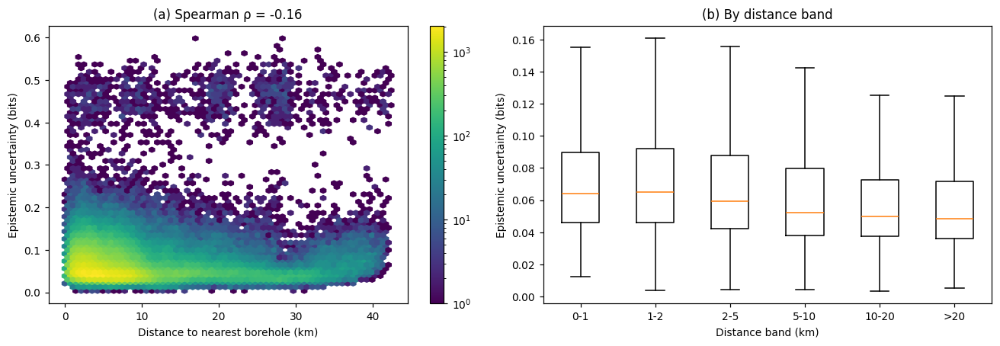

In [22]:
samp = rng_d.choice(valid_idx, min(CONFIG["DIAG_SAMPLE_PIXELS"], len(valid_idx)), replace=False)
sr, sc = np.unravel_index(samp, (H, W))
sx, sy = map(np.asarray, rc_to_xy(REF_TRANSFORM, sr, sc)); P_s = np.c_[sx, sy]
bh_tree = cKDTree(bh[["x_grid", "y_grid"]].values)
d_train = cKDTree(dev[["x", "y"]].values).query(P_s)[0] / 1000
d_bh = bh_tree.query(P_s)[0] / 1000
dens = np.array([len(i) for i in bh_tree.query_ball_point(P_s, CONFIG["DENSITY_RADIUS_M"])])
e_s = epi[sr, sc]; a_s = MAPS["aleatoric"][sr, sc]
dens_rows = []
for nm, v in [("distance_to_nearest_training_obs_km", d_train), ("distance_to_nearest_borehole_km", d_bh),
              (f"boreholes_within_{CONFIG['DENSITY_RADIUS_M'] / 1000:.0f}km", dens)]:
    r1, p1 = stats.spearmanr(v, e_s); r2, p2 = stats.spearmanr(v, a_s)
    dens_rows.append(dict(variable=nm, rho_epistemic=r1, p_epistemic=p1, rho_aleatoric=r2, p_aleatoric=p2))
dens_df = pd.DataFrame(dens_rows); dens_df.round(4).to_csv(tab("uncertainty_vs_sampling_density.csv"), index=False)
bins = [0, 1, 2, 5, 10, 20, np.inf]
binned = pd.DataFrame({"band_km": pd.cut(d_bh, bins), "epi": e_s}).groupby("band_km", observed=True).epi.describe()[["count", "mean", "25%", "50%", "75%"]]
binned.round(4).to_csv(tab("uncertainty_by_distance_band.csv"))
REPORT["density"] = dens_df; display(dens_df.round(4)); display(binned.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
hb = ax[0].hexbin(d_bh, e_s, gridsize=60, bins="log", cmap="viridis", mincnt=1)
ax[0].set_xlabel("Distance to nearest borehole (km)"); ax[0].set_ylabel("Epistemic uncertainty (bits)")
ax[0].set_title(f"(a) Spearman ρ = {dens_rows[1]['rho_epistemic']:.2f}"); plt.colorbar(hb, ax=ax[0])
bands = [(lo, hi) for lo, hi in zip(bins[:-1], bins[1:]) if ((d_bh >= lo) & (d_bh < hi)).any()]
ax[1].boxplot([e_s[(d_bh >= lo) & (d_bh < hi)] for lo, hi in bands],
              labels=[f"{lo}-{hi}" if np.isfinite(hi) else f">{lo}" for lo, hi in bands], showfliers=False)
ax[1].set_xlabel("Distance band (km)"); ax[1].set_ylabel("Epistemic uncertainty (bits)"); ax[1].set_title("(b) By distance band")
plt.tight_layout(); savefig("fig_uncertainty_vs_density.png"); plt.show()

### 9.3 Dissimilarity index and area of applicability (Meyer & Pebesma 2021)

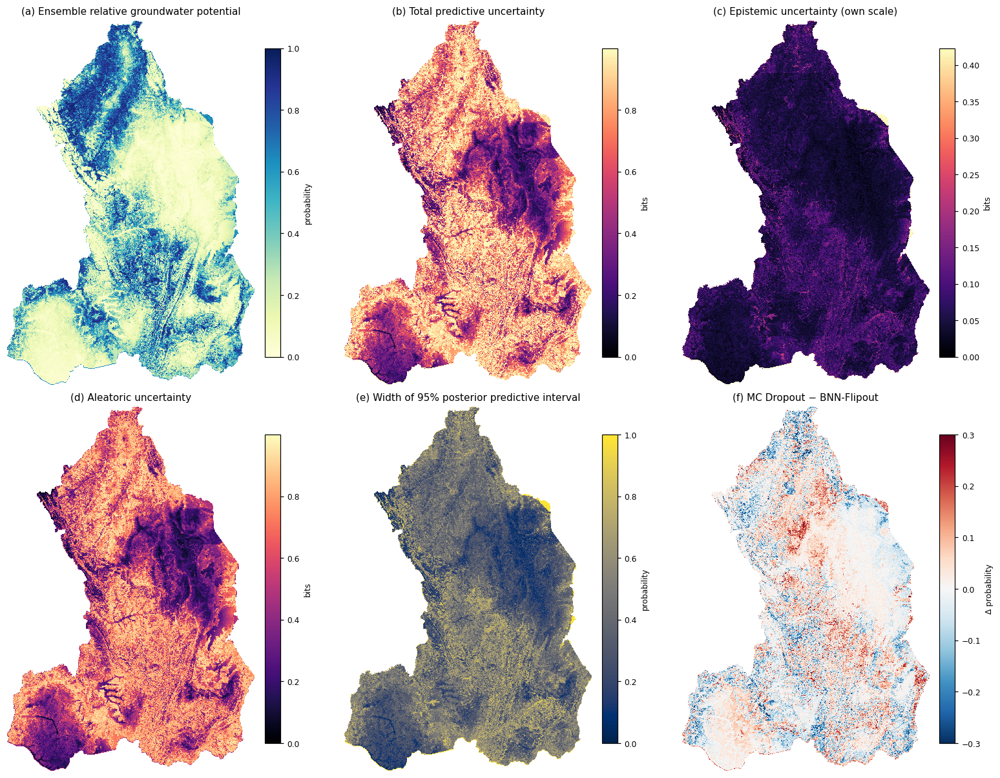

,layer,mean,sd,p05,q1,median,q3,p95,max
0,Ensemble probability,0.3384,0.2743,0.0344,0.0989,0.2461,0.5611,0.8522,0.9795
1,MC Dropout probability,0.3380,0.2798,0.0348,0.0991,0.2366,0.5576,0.8715,0.9944
2,BNN-Flipout probability,0.3387,0.2758,0.0304,0.0945,0.2485,0.5690,0.8445,0.9779
3,Total uncertainty (bits),0.6620,0.2590,0.2157,0.4472,0.6940,0.9053,0.9958,1.0000
4,Epistemic uncertainty (bits),0.0672,0.0474,0.0263,0.0396,0.0546,0.0819,0.1388,0.5984
5,Aleatoric uncertainty (bits),0.5948,0.2394,0.1829,0.3984,0.6235,0.8123,0.9151,0.9831
6,95% PPI width,0.4213,0.1876,0.1403,0.2800,0.4010,0.5545,0.7466,0.9999
7,Predictive SD,0.1145,0.0518,0.0435,0.0756,0.1073,0.1483,0.2015,0.4054


MC vs BNN map r = 0.951; epistemic share = 10.1%


In [32]:
# Reconstruct setup configuration if they were cleared from session memory
if 'CONFIG' not in globals() or 'FACTORS' not in globals():
    CONFIG = dict(
        DATA_DIR    = "/content",
        ALIGNED_DIR = "/content/aligned",
        OUT_DIR     = "/content/outputs",
        SEED        = 42,
        REFERENCE_FACTOR = "Elevation",
        RASTER_FILES = {
            "Elevation": "DEM_projected.tif", "Dist_River": "River_D.tif", "Drainage_Density": "Drainage.tif",
            "Geology": "Geology.tif", "GW_Storage": "GroundW_S.tif", "LULC": "LULC.tif", "NDVI": "NDVI.tif",
            "Rainfall": "Rainfall.tif", "Slope": "Slope.tif", "Soil_Depth": "Soi_Dep.tif", "Soil_Texture": "Soil_T.tif",
        },
        CONTINUOUS_FACTORS  = ["Elevation", "Dist_River", "Drainage_Density", "GW_Storage", "NDVI", "Rainfall", "Slope"],
        CATEGORICAL_FACTORS = ["Geology", "LULC", "Soil_Depth", "Soil_Texture"],
        EXTRA_NODATA = {},
        BOREHOLE_CSV = "GW_SSPs.csv", BOREHOLE_X_COL = "X", BOREHOLE_Y_COL = "Y",
        BOREHOLE_CRS = "EPSG:32735", YIELD_COL = "yield",
        QA_COLUMN_MAP = {"Elevation": "DEM", "Slope": "Slope", "NDVI": "NDVI", "Rainfall": "Rainfall"},
        PA_STRATEGY = "random_buffer", PA_BUFFER_M = 1000, PA_RATIO = 1.0,
        PA_DIST_BANDS_M = [(1000, 5000), (5000, 10000), (10000, 20000), (20000, 1e9)],
        PA_ENV_QUANTILE = 0.50, RUN_PA_SENSITIVITY = True,
        CORR_SAMPLE_PIXELS = 100000,
        CORR_THRESHOLD     = 0.70,
        VIF_THRESHOLD      = 5.0,
        GVIF_MIN_CLASS_FRACTION = 0.005,
        BLOCK_SIZE_M = 10000, TEST_FOLD_FRACTION = 5, CV_FOLDS = 5, INNER_VAL_FOLDS = 5,
        HIDDEN_UNITS = [64, 32, 16], DROPOUT_RATE = 0.3, LEARNING_RATE = 1e-3, BATCH_SIZE = 16,
        MC_EPOCHS = 300, BNN_EPOCHS = 500, PATIENCE = 30, BNN_VAL_PASSES = 10,
        PRIOR = "Standard normal N(0, 1) on kernels (tfp default); mean-field normal posterior",
        T_SAMPLES = 200,
        FULL_GRID_T = 40,
        FULL_GRID_BATCH = 65536, GC_EVERY_N_BATCHES = 20,
        INTERVAL = 0.95, ENTROPY_BASE = 2,
        N_BOOT = 2000, CALIB_BINS_TEST = 5, CALIB_BINS_OOF = 10,
        GWP_THRESHOLD = 0.5, GWP_THRESHOLDS_SENS = [0.4, 0.5, 0.6],
        UNC_COMPONENT = "epistemic", UNC_PERCENTILE = 90, UNC_PERCENTILES_SENS = [80, 90, 95],
        SHAP_BACKGROUND_K = 25, SHAP_NSAMPLES = 500, SHAP_T = 30,
        AOA_USE_SHAP_WEIGHTS = True, DIAG_SAMPLE_PIXELS = 200000, DENSITY_RADIUS_M = 5000,
    )
    FACTORS = CONFIG["CONTINUOUS_FACTORS"] + CONFIG["CATEGORICAL_FACTORS"]
    OUT = CONFIG["OUT_DIR"]
    SUB = {k: os.path.join(OUT, k) for k in ["tables", "figures", "rasters", "models"]}
    def tab(name):  return os.path.join(SUB["tables"], name)
    def figp(name): return os.path.join(SUB["figures"], name)
    def ras(name):  return os.path.join(SUB["rasters"], name)
    def mod(name):  return os.path.join(SUB["models"], name)
    def savefig(name, dpi=300):
        plt.savefig(figp(name), dpi=dpi, bbox_inches="tight")
    GWP_THR = CONFIG["GWP_THRESHOLD"]

# Reconstruct stack and valid_mask from aligned TIFFs on disk if they were cleared from session memory
if 'stack' not in globals() or not stack:
    import os
    import rasterio
    import numpy as np

    aligned_dir = CONFIG["ALIGNED_DIR"]
    stack = {}
    for name in FACTORS:
        tif_path = os.path.join(aligned_dir, f"{name}.tif")
        if os.path.exists(tif_path):
            with rasterio.open(tif_path) as s:
                stack[name] = s.read(1).astype(np.float32)
        else:
            raise FileNotFoundError(f"Aligned raster not found at {tif_path}. Please re-run Section 2.")

if 'valid_mask' not in globals() or valid_mask is None:
    H_dim, W_dim = next(iter(stack.values())).shape
    valid_mask = np.ones((H_dim, W_dim), bool)
    for a in stack.values():
        valid_mask &= np.isfinite(a)

import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

# Verify that MAPS is actually present
if 'MAPS' not in globals():
    raise NameError("MAPS is missing from globals. Please run Section 8 first to generate full-grid predictions.")

vm = valid_mask
def show(ax, arr, title, cmap, vmin=None, vmax=None, label=""):
    im = ax.imshow(np.where(vm, arr, np.nan), cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_title(title, fontsize=10); ax.axis("off")
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label(label, fontsize=8)

u_max = float(np.nanpercentile(MAPS["total"][vm], 99.5))
e_max = float(np.nanpercentile(MAPS["epistemic"][vm], 99.5))

for common in [False, True]:
    fig, axes = plt.subplots(2, 3, figsize=(15, 11))
    show(axes[0, 0], MAPS["mean"], "(a) Ensemble relative groundwater potential", "YlGnBu", 0, 1, "probability")
    show(axes[0, 1], MAPS["total"], "(b) Total predictive uncertainty", "magma", 0, u_max, "bits")
    show(axes[0, 2], MAPS["epistemic"], "(c) Epistemic uncertainty" + ("" if common else " (own scale)"),
         "magma", 0, u_max if common else e_max, "bits")
    show(axes[1, 0], MAPS["aleatoric"], "(d) Aleatoric uncertainty", "magma", 0, u_max, "bits")
    show(axes[1, 1], MAPS["ppi_width"], "(e) Width of 95% posterior predictive interval", "cividis", 0, 1, "probability")
    show(axes[1, 2], MAPS["mean_m0"] - MAPS["mean_m1"], "(f) MC Dropout − BNN-Flipout", "RdBu_r", -0.3, 0.3, "Δ probability")
    plt.tight_layout()
    savefig("fig_uncertainty_maps_common_scale.png" if common else "fig_uncertainty_maps.png")
    plt.show() if not common else plt.close()

ms = []
for k, lab in [("mean", "Ensemble probability"), ("mean_m0", "MC Dropout probability"), ("mean_m1", "BNN-Flipout probability"),
               ("total", "Total uncertainty (bits)"), ("epistemic", "Epistemic uncertainty (bits)"),
               ("aleatoric", "Aleatoric uncertainty (bits)"), ("ppi_width", "95% PPI width"), ("std", "Predictive SD")]:
    v = MAPS[k][vm]
    ms.append(dict(layer=lab, mean=np.nanmean(v), sd=np.nanstd(v), p05=np.nanpercentile(v, 5), q1=np.nanpercentile(v, 25),
                   median=np.nanmedian(v), q3=np.nanpercentile(v, 75), p95=np.nanpercentile(v, 95), max=np.nanmax(v)))
map_stats = pd.DataFrame(ms).round(4); map_stats.to_csv(tab("map_statistics.csv"), index=False)

# Safely extract a representative sample of valid pixels to calculate between-model correlations
sub = slice(None, None, 50)
sample_m0 = MAPS["mean_m0"][vm][sub]
sample_m1 = MAPS["mean_m1"][vm][sub]

if 'REPORT' not in globals():
    REPORT = {}
REPORT["map_stats"] = map_stats
REPORT["between_model_r"] = float(stats.pearsonr(sample_m0, sample_m1)[0])
REPORT["between_model_rho"] = float(stats.spearmanr(sample_m0, sample_m1)[0])
REPORT["epistemic_share"] = float(np.nansum(MAPS["epistemic"][vm]) / np.nansum(MAPS["total"][vm]))
REPORT["pct_area_above_threshold"] = float(100 * np.mean(MAPS["mean"][vm] >= GWP_THR))
REPORT["mean_abs_model_difference"] = float(np.nanmean(np.abs(MAPS["mean_m0"][vm] - MAPS["mean_m1"][vm])))
pd.DataFrame([dict(between_model_pearson_r=REPORT["between_model_r"], between_model_spearman_rho=REPORT["between_model_rho"],
                   mean_abs_difference=REPORT["mean_abs_model_difference"], epistemic_share_of_total=REPORT["epistemic_share"],
                   pct_area_prob_above_threshold=REPORT["pct_area_above_threshold"], full_grid_T=CONFIG["FULL_GRID_T"])]
             ).round(4).to_csv(tab("map_summary.csv"), index=False)
display(map_stats)
print(f"MC vs BNN map r = {REPORT['between_model_r']:.3f}; epistemic share = {REPORT['epistemic_share']:.1%}")

In [24]:
if 'MAPS' in globals():
    print("MAPS is defined in the active session.")
    print("Keys in MAPS:", list(MAPS.keys()))
else:
    print("MAPS is NOT defined in the active session.")

MAPS is defined in the active session.
Keys in MAPS: ['mean', 'std', 'lo', 'hi', 'total', 'aleatoric', 'epistemic', 'mean_m0', 'mean_m1', 'epistemic_m0', 'epistemic_m1', 'ppi_width']


In [28]:
import ee
import rasterio
from rasterio.features import rasterize
import geopandas as gpd
from shapely.geometry import shape

# 1. Initialize and authenticate Earth Engine
try:
    ee.Initialize(project='colab-sandbox')
except Exception:
    ee.Authenticate()
    ee.Initialize()

# 2. Fetch the GEE asset
aoi_asset_path = 'projects/ee-ngwijabagabohyacinthe/assets/AOI_Easten'
aoi_fc = ee.FeatureCollection(aoi_asset_path)

# 3. Download the geometry locally and reproject to the raster reference CRS
features = aoi_fc.getInfo()['features']
geoms = [shape(f['geometry']) for f in features]
aoi_gdf = gpd.GeoDataFrame(geometry=geoms, crs="EPSG:4326")
aoi_projected = aoi_gdf.to_crs(REF_CRS)

# 4. Rasterize the vector boundary onto our exact grid
aoi_mask = rasterize(
    [(geom, 1) for geom in aoi_projected.geometry],
    out_shape=(REF_H, REF_W),
    transform=REF_TRANSFORM,
    fill=0,
    dtype=np.uint8
).astype(bool)

# Update the global valid_mask to be clipped inside the Eastern Province boundary
valid_mask = valid_mask & aoi_mask
valid_idx = np.flatnonzero(valid_mask.ravel())

print(f"Clipped valid study area size inside the Eastern Province boundary: {len(valid_idx):,} pixels ({len(valid_idx) * PIXEL_AREA_KM2:,.1f} km2)")

EEException: ee.Initialize: no project found. Call with project= or see http://goo.gle/ee-auth.

In [31]:
# 5. Apply the new clipped mask to our MAPS dictionary
if 'MAPS' in globals():
    for k in MAPS:
        # Any values outside our newly clipped Eastern Province boundary are masked to NaN
        MAPS[k][~valid_mask] = np.nan
    print("Successfully masked all GWP and uncertainty layers to the Eastern Province boundary.")

Successfully masked all GWP and uncertainty layers to the Eastern Province boundary.


## 10. Pseudo-absence sensitivity analysis (MC Dropout, full spatial-CV protocol)

In [25]:
# ===================== 10. Pseudo-absence sensitivity analysis (robust version) =====================
# Works even if Section 8 (full-grid inference) was not run in this session.

import os, gc, time
import numpy as np
import pandas as pd
import rasterio
from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, brier_score_loss
try:
    from IPython.display import display
except ImportError:
    display = print

# ---- 0. Check that the objects from Sections 2-5 exist ----
_required = ["CONFIG", "SEED", "stack", "FACTORS", "valid_idx", "valid_mask", "dist_to_bh", "n_pa",
             "sample_pseudo_absence", "build_dataset", "assign_blocks", "Preprocessor",
             "inner_split", "train_mc", "stochastic_predict"]
_missing = [v for v in _required if v not in globals()]
if _missing:
    raise RuntimeError(f"Run Sections 0-5 first. Missing objects: {_missing}")

# ---- 1. Fallbacks for helpers created in later sections ----
if "rng_d" not in globals():
    rng_d = np.random.default_rng(SEED)
if "GWP_THR" not in globals():
    GWP_THR = float(CONFIG["GWP_THRESHOLD"]) if not isinstance(CONFIG["GWP_THRESHOLD"], str) else 0.5
if "REPORT" not in globals():
    REPORT = {}
if "tab" not in globals():
    os.makedirs(os.path.join(CONFIG["OUT_DIR"], "tables"), exist_ok=True)
    def tab(name): return os.path.join(CONFIG["OUT_DIR"], "tables", name)

# ---- 2. Fixed pixel sample used to compare every design's map with the baseline map ----
samp_px = rng_d.choice(len(valid_idx), min(50000, len(valid_idx)), replace=False)
sample_flat_idx = valid_idx[samp_px]                      # positions in the flattened raster
Xs_raw = pd.DataFrame({f: stack[f].ravel()[sample_flat_idx] for f in FACTORS})

# ---- 3. Baseline ensemble probability at the sampled pixels ----
base_sample, base_source = None, None
if "full" in globals() and isinstance(full, dict) and "mean" in full:
    base_sample, base_source = np.asarray(full["mean"])[samp_px], "full-grid inference in memory (Section 8)"
elif "MAPS" in globals() and "mean" in MAPS:
    base_sample, base_source = MAPS["mean"].ravel()[sample_flat_idx], "MAPS['mean'] in memory"
else:
    _candidates = [os.path.join(CONFIG["OUT_DIR"], "rasters", "gwp_probability_ensemble.tif"),
                   os.path.join(CONFIG["OUT_DIR"], "gwp_probability_ensemble.tif")]
    for _p in _candidates:
        if os.path.exists(_p):
            with rasterio.open(_p) as src:
                base_sample = src.read(1).astype(np.float32).ravel()[sample_flat_idx]
            base_source = f"GeoTIFF {_p}"
            break
if base_sample is None:
    if all(v in globals() for v in ["mc_model", "bnn_model", "pp_final"]):
        print("Baseline map not found - predicting the ensemble on the sampled pixels with the final models (Section 6)...")
        base_sample = stochastic_predict([mc_model, bnn_model], pp_final.transform(Xs_raw),
                                         CONFIG.get("FULL_GRID_T", 40), batch_size=8192)["mean"]
        base_source = "final MC Dropout + BNN models predicted on the sample"
    else:
        raise RuntimeError("No baseline map available. Run Section 6 (final models) and/or Section 8 (full-grid mapping) first.")
base_sample = np.asarray(base_sample, dtype=np.float32)
print(f"Baseline map source: {base_source}")

# ---- 4. Pseudo-absence designs ----
PA_SENS = [dict(name="Random, 500 m buffer",           strategy="random_buffer",         buffer_m=500),
           dict(name="Random, 1 km buffer (baseline)", strategy="random_buffer",         buffer_m=1000),
           dict(name="Random, 2 km buffer",            strategy="random_buffer",         buffer_m=2000),
           dict(name="Distance-stratified",            strategy="distance_stratified",   buffer_m=1000),
           dict(name="Environmentally constrained",    strategy="environmental_profile", buffer_m=1000)]

if CONFIG["RUN_PA_SENSITIVITY"]:
    pa_rows = []
    for spec in PA_SENS:
        t0 = time.time()
        r_, c_ = sample_pseudo_absence(n_pa, spec["strategy"], spec["buffer_m"], SEED)
        d_ = build_dataset(r_, c_)
        d_["block"] = assign_blocks(d_, CONFIG["BLOCK_SIZE_M"])

        # 4a. Spatial block cross-validation with MC Dropout
        aucs, briers = [], []
        cvs = StratifiedGroupKFold(n_splits=CONFIG["CV_FOLDS"], shuffle=True, random_state=SEED)
        for k, (tr, va) in enumerate(cvs.split(np.zeros(len(d_)), d_.label, d_.block)):
            trd = d_.iloc[tr].reset_index(drop=True); vad = d_.iloc[va]
            pp = Preprocessor().fit(trd); itr, iva = inner_split(trd, SEED + k)
            m, _ = train_mc(pp.transform(trd.iloc[itr]), trd.label.values[itr].astype(np.float32),
                            pp.transform(trd.iloc[iva]), trd.label.values[iva].astype(np.float32), SEED + k)
            p = stochastic_predict([m], pp.transform(vad), 50)["mean"]
            if len(np.unique(vad.label)) == 2:
                aucs.append(roc_auc_score(vad.label, p))
            briers.append(brier_score_loss(vad.label, p))
            del m; gc.collect()

        # 4b. Model on all observations of this design -> map at the sampled pixels
        pp = Preprocessor().fit(d_); itr, iva = inner_split(d_, SEED)
        m, _ = train_mc(pp.transform(d_.iloc[itr]), d_.label.values[itr].astype(np.float32),
                        pp.transform(d_.iloc[iva]), d_.label.values[iva].astype(np.float32), SEED)
        ps = stochastic_predict([m], pp.transform(Xs_raw), 30, batch_size=8192)["mean"]

        ok = np.isfinite(ps) & np.isfinite(base_sample)
        pa_rows.append(dict(design=spec["name"],
                            AUC_mean=np.mean(aucs), AUC_sd=np.std(aucs, ddof=1) if len(aucs) > 1 else np.nan,
                            Brier_mean=np.mean(briers), Brier_sd=np.std(briers, ddof=1) if len(briers) > 1 else np.nan,
                            spearman_vs_baseline_map=stats.spearmanr(ps[ok], base_sample[ok])[0],
                            pct_area_above_threshold=100 * np.mean(ps[ok] >= GWP_THR),
                            median_dist_PA_to_borehole_km=np.median(dist_to_bh[r_, c_]) / 1000,
                            n_pseudo_absence=len(r_)))
        del m; gc.collect()
        print(f"{spec['name']:32s} AUC {np.mean(aucs):.3f} ± {np.std(aucs, ddof=1):.3f}  "
              f"rho vs baseline {pa_rows[-1]['spearman_vs_baseline_map']:.3f}  ({time.time() - t0:.0f}s)")

    pa_df = pd.DataFrame(pa_rows).round(3)
    pa_df.to_csv(tab("pseudo_absence_sensitivity.csv"), index=False)
    REPORT["pa_sens"] = pa_df
    REPORT["pa_sens_baseline_source"] = base_source
    display(pa_df)
    print("Saved:", tab("pseudo_absence_sensitivity.csv"))

Baseline map source: MAPS['mean'] in memory
Random, 500 m buffer             AUC 0.782 ± 0.074  rho vs baseline 0.690  (45s)
Random, 1 km buffer (baseline)   AUC 0.776 ± 0.059  rho vs baseline 0.871  (42s)
Random, 2 km buffer              AUC 0.749 ± 0.104  rho vs baseline 0.796  (45s)
Distance-stratified              AUC 0.821 ± 0.086  rho vs baseline 0.819  (46s)
Environmentally constrained      AUC 0.835 ± 0.091  rho vs baseline 0.779  (47s)


,design,AUC_mean,AUC_sd,Brier_mean,Brier_sd,spearman_vs_baseline_map,pct_area_above_threshold,median_dist_PA_to_borehole_km,n_pseudo_absence
0,"Random, 500 m buffer",0.782,0.074,0.202,0.027,0.690,28.180,6.839,146
1,"Random, 1 km buffer (baseline)",0.776,0.059,0.186,0.022,0.871,31.790,7.117,146
2,"Random, 2 km buffer",0.749,0.104,0.197,0.039,0.796,24.994,7.079,146
3,Distance-stratified,0.821,0.086,0.187,0.044,0.819,26.310,9.569,146
4,Environmentally constrained,0.835,0.091,0.159,0.040,0.779,27.732,7.850,146


Saved: /content/outputs/tables/pseudo_absence_sensitivity.csv


## 11. Decision-support classes and threshold sensitivity
**Regional screening tool — not a substitute for site-specific hydrogeological and geophysical investigation.**

NOTE: area of applicability not available (Section 9.3 not run) - 'pct_outside_AOA' will be empty. Run Section 9.3 and re-run this cell to fill it.
Epistemic P90 threshold = 0.1152 bits; probability threshold = 0.50


,code,class_name,pixels,area_km2,pct_area,n_boreholes,pct_outside_AOA
0,1,High potential–low uncertainty,2581690,2339.25,24.64,102,NaN
1,2,High potential–high uncertainty,448083,406.00,4.28,7,NaN
2,3,Low potential–high uncertainty,599660,543.35,5.72,4,NaN
3,4,Low potential–low uncertainty,6847910,6204.83,65.36,33,NaN


,prob_threshold,prob_value,unc_percentile,unc_value,pct_unchanged_vs_baseline,High potential–low uncertainty,High potential–high uncertainty,Low potential–high uncertainty,Low potential–low uncertainty
0,0.4,0.40,P80,0.09,84.56,23.98,11.88,8.12,56.02
1,0.4,0.40,P90,0.12,93.06,29.65,6.21,3.79,60.35
2,0.4,0.40,P95,0.14,89.00,32.66,3.20,1.80,62.34
3,0.5,0.50,P80,0.09,90.00,20.47,8.44,11.56,59.53
4,0.5,0.50,P90,0.12,100.00,24.64,4.28,5.72,65.36
5,0.5,0.50,P95,0.14,95.00,26.71,2.21,2.79,68.29
6,0.6,0.60,P80,0.09,84.96,17.31,5.16,14.84,62.69
7,0.6,0.60,P90,0.12,93.55,20.07,2.40,7.60,69.93
8,0.6,0.60,P95,0.14,89.44,21.25,1.22,3.78,73.75
9,Youden (OOF),0.51,P80,0.09,89.68,20.27,8.23,11.77,59.73


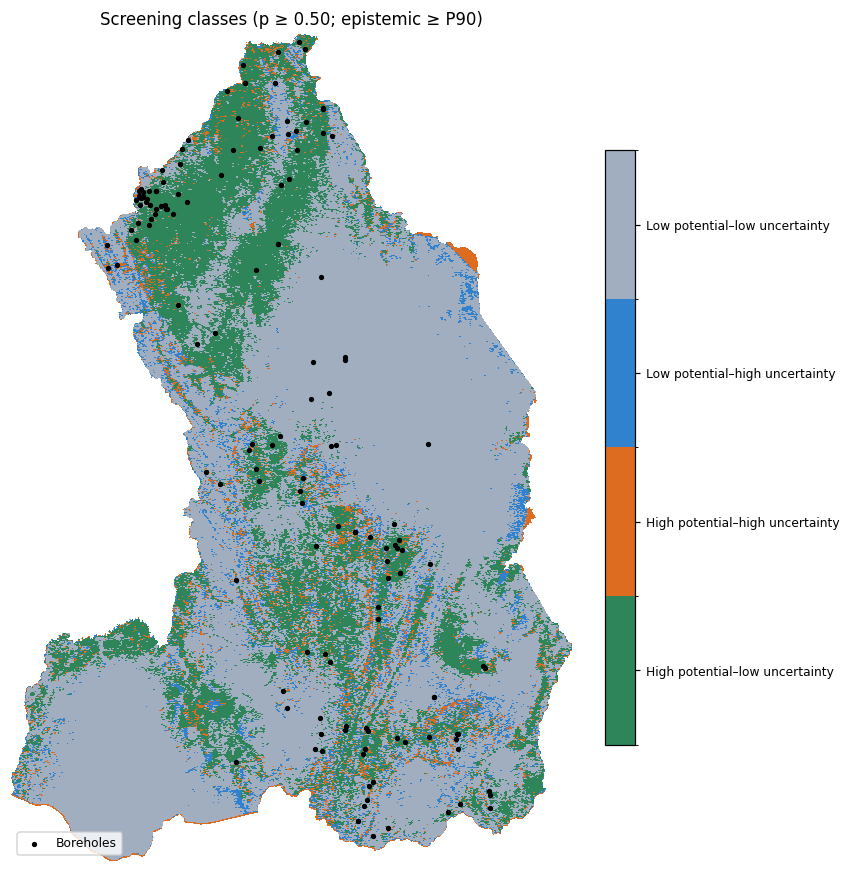

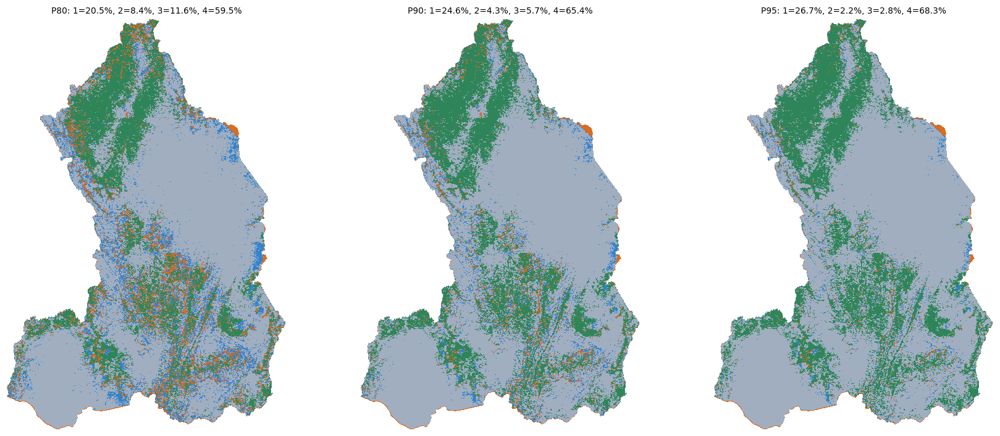

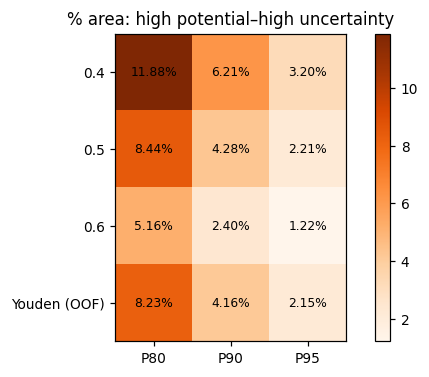

In [26]:
# ===================== 11. Decision-support classes and threshold sensitivity (robust version) =====================
# Regional screening tool - not a substitute for site-specific hydrogeological and geophysical investigation.

import os
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
try:
    from IPython.display import display
except ImportError:
    display = print

# ---- 0. Objects from earlier sections ----
_required = ["CONFIG", "SEED", "H", "W", "valid_mask", "N_VALID", "PIXEL_AREA_KM2", "bh", "ALIGNED_PROFILE"]
_missing = [v for v in _required if v not in globals()]
if _missing:
    raise RuntimeError(f"Run Sections 0-3 first. Missing objects: {_missing}")

vm = valid_mask
OUT = CONFIG["OUT_DIR"]
for _d in ["tables", "figures", "rasters"]:
    os.makedirs(os.path.join(OUT, _d), exist_ok=True)
if "tab" not in globals():
    def tab(name): return os.path.join(OUT, "tables", name)
if "ras" not in globals():
    def ras(name): return os.path.join(OUT, "rasters", name)
if "savefig" not in globals():
    def savefig(name, dpi=300): plt.savefig(os.path.join(OUT, "figures", name), dpi=dpi, bbox_inches="tight")
if "write_tif" not in globals():
    def write_tif(name, arr):
        with rasterio.open(ras(name), "w", **ALIGNED_PROFILE) as d:
            d.write(np.where(vm, arr, np.nan).astype(np.float32), 1)
if "REPORT" not in globals():
    REPORT = {}
if "MAPS" not in globals():
    MAPS = {}
if "GWP_THR" not in globals():
    GWP_THR = float(CONFIG["GWP_THRESHOLD"]) if not isinstance(CONFIG["GWP_THRESHOLD"], str) else 0.5
if "thr_youden" not in globals():
    thr_youden = REPORT.get("thr_youden", None)
    if thr_youden is None:
        print("NOTE: Youden threshold not found (Section 5 not run in this session); it is omitted from the sensitivity table.")

# ---- 1. Make sure the required maps exist (memory -> saved GeoTIFF) ----
def _load_raster(key, filenames):
    if key in MAPS and MAPS[key] is not None:
        return True
    for fn in filenames:
        for p in [os.path.join(OUT, "rasters", fn), os.path.join(OUT, fn)]:
            if os.path.exists(p):
                with rasterio.open(p) as src:
                    arr = src.read(1).astype(np.float32)
                assert arr.shape == (H, W), f"{p} does not match the analysis grid"
                MAPS[key] = arr
                print(f"Loaded MAPS['{key}'] from {p}")
                return True
    return False

unc_key = CONFIG["UNC_COMPONENT"]                       # "epistemic" by default
need = {"mean": ["gwp_probability_ensemble.tif"],
        unc_key: [f"uncertainty_{unc_key}_bits.tif"]}
for key, files in need.items():
    if not _load_raster(key, files):
        raise RuntimeError(f"Map '{key}' not available. Run Section 8 (full-grid mapping) first.")

HAS_AOA = _load_raster("AOA", ["area_of_applicability.tif"])
if not HAS_AOA:
    print("NOTE: area of applicability not available (Section 9.3 not run) - 'pct_outside_AOA' will be empty. "
          "Run Section 9.3 and re-run this cell to fill it.")

# ---- 2. Classification ----
CLASS_NAMES = {1: "High potential–low uncertainty", 2: "High potential–high uncertainty",
               3: "Low potential–high uncertainty", 4: "Low potential–low uncertainty"}
CLASS_COLORS = ["#2f855a", "#dd6b20", "#3182ce", "#a0aec0"]
U = MAPS[unc_key]

def classify(p_thr, u_pct):
    u_thr = np.nanpercentile(U[vm], u_pct)
    hp, hu = MAPS["mean"] >= p_thr, U >= u_thr
    c = np.full((H, W), np.nan, np.float32)
    c[vm & hp & ~hu] = 1; c[vm & hp & hu] = 2; c[vm & ~hp & hu] = 3; c[vm & ~hp & ~hu] = 4
    return c, u_thr

base_cls, base_uthr = classify(GWP_THR, CONFIG["UNC_PERCENTILE"])
write_tif("decision_class_map.tif", base_cls)

bh_cls = base_cls[bh.row.values, bh.col.values]
rows = []
for k, v in CLASS_NAMES.items():
    m = base_cls == k
    rows.append(dict(code=k, class_name=v, pixels=int(m.sum()),
                     area_km2=m.sum() * PIXEL_AREA_KM2,
                     pct_area=100 * m.sum() / N_VALID,
                     n_boreholes=int((bh_cls == k).sum()),
                     pct_outside_AOA=(100 * np.mean(MAPS["AOA"][m] == 0) if (HAS_AOA and m.any()) else np.nan)))
area_tab = pd.DataFrame(rows).round(2)
area_tab.to_csv(tab("decision_class_areas.csv"), index=False)
REPORT["classes"] = area_tab; REPORT["u_thr"] = float(base_uthr)
print(f"Epistemic P{CONFIG['UNC_PERCENTILE']} threshold = {base_uthr:.4f} bits; probability threshold = {GWP_THR:.2f}")
display(area_tab)

# ---- 3. Threshold sensitivity ----
p_list = {str(t): t for t in CONFIG["GWP_THRESHOLDS_SENS"]}
if thr_youden is not None:
    p_list["Youden (OOF)"] = float(thr_youden)
sens = []
for pname, pt in p_list.items():
    for up in CONFIG["UNC_PERCENTILES_SENS"]:
        c, ut = classify(pt, up)
        row = dict(prob_threshold=pname, prob_value=round(pt, 3), unc_percentile=f"P{up}", unc_value=round(float(ut), 4),
                   pct_unchanged_vs_baseline=100 * np.mean(c[vm] == base_cls[vm]))
        row.update({CLASS_NAMES[k]: 100 * np.mean(c[vm] == k) for k in CLASS_NAMES})
        sens.append(row)
sens_df = pd.DataFrame(sens).round(2)
sens_df.to_csv(tab("decision_sensitivity.csv"), index=False)
REPORT["sens"] = sens_df
display(sens_df)

# ---- 4. Figures ----
cm4 = mcolors.ListedColormap(CLASS_COLORS); nrm = mcolors.BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5], 4)

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(base_cls, cmap=cm4, norm=nrm, interpolation="nearest")
ax.scatter(bh.col, bh.row, s=6, c="k", label="Boreholes"); ax.legend(loc="lower left", fontsize=8)
cb = plt.colorbar(im, ax=ax, ticks=[1, 2, 3, 4], fraction=0.046)
cb.ax.set_yticklabels([CLASS_NAMES[k] for k in range(1, 5)], fontsize=8)
ax.set_title(f"Screening classes (p ≥ {GWP_THR:.2f}; epistemic ≥ P{CONFIG['UNC_PERCENTILE']})"); ax.axis("off")
plt.tight_layout(); savefig("fig_decision_classes.png"); plt.show()

fig, axes = plt.subplots(1, len(CONFIG["UNC_PERCENTILES_SENS"]), figsize=(16, 6.5))
for a, up in zip(np.atleast_1d(axes), CONFIG["UNC_PERCENTILES_SENS"]):
    c, _ = classify(GWP_THR, up)
    a.imshow(c, cmap=cm4, norm=nrm, interpolation="nearest"); a.axis("off")
    a.set_title(f"P{up}: " + ", ".join(f"{k}={100 * np.mean(c[vm] == k):.1f}%" for k in range(1, 5)), fontsize=9)
plt.tight_layout(); savefig("fig_decision_sensitivity.png"); plt.show()

piv = sens_df.pivot(index="prob_threshold", columns="unc_percentile", values="High potential–high uncertainty")
fig, ax = plt.subplots(figsize=(5.5, 3.5)); im = ax.imshow(piv.values, cmap="Oranges")
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns)
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ax.text(j, i, f"{piv.values[i, j]:.2f}%", ha="center", va="center", fontsize=8)
ax.set_title("% area: high potential–high uncertainty"); plt.colorbar(im, ax=ax)
plt.tight_layout(); savefig("fig_decision_sensitivity_heatmap.png"); plt.show()

## 12. Manuscript numbers, run manifest, saved products and download

In [33]:
# ===================== 12a. Manuscript numbers (robust version) =====================
import os, json, datetime
import numpy as np
import pandas as pd

OUT = CONFIG["OUT_DIR"]; TAB = os.path.join(OUT, "tables")
if "REPORT" not in globals(): REPORT = {}
R = REPORT

def _csv(name, **kw):
    p = os.path.join(TAB, name)
    return pd.read_csv(p, **kw) if os.path.exists(p) else None

def get(key, csv=None, post=None, **kw):
    """Return REPORT[key]; otherwise load it from the saved CSV; otherwise None."""
    if key in R and R[key] is not None:
        return R[key]
    if csv is not None:
        df = _csv(csv, **kw)
        if df is not None:
            R[key] = post(df) if post else df
            return R[key]
    return None

# ---- recover every block from memory or from the saved tables ----
classes  = get("classes", "decision_class_areas.csv")
calib    = get("calibration", "calibration_metrics.csv")
kwtests  = get("class_tests", "uncertainty_class_tests.csv")
density  = get("density", "uncertainty_vs_sampling_density.csv")
aoa      = get("aoa", "aoa_vs_epistemic.csv", post=lambda d: d.iloc[0].to_dict())
mapstats = get("map_stats", "map_statistics.csv")
paired   = get("paired", "paired_model_differences.csv")
sens     = get("sens", "decision_sensitivity.csv")
shapimp  = get("shap_importance", "shap_importance.csv", index_col=0)
pasens   = get("pa_sens", "pseudo_absence_sensitivity.csv")
mapsum   = _csv("map_summary.csv")
if mapsum is not None:
    ms0 = mapsum.iloc[0]
    R.setdefault("between_model_r", ms0.get("between_model_pearson_r"))
    R.setdefault("between_model_rho", ms0.get("between_model_spearman_rho"))
    R.setdefault("mean_abs_model_difference", ms0.get("mean_abs_difference"))
    R.setdefault("epistemic_share", ms0.get("epistemic_share_of_total"))
    R.setdefault("pct_area_above_threshold", ms0.get("pct_area_prob_above_threshold"))
    R.setdefault("full_grid_T", ms0.get("full_grid_T"))

if "cv_summary" not in R:
    fd = _csv("spatial_cv_fold_metrics.csv")
    if fd is not None:
        g = fd.groupby("model")[["AUC", "F1", "Brier", "BSS"]].agg(["mean", "std"])
        R["cv_summary"] = {m: {k: f"{g.loc[m, (k, 'mean')]:.3f} ± {g.loc[m, (k, 'std')]:.3f}" for k in ["AUC", "F1", "Brier", "BSS"]}
                           for m in g.index}
if "test_ci" not in R:
    cdf = _csv("test_metrics_bootstrap_ci.csv")
    if cdf is not None:
        R["test_ci"] = {f"{r.model}|{r.metric}": f"{r.estimate:.3f} (95% CI {r.ci_low:.3f}-{r.ci_high:.3f})" for r in cdf.itertuples()}
if "correlation" not in R:
    cr = {}
    for s in ["observations", "pixels"]:
        v = _csv(f"vif_continuous_{s}.csv", index_col=0); g = _csv(f"gvif_all_factors_{s}.csv")
        sp = _csv(f"corr_spearman_continuous_{s}.csv", index_col=0)
        if v is not None: cr[f"max_vif_{s[:3]}"] = float(v.iloc[:, 0].max())
        if g is not None: cr[f"max_gvif_adj_sq_{s[:3]}"] = float(g.GVIF_adj_squared.max())
        if sp is not None: cr[f"max_abs_spearman_cont_{s[:3]}"] = float((sp.abs() - np.eye(len(sp))).max().max())
    fl = _csv("collinearity_flags.csv")
    cr["flags"] = fl.to_dict("records") if fl is not None else []
    if len(cr) > 1: R["correlation"] = cr

# ---- line builder: failures become a clear note instead of an error ----
missing_sections = set()
def L(fn, section):
    try:
        return fn()
    except Exception:
        missing_sections.add(section)
        return f"- not available – run {section}"

def ci(m, k): return R["test_ci"][f"{m}|{k}"]
def fmt(x, f="{:.3f}"): return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f.format(x)

lines = ["# Numbers for the manuscript (generated automatically)", f"Run: {datetime.datetime.now():%Y-%m-%d %H:%M}", "", "## Data"]
lines += [
 L(lambda: f"- Boreholes in inventory: {R['n_boreholes_inventory']} | outside grid: {R['n_outside_grid']} | on nodata: "
           f"{R['n_on_nodata']} | duplicate pixel: {R['n_duplicate_pixel']} | **retained: {R['n_presence']}**", "Section 3.2"),
 L(lambda: f"- Pseudo-absences: {R['n_pseudo_absence']} ({R['pa_strategy']}, buffer {R['pa_buffer_m']} m); total observations {R['n_total']}", "Section 3.3"),
 L(lambda: f"- Study area (valid pixels inside the Eastern Province): {R['study_area_km2']:,.1f} km²", "Section 3.1/3.1b"),
 L(lambda: f"- Province polygon area: {R['province_polygon_area_km2']:,.1f} km² (boundary: {R['boundary_source']})", "Section 3.1b"),
 L(lambda: f"- Model input: {R['input_dim']} features ({len(CONFIG['CONTINUOUS_FACTORS'])} continuous + {R['n_onehot']} one-hot)", "Section 3.6"),
 L(lambda: f"- Spatial blocks: {R['n_blocks']} ({R['n_blocks_dev']} development, {R['n_blocks_test']} test); test n = {R['n_test']} "
           f"({R['n_test_pres']} presences, {R['n_test_abs']} pseudo-absences)", "Section 3.5"),
 "", "## Correlation and multicollinearity",
 L(lambda: f"- Max |Spearman ρ| among continuous factors: {fmt(R['correlation'].get('max_abs_spearman_cont_obs'), '{:.2f}')} (observations), "
           f"{fmt(R['correlation'].get('max_abs_spearman_cont_pix'), '{:.2f}')} (pixels)", "Section 3.4"),
 L(lambda: f"- Max VIF (continuous): {fmt(R['correlation'].get('max_vif_obs'), '{:.2f}')} (observations), "
           f"{fmt(R['correlation'].get('max_vif_pix'), '{:.2f}')} (pixels)", "Section 3.4"),
 L(lambda: f"- Max GVIF^(1/(2df))²: {fmt(R['correlation'].get('max_gvif_adj_sq_obs'), '{:.2f}')} (observations), "
           f"{fmt(R['correlation'].get('max_gvif_adj_sq_pix'), '{:.2f}')} (pixels)", "Section 3.4"),
 L(lambda: "- Flagged items: " + ("; ".join(f"{f['item']} [{f['measure']} = {f['value']}, {f['sample']}]" for f in R["correlation"]["flags"])
                                  if R["correlation"]["flags"] else "none"), "Section 3.4"),
 "", "## Training",
 L(lambda: f"- Selected epochs (final models): MC Dropout {R['epochs_mc']}, BNN-Flipout {R['epochs_bnn']}", "Section 6"),
 L(lambda: f"- Full-grid passes per model: {int(R['full_grid_T'])}", "Section 8"),
 "", "## Spatial CV (mean ± SD)"]
lines += (L(lambda: "\n".join(f"- {m}: AUC {v['AUC']}, F1 {v['F1']}, Brier {v['Brier']}, BSS {v['BSS']}"
                              for m, v in R["cv_summary"].items()), "Section 5"),)
lines += ["", "## Independent test set",
 L(lambda: "\n".join(f"- {m}: AUC {ci(m, 'AUC')}; Brier {ci(m, 'Brier')}; BSS {ci(m, 'BSS')}"
                     for m in ["MC Dropout", "BNN-Flipout", "Ensemble"]), "Section 6"),
 L(lambda: (lambda p: f"- Paired AUC difference MC − BNN: {p.loc['AUC', 'difference']:.3f} (95% CI {p.loc['AUC', 'ci_low']:.3f} to "
                      f"{p.loc['AUC', 'ci_high']:.3f}); CI excludes 0: {bool(p.loc['AUC', 'CI_excludes_0'])}")
           (paired[paired.comparison == "MC Dropout - BNN-Flipout"].set_index("metric")), "Section 6"),
 L(lambda: f"- Thresholds from OOF: Youden {R['thr_youden']:.3f}; max-F1 {R['thr_f1']:.3f}; map threshold {R['gwp_threshold']:.2f}", "Section 5"),
 L(lambda: f"- Median test 95% PPI width: MC {R['ppi_width_test']['MC Dropout']:.3f}; BNN {R['ppi_width_test']['BNN-Flipout']:.3f}", "Section 6.1"),
 L(lambda: (lambda c: f"- Ensemble ECE: test {c.loc[('test', 'Ensemble'), 'ECE']:.3f}, OOF {c.loc[('spatial-CV OOF', 'Ensemble'), 'ECE']:.3f}; "
                      f"OOF PPI coverage {100 * c.loc[('spatial-CV OOF', 'Ensemble'), 'PPI_bin_coverage']:.0f}%")
           (calib.set_index(["set", "model"])), "Section 6.1"),
 "", "## Maps",
 L(lambda: (lambda m: f"- Mean ensemble probability {m.loc['Ensemble probability', 'mean']:.3f}; area with p ≥ threshold: "
                      f"{fmt(R.get('pct_area_above_threshold'), '{:.1f}')}%")(mapstats.set_index("layer")), "Section 8"),
 L(lambda: (lambda m: f"- Median total / epistemic / aleatoric uncertainty: {m.loc['Total uncertainty (bits)', 'median']:.4f} / "
                      f"{m.loc['Epistemic uncertainty (bits)', 'median']:.4f} / {m.loc['Aleatoric uncertainty (bits)', 'median']:.4f} bits")
           (mapstats.set_index("layer")), "Section 8"),
 L(lambda: f"- Epistemic share of total uncertainty: {100 * R['epistemic_share']:.1f}%", "Section 8"),
 L(lambda: f"- MC vs BNN map: Pearson r = {R['between_model_r']:.3f}, Spearman ρ = {R['between_model_rho']:.3f}, "
           f"mean |difference| = {R['mean_abs_model_difference']:.3f}", "Section 8"),
 "", "## Drivers of epistemic uncertainty",
 L(lambda: (lambda k: f"- Geology: Kruskal–Wallis H = {k.loc['Geology', 'kruskal_H']:.1f}, p = {k.loc['Geology', 'kruskal_p']:.2g}, "
                      f"ε² = {k.loc['Geology', 'epsilon2']:.3f}; Spearman(boreholes, median epistemic) ρ = "
                      f"{k.loc['Geology', 'spearman_nboreholes_vs_median_epi']:.2f} (p = {k.loc['Geology', 'spearman_p']:.3f})")
           (kwtests.set_index("factor")), "Section 9.1"),
 L(lambda: (lambda d: f"- Distance to nearest borehole: ρ_epi = {d.loc['distance_to_nearest_borehole_km', 'rho_epistemic']:.3f}, "
                      f"ρ_ale = {d.loc['distance_to_nearest_borehole_km', 'rho_aleatoric']:.3f}")(density.set_index("variable")), "Section 9.2"),
 L(lambda: f"- DI vs epistemic ρ = {aoa['spearman_DI_epistemic']:.3f}; AOA threshold {aoa['aoa_threshold']:.3f}; "
           f"{aoa['pct_area_outside_AOA']:.1f}% of area outside AOA; {aoa['pct_high_epistemic_outside_AOA']:.1f}% of high-epistemic "
           f"pixels outside AOA; Jaccard {aoa['jaccard_high_epistemic_vs_outside_AOA']:.3f}", "Section 9.3"),
 "", "## SHAP",
 L(lambda: "- Ranking (mean |SHAP|): " + ", ".join(f"{f} ({v:.4f})" for f, v in shapimp["Mean"].items()), "Section 7"),
 "", "## Screening classes (baseline)",
 L(lambda: f"- Epistemic P{CONFIG['UNC_PERCENTILE']} threshold = {R['u_thr']:.4f} bits", "Section 11"),
 L(lambda: "\n".join(f"- {r.class_name}: {int(r.pixels):,} px, {r.area_km2:,.2f} km², {r.pct_area:.2f}%" for r in classes.itertuples()), "Section 11"),
 L(lambda: f"- Across {len(sens)} threshold combinations: high–high class {sens['High potential–high uncertainty'].min():.2f}–"
           f"{sens['High potential–high uncertainty'].max():.2f}% of area; {sens['pct_unchanged_vs_baseline'].min():.1f}–"
           f"{sens['pct_unchanged_vs_baseline'].max():.1f}% of pixels unchanged vs baseline", "Section 11"),
 "", "## Pseudo-absence sensitivity",
 L(lambda: "\n".join(f"- {r.design}: AUC {r.AUC_mean:.3f} ± {r.AUC_sd:.3f}; Brier {r.Brier_mean:.3f} ± {r.Brier_sd:.3f}; "
                     f"ρ vs baseline map {r.spearman_vs_baseline_map:.3f}; {r.pct_area_above_threshold:.1f}% area ≥ threshold"
                     for r in pasens.itertuples()), "Section 10"),
]
txt = "\n".join(lines)
with open(os.path.join(OUT, "manuscript_numbers.md"), "w", encoding="utf-8") as fh:
    fh.write(txt)
print(txt)
if missing_sections:
    print("\n⚠️ Some numbers are missing. Run these sections, then re-run this cell:", ", ".join(sorted(missing_sections)))
else:
    print("\n✅ All manuscript numbers available. Saved:", os.path.join(OUT, "manuscript_numbers.md"))

# Numbers for the manuscript (generated automatically)
Run: 2026-10-19 01:21

## Data
- Boreholes in inventory: 153 | outside grid: 0 | on nodata: 0 | duplicate pixel: 7 | **retained: 146**
- Pseudo-absences: 146 (random_buffer, buffer 1000 m); total observations 292
- Study area (valid pixels inside the Eastern Province): 9,493.4 km²
- Province polygon area: 9,493.5 km² (boundary: geoBoundaries gbOpen RWA ADM1)
- Model input: 40 features (7 continuous + 33 one-hot)
- Spatial blocks: 87 (71 development, 16 test); test n = 46 (16 presences, 30 pseudo-absences)

## Correlation and multicollinearity
- Max |Spearman ρ| among continuous factors: 0.78 (observations), 0.82 (pixels)
- Max VIF (continuous): 1.96 (observations), 2.07 (pixels)
- Max GVIF^(1/(2df))²: 2.27 (observations), 2.68 (pixels)
- Flagged items: Dist_River ~ Drainage_Density [|Spearman rho| = 0.783, observations]; Dist_River ~ Drainage_Density [|Spearman rho| = 0.822, pixels]; NDVI ~ LULC [eta = 0.729, pixels]

## Training
-

In [34]:
R = REPORT
ct = R["classes"].set_index("code"); cal = R["calibration"].set_index(["set", "model"])
kw = R["class_tests"].set_index("factor"); ds = R["density"].set_index("variable"); aoa = R["aoa"]
ms_ = R["map_stats"].set_index("layer"); pr = R["paired"]; cr = R["correlation"]
prA = pr[(pr.comparison == "MC Dropout - BNN-Flipout")].set_index("metric")
sens_hh = R["sens"]["High potential–high uncertainty"]; unchanged = R["sens"]["pct_unchanged_vs_baseline"]
def ci(m, k): return R["test_ci"][f"{m}|{k}"]

lines = [
"# Numbers for the manuscript (generated automatically)", f"Run: {datetime.datetime.now():%Y-%m-%d %H:%M}", "",
"## Data",
f"- Boreholes in inventory: {R['n_boreholes_inventory']} | outside grid: {R['n_outside_grid']} | on nodata: {R['n_on_nodata']} | duplicate pixel: {R['n_duplicate_pixel']} | **retained: {R['n_presence']}**",
f"- Pseudo-absences: {R['n_pseudo_absence']} ({R['pa_strategy']}, buffer {R['pa_buffer_m']} m); total observations {R['n_total']}",
f"- Study area (valid pixels): {R['study_area_km2']:,.1f} km² at {R['pixel_size_m']:.0f} m",
f"- Model input: {R['input_dim']} features ({len(CONT)} continuous + {R['n_onehot']} one-hot)",
f"- Spatial blocks: {R['n_blocks']} ({R['n_blocks_dev']} development, {R['n_blocks_test']} test); test n = {R['n_test']} ({R['n_test_pres']} presences, {R['n_test_abs']} pseudo-absences)",
"", "## Correlation and multicollinearity",
f"- Max |Spearman ρ| among continuous factors: {cr['max_abs_spearman_cont_obs']:.2f} (observations), {cr['max_abs_spearman_cont_pix']:.2f} (pixels)",
f"- Max VIF (continuous): {cr['max_vif_obs']:.2f} (observations), {cr['max_vif_pix']:.2f} (pixels)",
f"- Max GVIF^(1/(2df))² (all factors): {cr['max_gvif_adj_sq_obs']:.2f} (observations), {cr['max_gvif_adj_sq_pix']:.2f} (pixels)",
f"- Flagged items (threshold |assoc| ≥ {CONFIG['CORR_THRESHOLD']}, VIF ≥ {CONFIG['VIF_THRESHOLD']}): " +
  ("; ".join(f"{f['item']} [{f['measure']} = {f['value']}, {f['sample']}]" for f in cr["flags"]) if cr["flags"] else "none"),
"", "## Training",
f"- Selected epochs (final models): MC Dropout {R['epochs_mc']}, BNN-Flipout {R['epochs_bnn']}",
f"- Full-grid passes per model: {R['full_grid_T']} ({R['full_grid_minutes']:.1f} min)",
"", "## Spatial CV (mean ± SD)"] + [f"- {m}: AUC {R['cv_summary'][m]['AUC']}, F1 {R['cv_summary'][m]['F1']}, Brier {R['cv_summary'][m]['Brier']}, BSS {R['cv_summary'][m]['BSS']}" for m in R["cv_summary"]] + [
"", "## Independent test set"] + [f"- {m}: AUC {ci(m,'AUC')}; Brier {ci(m,'Brier')}; BSS {ci(m,'BSS')}" for m in ["MC Dropout", "BNN-Flipout", "Ensemble"]] + [
f"- Paired AUC difference MC − BNN: {prA.loc['AUC','difference']:.3f} (95% CI {prA.loc['AUC','ci_low']:.3f} to {prA.loc['AUC','ci_high']:.3f}); CI excludes 0: {bool(prA.loc['AUC','CI_excludes_0'])}",
f"- Thresholds from OOF: Youden {R['thr_youden']:.3f}; max-F1 {R['thr_f1']:.3f}; map threshold {R['gwp_threshold']:.2f}",
f"- Median test 95% PPI width: MC {R['ppi_width_test']['MC Dropout']:.3f}; BNN {R['ppi_width_test']['BNN-Flipout']:.3f}; ensemble {R['ppi_width_test']['Ensemble']:.3f}",
f"- Ensemble ECE: test {cal.loc[('test','Ensemble'),'ECE']:.3f}, OOF {cal.loc[('spatial-CV OOF','Ensemble'),'ECE']:.3f}; OOF PPI coverage {100*cal.loc[('spatial-CV OOF','Ensemble'),'PPI_bin_coverage']:.0f}%",
"", "## Maps",
f"- Mean ensemble probability {ms_.loc['Ensemble probability','mean']:.3f}; area with p ≥ {GWP_THR:.2f}: {R['pct_area_above_threshold']:.1f}%",
f"- Median total / epistemic / aleatoric uncertainty: {ms_.loc['Total uncertainty (bits)','median']:.4f} / {ms_.loc['Epistemic uncertainty (bits)','median']:.4f} / {ms_.loc['Aleatoric uncertainty (bits)','median']:.4f} bits",
f"- Epistemic share of total uncertainty: {100*R['epistemic_share']:.1f}%",
f"- MC vs BNN map: Pearson r = {R['between_model_r']:.3f}, Spearman ρ = {R['between_model_rho']:.3f}, mean |difference| = {R['mean_abs_model_difference']:.3f}",
"", "## Drivers of epistemic uncertainty",
f"- Geology: Kruskal–Wallis H = {kw.loc['Geology','kruskal_H']:.1f}, p = {kw.loc['Geology','kruskal_p']:.2g}, ε² = {kw.loc['Geology','epsilon2']:.3f}; Spearman(boreholes, median epistemic) ρ = {kw.loc['Geology','spearman_nboreholes_vs_median_epi']:.2f} (p = {kw.loc['Geology','spearman_p']:.3f})",
f"- Distance to nearest borehole: ρ_epi = {ds.loc['distance_to_nearest_borehole_km','rho_epistemic']:.3f}, ρ_ale = {ds.loc['distance_to_nearest_borehole_km','rho_aleatoric']:.3f}",
f"- DI vs epistemic ρ = {aoa['spearman_DI_epistemic']:.3f}; AOA threshold {aoa['aoa_threshold']:.3f}; {aoa['pct_area_outside_AOA']:.1f}% of area outside AOA; {aoa['pct_high_epistemic_outside_AOA']:.1f}% of high-epistemic pixels outside AOA; Jaccard {aoa['jaccard_high_epistemic_vs_outside_AOA']:.3f}",
"", "## SHAP", "- Ranking (mean |SHAP|): " + ", ".join(f"{f} ({v:.4f})" for f, v in R["shap_importance"]["Mean"].items()),
"", "## Screening classes (baseline)",
f"- Epistemic P{CONFIG['UNC_PERCENTILE']} threshold = {R['u_thr']:.4f} bits"] + [
f"- {ct.loc[k,'class_name']}: {int(ct.loc[k,'pixels']):,} px, {ct.loc[k,'area_km2']:,.2f} km², {ct.loc[k,'pct_area']:.2f}%" for k in range(1, 5)] + [
f"- Across 12 threshold combinations: high–high class {sens_hh.min():.2f}–{sens_hh.max():.2f}% of area; {unchanged.min():.1f}–{unchanged.max():.1f}% of pixels unchanged vs baseline"]
if "pa_sens" in R:
    lines += ["", "## Pseudo-absence sensitivity"] + [
        f"- {r.design}: AUC {r.AUC_mean:.3f} ± {r.AUC_sd:.3f}; Brier {r.Brier_mean:.3f} ± {r.Brier_sd:.3f}; ρ vs baseline map {r.spearman_vs_baseline_map:.3f}; {r.pct_area_above_threshold:.1f}% area ≥ threshold"
        for r in R["pa_sens"].itertuples()]
txt = "\n".join(lines)
with open(os.path.join(OUT, "manuscript_numbers.md"), "w", encoding="utf-8") as fh: fh.write(txt)
print(txt)

KeyError: 'aoa'

In [35]:
# ---- save models, samples, report, manifest ----
mc_model.save(mod("mc_dropout_final.keras"))
bnn_model.save_weights(mod("bnn_flipout_final.weights.h5"))
data.to_csv(mod("training_samples_with_pseudo_absence.csv"), index=False)
pd.concat([dev.assign(set="development"), test.assign(set="test", fold=-1)]).to_csv(mod("sample_split_assignment.csv"), index=False)
supp_settings = pd.DataFrame([
    ("Architecture", f"Input({INPUT_DIM}) -> " + " -> ".join(f"Dense({u}, ReLU)" for u in CONFIG["HIDDEN_UNITS"]) + " -> Dense(1, sigmoid)"),
    ("MC Dropout", f"p = {CONFIG['DROPOUT_RATE']} after every hidden layer, active at inference"),
    ("BNN", "DenseFlipout on all layers; " + CONFIG["PRIOR"] + "; negative ELBO = mean BCE + KL/n_train"),
    ("Optimiser", f"Adam lr {CONFIG['LEARNING_RATE']}, batch {CONFIG['BATCH_SIZE']}"),
    ("Epochs", f"max MC {CONFIG['MC_EPOCHS']} / BNN {CONFIG['BNN_EPOCHS']}; patience {CONFIG['PATIENCE']}; selected MC {R['epochs_mc']} / BNN {R['epochs_bnn']}"),
    ("Spatial validation", f"{CONFIG['BLOCK_SIZE_M']/1000:.0f}-km blocks; test 1/{CONFIG['TEST_FOLD_FRACTION']} of blocks; {CONFIG['CV_FOLDS']}-fold block CV; inner 1/{CONFIG['INNER_VAL_FOLDS']}"),
    ("Stochastic passes", f"{CONFIG['T_SAMPLES']} per model (evaluation); {CONFIG['FULL_GRID_T']} per model (full grid)"),
    ("KernelSHAP", f"{CONFIG['SHAP_BACKGROUND_K']} k-means background; {CONFIG['SHAP_NSAMPLES']} coalitions; {CONFIG['SHAP_T']} passes"),
    ("Seed", SEED),
    ("Software", f"Python {platform.python_version()}, TF {tf.__version__}, tf_keras {KERAS_VERSION}, TFP {tfp.__version__}, "
                 f"scikit-learn {sklearn.__version__}, rasterio {rasterio.__version__}, shap {shap.__version__}")],
    columns=["Setting", "Value"])
supp_settings.to_csv(tab("supp_table_training_settings.csv"), index=False)

def to_jsonable(o):
    if isinstance(o, pd.DataFrame): return o.round(6).to_dict("records")
    if isinstance(o, pd.Series): return o.round(6).to_dict()
    if isinstance(o, dict): return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
with open(os.path.join(OUT, "results_report.json"), "w") as fh:
    json.dump(to_jsonable(REPORT), fh, indent=2, default=str)
manifest = dict(created=datetime.datetime.now().isoformat(), config=CONFIG, factor_metadata=FACTOR_METADATA,
                reference_grid=dict(crs=str(REF_CRS), width=W, height=H, pixel_m=[PX_W, PX_H]),
                versions=dict(python=platform.python_version(), tensorflow=tf.__version__, tf_keras=KERAS_VERSION,
                              tfp=tfp.__version__, sklearn=sklearn.__version__, rasterio=rasterio.__version__, shap=shap.__version__),
                thresholds=dict(gwp=GWP_THR, youden=thr_youden, f1=thr_f1, epistemic_P=CONFIG["UNC_PERCENTILE"], epistemic_value=float(base_uthr)))
with open(os.path.join(OUT, "run_manifest.json"), "w") as fh: json.dump(manifest, fh, indent=2, default=str)

# ---- inventory of everything produced ----
inv = []
for root, _, files in os.walk(OUT):
    for f in sorted(files):
        p = os.path.join(root, f); inv.append(dict(folder=os.path.relpath(root, OUT), file=f, size_MB=round(os.path.getsize(p) / 1e6, 3)))
inv = pd.DataFrame(inv); inv.to_csv(os.path.join(OUT, "output_inventory.csv"), index=False)
print(inv.groupby("folder").file.count())

# ---- zip and download ----
zip_path = shutil.make_archive("/content/outputs", "zip", OUT)
print("Archive:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.1f} MB)")
try:
    from google.colab import files; files.download(zip_path)
except Exception as e:
    print("Automatic download not available here:", e)

folder
.           3
figures    26
models      6
rasters    14
tables     45
Name: file, dtype: int64
Archive: /content/outputs.zip (278.9 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Districts: Bugesera, Gatsibo, Kayonza, Kirehe, Ngoma, Nyagatare, Rwamagana


Saved: fig_conditioning_factors.png / .pdf


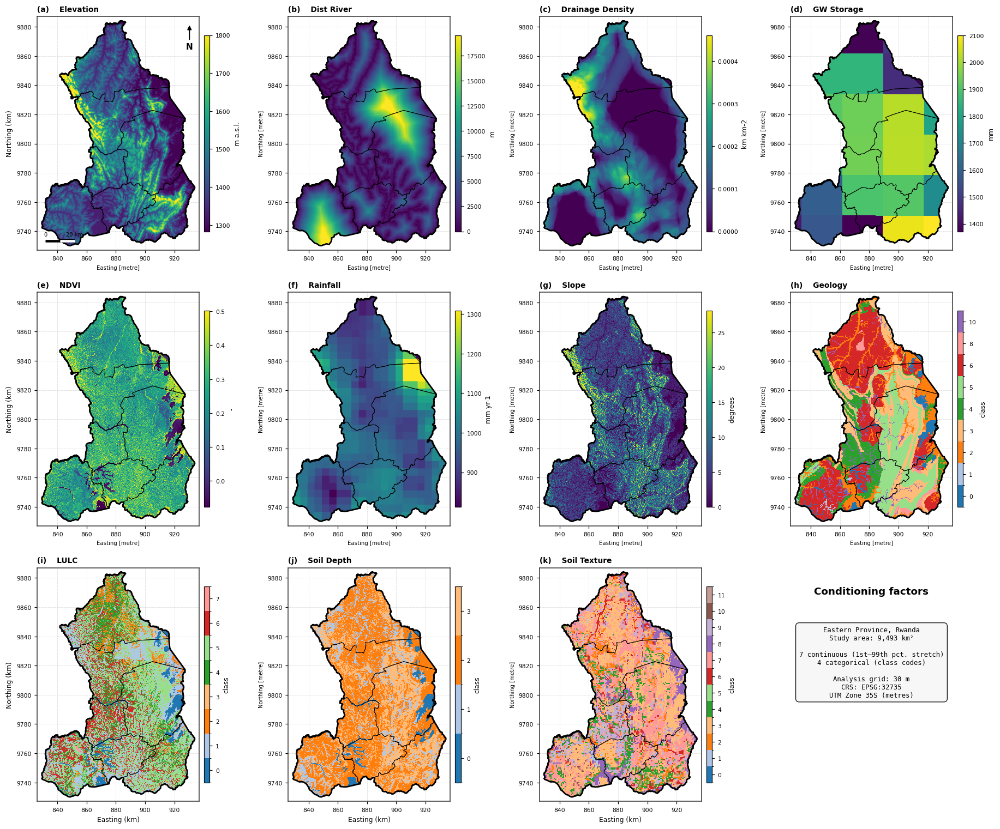

Saved: fig_uncertainty_maps.png / .pdf


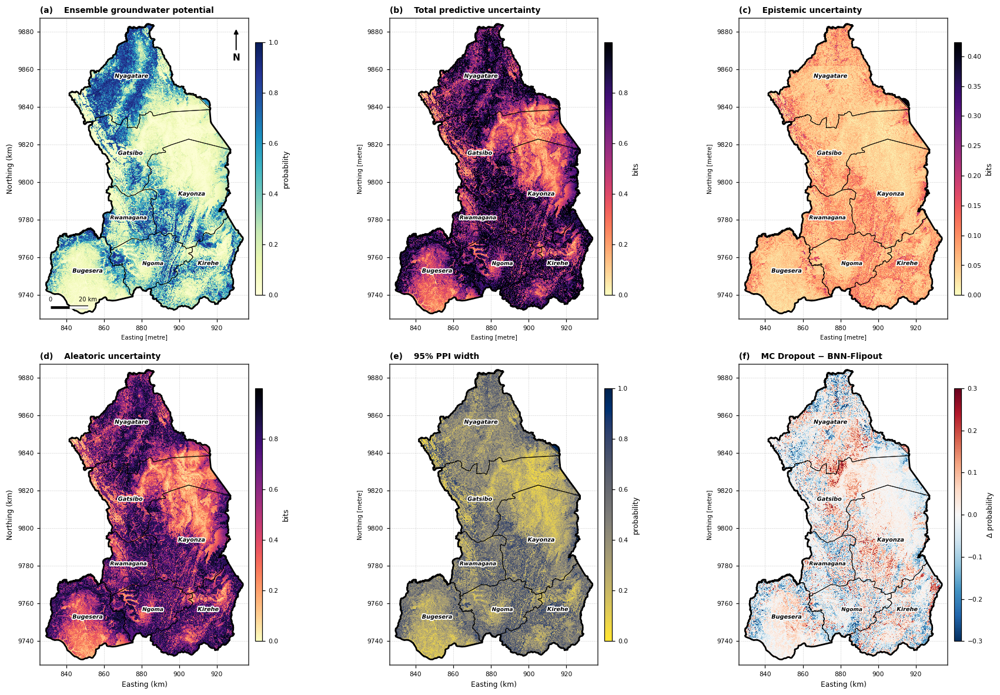

Saved: fig_uncertainty_maps_common_scale.png / .pdf
Saved: fig_gwp_probability_ensemble.png / .pdf


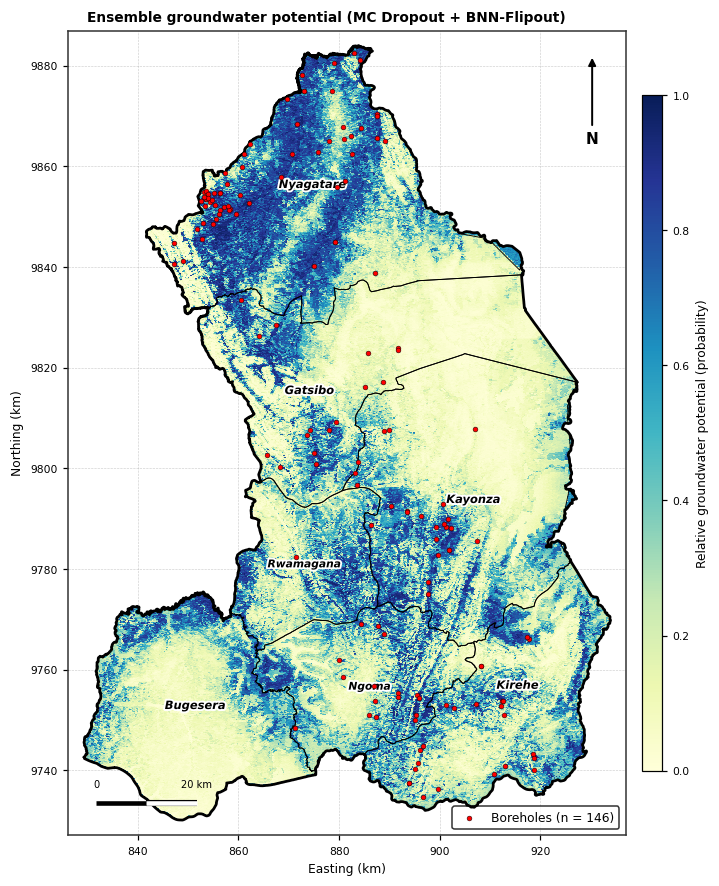

Saved: fig_decision_classes.png / .pdf


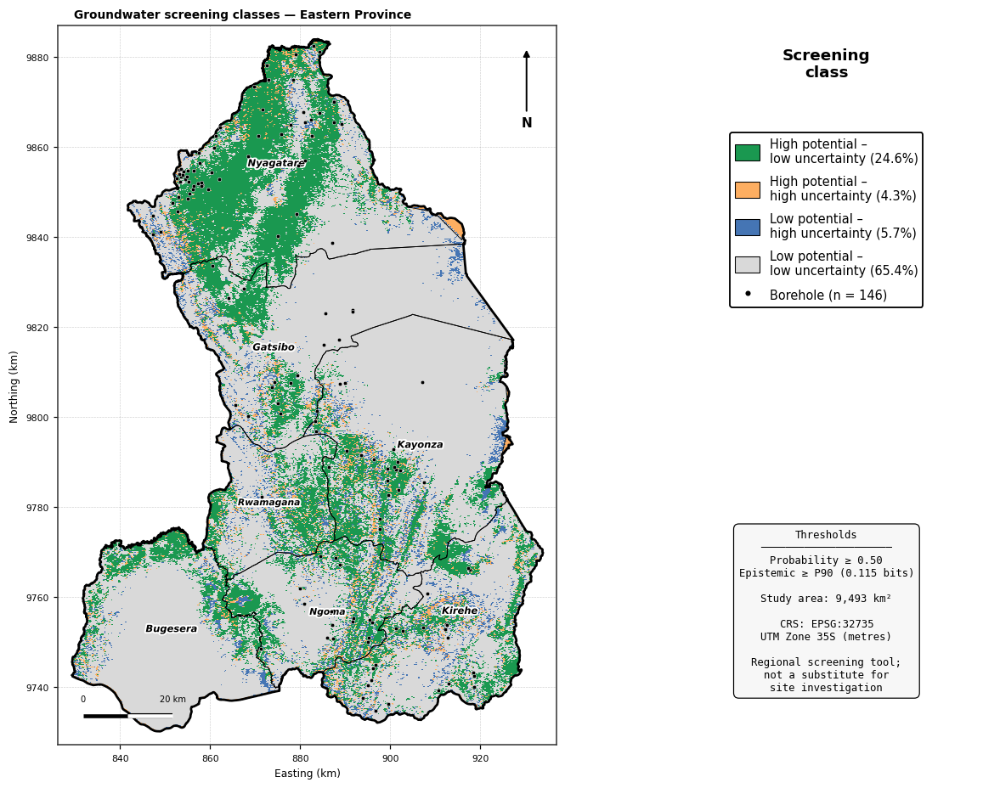

Saved: fig_decision_sensitivity.png / .pdf


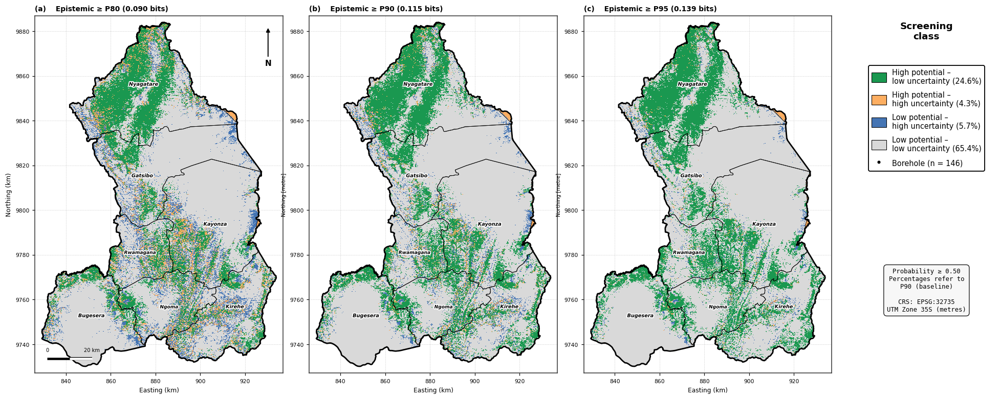

Saved: fig_spatial_blocks.png / .pdf


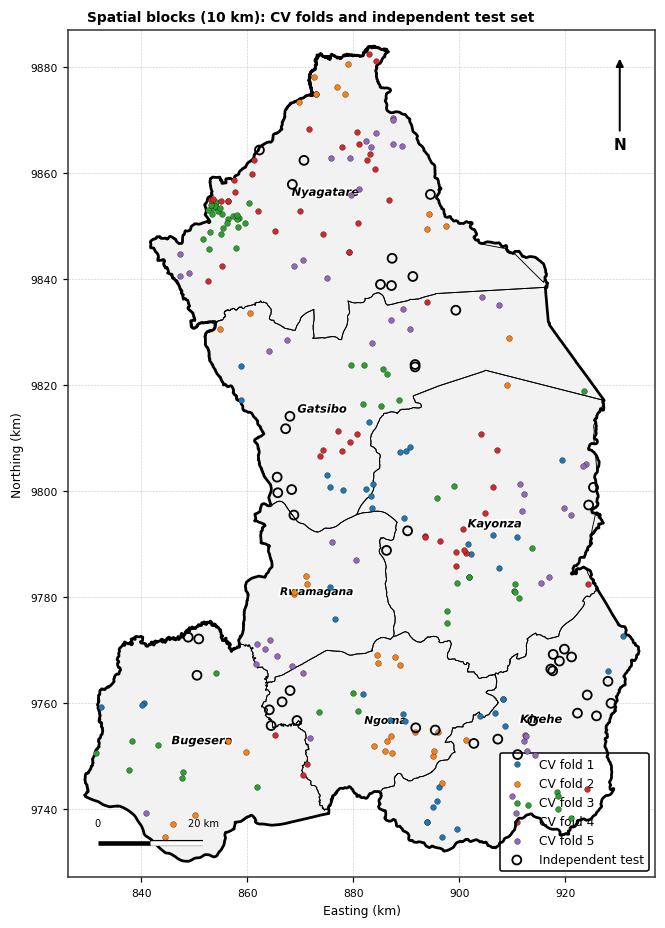


All province maps saved (PNG 300 dpi + PDF) in /content/outputs/figures


In [28]:
# ===================== 13. Publication maps — Eastern Province (reference style) =====================
import os, glob, copy, requests
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D

assert all(v in globals() for v in ["PROVINCE", "CROP", "EXTENT", "valid_mask"]), "Run Section 3.1b first."
OUT = CONFIG["OUT_DIR"]; RAS = os.path.join(OUT, "rasters"); FIG = os.path.join(OUT, "figures")
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8})

# ══════════════════════════════════════════════════════════════
#  1. DISTRICT BOUNDARIES (file if available, otherwise geoBoundaries ADM2)
# ══════════════════════════════════════════════════════════════
CONFIG.setdefault("DISTRICT_FILE", "/content/Rwanda_Districts.shp")
EASTERN_DISTRICTS = ["Bugesera", "Gatsibo", "Kayonza", "Kirehe", "Ngoma", "Nyagatare", "Rwamagana"]

def load_districts():
    f = CONFIG.get("DISTRICT_FILE")
    if f and os.path.exists(f):
        gdf = gpd.read_file(f)
    else:
        meta = requests.get("https://www.geoboundaries.org/api/current/gbOpen/RWA/ADM2/", timeout=60).json()
        gdf = gpd.read_file(meta["gjDownloadURL"])
    if gdf.crs is None: gdf = gdf.set_crs("EPSG:4326")
    gdf = gdf.to_crs(PROVINCE.crs)
    # name column: first text column containing an Eastern district name
    name_col = next((c for c in gdf.columns if gdf[c].dtype == object and
                     gdf[c].astype(str).str.contains("|".join(EASTERN_DISTRICTS), case=False).any()), None)
    if name_col is None:
        name_col = next(c for c in gdf.columns if gdf[c].dtype == object)
    # keep districts whose interior point lies in the province, then clip to the province outline
    inside = gdf.representative_point().within(PROVINCE.buffer(500).unary_union)
    gdf = gpd.clip(gdf[inside], PROVINCE)
    gdf = gdf[~gdf.is_empty].copy()
    gdf["district"] = gdf[name_col].astype(str).str.replace(" District", "", case=False)
    return gdf[["district", "geometry"]]

try:
    eastern_dist_utm = load_districts()
    print("Districts:", ", ".join(sorted(eastern_dist_utm.district)))
except Exception as e:
    eastern_dist_utm = None
    print("District boundaries not available (maps drawn with the province outline only):", e)
eastern_prov_utm = PROVINCE

# label offsets (metres) and font size per district - adjust if labels overlap
DIST_LABEL_CFG = {"Nyagatare": (0, 0, 7.5), "Gatsibo": (0, 0, 7.5), "Kayonza": (0, 0, 7.5),
                  "Rwamagana": (0, 0, 7.0), "Ngoma": (0, 0, 7.0), "Kirehe": (0, 0, 7.5), "Bugesera": (0, 0, 7.5)}

# ══════════════════════════════════════════════════════════════
#  2. CLIP SAVED RASTERS + LOAD MAPS
# ══════════════════════════════════════════════════════════════
for p in glob.glob(os.path.join(RAS, "*.tif")):
    with rasterio.open(p) as s:
        arr = s.read(1).astype(np.float32); prof = s.profile.copy()
    if arr.shape != (H, W): continue
    arr[~valid_mask] = np.nan; prof.update(dtype="float32", nodata=np.nan, compress="lzw")
    with rasterio.open(p, "w", **prof) as d: d.write(arr, 1)

if "MAPS" not in globals(): MAPS = {}
_files = {"mean": "gwp_probability_ensemble.tif", "mean_m0": "gwp_probability_mc_dropout.tif",
          "mean_m1": "gwp_probability_bnn.tif", "total": "uncertainty_total_bits.tif",
          "epistemic": "uncertainty_epistemic_bits.tif", "aleatoric": "uncertainty_aleatoric_bits.tif",
          "ppi_width": "ppi95_width.tif", "DI": "dissimilarity_index.tif", "AOA": "area_of_applicability.tif"}
for k, fn in _files.items():
    p = os.path.join(RAS, fn)
    if k not in MAPS and os.path.exists(p):
        with rasterio.open(p) as s: MAPS[k] = s.read(1).astype(np.float32)
for k in list(MAPS):
    if isinstance(MAPS[k], np.ndarray) and MAPS[k].shape == (H, W):
        MAPS[k] = np.where(valid_mask, MAPS[k], np.nan).astype(np.float32)

# ══════════════════════════════════════════════════════════════
#  3. PANEL HELPERS
# ══════════════════════════════════════════════════════════════
def add_raster(ax, arr, cmap, vmin=None, vmax=None, norm=None):
    a = np.ma.masked_invalid(np.where(valid_mask, arr, np.nan)[CROP])
    cm = copy.copy(plt.get_cmap(cmap) if isinstance(cmap, str) else cmap); cm.set_bad(alpha=0)
    kw = dict(norm=norm) if norm is not None else dict(vmin=vmin, vmax=vmax)
    return ax.imshow(a, cmap=cm, extent=EXTENT, interpolation="nearest", aspect="equal", zorder=2, **kw)

def style_panel(ax, panel_label, title, show_xlabel=False, show_ylabel=False,
                labels=True, north=False, scalebar=False, label_size_scale=1.0):
    if eastern_dist_utm is not None:
        eastern_dist_utm.boundary.plot(ax=ax, edgecolor="black", linewidth=0.6, zorder=5)
        if labels:
            for _, row in eastern_dist_utm.iterrows():
                ox, oy, fs = DIST_LABEL_CFG.get(row.district, (0, 0, 7.0))
                pt = row.geometry.representative_point()
                ax.text(pt.x + ox, pt.y + oy, row.district, fontsize=fs * label_size_scale, ha="center", va="center",
                        fontweight="bold", fontstyle="italic", color="black", zorder=7,
                        path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
    eastern_prov_utm.boundary.plot(ax=ax, edgecolor="black", linewidth=1.8, zorder=6)
    ax.set_title(f"{panel_label}    {title}", fontweight="bold", fontsize=9, loc="left")
    pb = eastern_prov_utm.total_bounds; pad = 3000
    ax.set_xlim(pb[0] - pad, pb[2] + pad); ax.set_ylim(pb[1] - pad, pb[3] + pad)
    fmt = mticker.FuncFormatter(lambda v, _: f"{v / 1000:.0f}")
    ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(20000)); ax.yaxis.set_major_locator(mticker.MultipleLocator(20000))
    ax.tick_params(labelsize=7)
    if show_ylabel: ax.set_ylabel("Northing (km)", fontsize=8)
    if show_xlabel: ax.set_xlabel("Easting (km)", fontsize=8)
    ax.grid(True, linestyle="--", linewidth=0.4, color="grey", alpha=0.4, zorder=1)
    for sp in ax.spines.values(): sp.set_linewidth(1.0); sp.set_color("#333333")
    if north:
        ax.annotate("N", xy=(0.94, 0.97), xytext=(0.94, 0.86), xycoords="axes fraction", ha="center", fontsize=10,
                    fontweight="bold", zorder=8, arrowprops=dict(arrowstyle="-|>", color="k", lw=1.3))
    if scalebar:
        x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
        L = 20000; xs = x0 + 0.05 * (x1 - x0); ys = y0 + 0.04 * (y1 - y0)
        ax.plot([xs, xs + L / 2], [ys, ys], color="k", lw=3, solid_capstyle="butt", zorder=8)
        ax.plot([xs + L / 2, xs + L], [ys, ys], color="white", lw=3, solid_capstyle="butt", zorder=8,
                path_effects=[pe.withStroke(linewidth=4, foreground="k")])
        ax.text(xs, ys + 0.02 * (y1 - y0), "0", ha="center", fontsize=6.5, zorder=8)
        ax.text(xs + L, ys + 0.02 * (y1 - y0), f"{L / 1000:.0f} km", ha="center", fontsize=6.5, zorder=8)

def add_cbar(ax, im, label, ticks=None, ticklabels=None):
    cax = ax.inset_axes([1.03, 0.08, 0.035, 0.84])
    cb = plt.colorbar(im, cax=cax, ticks=ticks)
    if ticklabels is not None: cb.ax.set_yticklabels(ticklabels, fontsize=6.5)
    cb.ax.tick_params(labelsize=7); cb.set_label(label, fontsize=8); cb.outline.set_linewidth(0.8)
    return cb

def info_box(ax, text, y=0.30):
    ax.text(0.5, y, text, fontsize=8, ha="center", va="top", transform=ax.transAxes, family="monospace",
            bbox=dict(boxstyle="round,pad=0.5", facecolor="#f7f7f7", edgecolor="black", linewidth=0.8))

def save_both(name):
    for ext in ["png", "pdf"]:
        plt.savefig(os.path.join(FIG, f"{name}.{ext}"), dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved: {name}.png / .pdf")

AREA_TXT = f"{REPORT.get('study_area_km2', valid_mask.sum() * PIXEL_AREA_KM2):,.0f} km²"
CRS_TXT = f"CRS: {REF_CRS.to_string()}\nUTM Zone 35S (metres)"
GWP_T = REPORT.get("gwp_threshold", globals().get("GWP_THR", 0.5))

# ══════════════════════════════════════════════════════════════
#  4. FIGURE: CONDITIONING FACTORS (11 panels + info panel)
# ══════════════════════════════════════════════════════════════
LETTERS = "abcdefghijklmnopqrstuvwxyz"
fig = plt.figure(figsize=(20, 17), facecolor="white")
gs = gridspec.GridSpec(3, 4, wspace=0.42, hspace=0.18)
for i, f in enumerate(FACTORS):
    ax = fig.add_subplot(gs[i // 4, i % 4])
    title = f.replace("_", " ")
    if f in CONFIG["CATEGORICAL_FACTORS"]:
        codes = np.unique(stack[f][valid_mask]).astype(int); n = len(codes)
        idx = np.full(stack[f].shape, np.nan, np.float32)
        idx[valid_mask] = np.searchsorted(codes, stack[f][valid_mask].astype(int))
        cmap = mcolors.ListedColormap(plt.get_cmap("tab20")(np.arange(n) % 20))
        norm = mcolors.BoundaryNorm(np.arange(n + 1) - 0.5, n)
        im = add_raster(ax, idx, cmap, norm=norm)
        labs = [str(CLASS_LABELS.get(f, {}).get(c, c)) if "CLASS_LABELS" in globals() else str(c) for c in codes]
        step = 1 if n <= 14 else 2
        add_cbar(ax, im, "class", ticks=np.arange(0, n, step), ticklabels=labs[::step])
    else:
        im = add_raster(ax, stack[f], "viridis",
                        vmin=np.nanpercentile(stack[f][valid_mask], 1), vmax=np.nanpercentile(stack[f][valid_mask], 99))
        add_cbar(ax, im, FACTOR_METADATA.get(f, {}).get("units", ""))
    style_panel(ax, f"({LETTERS[i]})", title, show_xlabel=(i // 4 == 2), show_ylabel=(i % 4 == 0),
                labels=False, north=(i == 0), scalebar=(i == 0))
ax_info = fig.add_subplot(gs[2, 3]); ax_info.axis("off")
ax_info.text(0.5, 0.92, "Conditioning factors", fontsize=12, fontweight="bold", ha="center", va="top", transform=ax_info.transAxes)
info_box(ax_info, f"Eastern Province, Rwanda\nStudy area: {AREA_TXT}\n\n7 continuous (1st–99th pct. stretch)\n"
                  f"4 categorical (class codes)\n\nAnalysis grid: {PX_W:.0f} m\n{CRS_TXT}", y=0.75)
save_both("fig_conditioning_factors"); plt.show()

# ══════════════════════════════════════════════════════════════
#  5. FIGURE: PROBABILITY AND UNCERTAINTY (6 panels)
# ══════════════════════════════════════════════════════════════
if all(k in MAPS for k in ["mean", "total", "epistemic", "aleatoric", "ppi_width"]):
    u_max = float(np.nanpercentile(MAPS["total"][valid_mask], 99.5))
    e_max = float(np.nanpercentile(MAPS["epistemic"][valid_mask], 99.5))
    for common in [False, True]:
        panels = [("(a)", "Ensemble groundwater potential", MAPS["mean"], "YlGnBu", 0, 1, "probability"),
                  ("(b)", "Total predictive uncertainty", MAPS["total"], "magma_r", 0, u_max, "bits"),
                  ("(c)", "Epistemic uncertainty", MAPS["epistemic"], "magma_r", 0, u_max if common else e_max, "bits"),
                  ("(d)", "Aleatoric uncertainty", MAPS["aleatoric"], "magma_r", 0, u_max, "bits"),
                  ("(e)", "95% PPI width", MAPS["ppi_width"], "cividis_r", 0, 1, "probability")]
        if "mean_m0" in MAPS and "mean_m1" in MAPS:
            panels.append(("(f)", "MC Dropout − BNN-Flipout", MAPS["mean_m0"] - MAPS["mean_m1"], "RdBu_r", -0.3, 0.3, "Δ probability"))
        fig = plt.figure(figsize=(19, 13), facecolor="white")
        gs = gridspec.GridSpec(2, 3, wspace=0.38, hspace=0.15)
        for i, (lbl, ttl, arr, cmap, vmin, vmax, unit) in enumerate(panels):
            ax = fig.add_subplot(gs[i // 3, i % 3])
            im = add_raster(ax, arr, cmap, vmin, vmax); add_cbar(ax, im, unit)
            style_panel(ax, lbl, ttl, show_xlabel=(i // 3 == 1), show_ylabel=(i % 3 == 0),
                        label_size_scale=0.85, north=(i == 0), scalebar=(i == 0))
        save_both("fig_uncertainty_maps_common_scale" if common else "fig_uncertainty_maps")
        plt.show() if not common else plt.close()

    # single-panel ensemble probability map
    fig = plt.figure(figsize=(9, 9.5), facecolor="white"); ax = fig.add_subplot(111)
    im = add_raster(ax, MAPS["mean"], "YlGnBu", 0, 1); add_cbar(ax, im, "Relative groundwater potential (probability)")
    if "bh" in globals():
        ax.scatter(bh.x_grid, bh.y_grid, s=10, c="red", edgecolor="k", linewidth=0.3, zorder=8, label=f"Boreholes (n = {len(bh)})")
        ax.legend(loc="lower right", fontsize=8, frameon=True, edgecolor="black")
    style_panel(ax, "", "Ensemble groundwater potential (MC Dropout + BNN-Flipout)", True, True, north=True, scalebar=True)
    save_both("fig_gwp_probability_ensemble"); plt.show()

# ══════════════════════════════════════════════════════════════
#  6. FIGURE: DISSIMILARITY INDEX AND AREA OF APPLICABILITY
# ══════════════════════════════════════════════════════════════
if "DI" in MAPS and "AOA" in MAPS:
    fig = plt.figure(figsize=(16, 8.5), facecolor="white")
    gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1, 0.45], wspace=0.3)
    ax = fig.add_subplot(gs[0, 0])
    im = add_raster(ax, MAPS["DI"], "viridis", 0, float(np.nanpercentile(MAPS["DI"][valid_mask], 99))); add_cbar(ax, im, "DI")
    style_panel(ax, "(a)", "Dissimilarity index", True, True, north=True, scalebar=True)
    ax = fig.add_subplot(gs[0, 1])
    add_raster(ax, MAPS["AOA"], mcolors.ListedColormap(["#c53030", "#e2e8f0"]), 0, 1)
    style_panel(ax, "(b)", "Area of applicability", True, False)
    ax_leg = fig.add_subplot(gs[0, 2]); ax_leg.axis("off")
    out_pct = 100 * np.mean(MAPS["AOA"][valid_mask] == 0)
    ax_leg.text(0.5, 0.96, "Area of\nApplicability", fontsize=12, fontweight="bold", ha="center", va="top", transform=ax_leg.transAxes)
    leg = ax_leg.legend(handles=[mpatches.Patch(facecolor="#e2e8f0", edgecolor="black", label=f"Inside AOA ({100 - out_pct:.1f}%)"),
                                 mpatches.Patch(facecolor="#c53030", edgecolor="black", label=f"Outside AOA ({out_pct:.1f}%)")],
                        loc="upper center", bbox_to_anchor=(0.5, 0.80), fontsize=10, frameon=True, edgecolor="black",
                        handlelength=2.0, handleheight=1.2)
    leg.get_frame().set_linewidth(1.2)
    thr_txt = f"{REPORT['aoa']['aoa_threshold']:.3f}" if isinstance(REPORT.get("aoa"), dict) else "see table"
    info_box(ax_leg, f"AOA: DI ≤ {thr_txt}\n(Meyer & Pebesma 2021)\nSHAP-weighted feature space\n\n{CRS_TXT}", y=0.45)
    save_both("fig_aoa_maps"); plt.show()

# ══════════════════════════════════════════════════════════════
#  7. FIGURE: SCREENING CLASSES (+ legend panel) AND SENSITIVITY
# ══════════════════════════════════════════════════════════════
CLASS_NAMES_ = {1: "High potential –\nlow uncertainty", 2: "High potential –\nhigh uncertainty",
                3: "Low potential –\nhigh uncertainty", 4: "Low potential –\nlow uncertainty"}
CLASS_COLORS_ = ["#1a9850", "#fdae61", "#4575b4", "#d9d9d9"]
cm4 = mcolors.ListedColormap(CLASS_COLORS_); nrm4 = mcolors.BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5], 4)
U_ = MAPS.get(CONFIG["UNC_COMPONENT"])

def classify_map(pt, up):
    ut = np.nanpercentile(U_[valid_mask], up); hp, hu = MAPS["mean"] >= pt, U_ >= ut
    c = np.full((H, W), np.nan, np.float32)
    c[valid_mask & hp & ~hu] = 1; c[valid_mask & hp & hu] = 2; c[valid_mask & ~hp & hu] = 3; c[valid_mask & ~hp & ~hu] = 4
    return c, ut

def class_legend(ax_leg, cls, extra_text):
    ax_leg.axis("off")
    ax_leg.text(0.5, 0.97, "Screening\nclass", fontsize=12, fontweight="bold", ha="center", va="top", transform=ax_leg.transAxes)
    handles = [mpatches.Patch(facecolor=CLASS_COLORS_[k - 1], edgecolor="black", linewidth=0.7,
                              label=f"{CLASS_NAMES_[k]} ({100 * np.mean(cls[valid_mask] == k):.1f}%)") for k in range(1, 5)]
    if "bh" in globals():
        handles.append(Line2D([], [], marker="o", ls="", markerfacecolor="black", markeredgecolor="white",
                              markersize=5, label=f"Borehole (n = {len(bh)})"))
    leg = ax_leg.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.86), fontsize=9.5, frameon=True,
                        fancybox=True, edgecolor="black", framealpha=1, handlelength=2.0, handleheight=1.6, labelspacing=0.8)
    leg.get_frame().set_linewidth(1.2)
    info_box(ax_leg, extra_text, y=0.30)

if U_ is not None and "mean" in MAPS:
    cls, ut = classify_map(GWP_T, CONFIG["UNC_PERCENTILE"])
    fig = plt.figure(figsize=(14, 10), facecolor="white")
    gs = gridspec.GridSpec(1, 2, width_ratios=[1, 0.5], wspace=0.05)
    ax = fig.add_subplot(gs[0, 0])
    add_raster(ax, cls, cm4, norm=nrm4)
    if "bh" in globals():
        ax.scatter(bh.x_grid, bh.y_grid, s=9, c="black", edgecolor="white", linewidth=0.3, zorder=8)
    style_panel(ax, "", "Groundwater screening classes — Eastern Province", True, True, north=True, scalebar=True)
    class_legend(fig.add_subplot(gs[0, 1]), cls,
                 f"Thresholds\n─────────────────────\nProbability ≥ {GWP_T:.2f}\nEpistemic ≥ P{CONFIG['UNC_PERCENTILE']}"
                 f" ({ut:.3f} bits)\n\nStudy area: {AREA_TXT}\n\n{CRS_TXT}\n\nRegional screening tool;\nnot a substitute for\nsite investigation")
    save_both("fig_decision_classes"); plt.show()

    ups = CONFIG["UNC_PERCENTILES_SENS"]
    fig = plt.figure(figsize=(22, 8.5), facecolor="white")
    gs = gridspec.GridSpec(1, len(ups) + 1, width_ratios=[1] * len(ups) + [0.55], wspace=0.12)
    for j, up in enumerate(ups):
        c, ut_j = classify_map(GWP_T, up)
        ax = fig.add_subplot(gs[0, j]); add_raster(ax, c, cm4, norm=nrm4)
        style_panel(ax, f"({LETTERS[j]})", f"Epistemic ≥ P{up} ({ut_j:.3f} bits)", show_xlabel=True,
                    show_ylabel=(j == 0), label_size_scale=0.85, north=(j == 0), scalebar=(j == 0))
    c_base, _ = classify_map(GWP_T, CONFIG["UNC_PERCENTILE"])
    class_legend(fig.add_subplot(gs[0, -1]), c_base,
                 f"Probability ≥ {GWP_T:.2f}\nPercentages refer to\nP{CONFIG['UNC_PERCENTILE']} (baseline)\n\n{CRS_TXT}")
    save_both("fig_decision_sensitivity"); plt.show()

# ══════════════════════════════════════════════════════════════
#  8. FIGURE: OBSERVATIONS AND SPATIAL BLOCKS
# ══════════════════════════════════════════════════════════════
if "dev" in globals() and "test" in globals():
    fig = plt.figure(figsize=(9, 10), facecolor="white"); ax = fig.add_subplot(111)
    add_raster(ax, np.where(valid_mask, 1.0, np.nan), mcolors.ListedColormap(["#f2f2f2"]), 0, 1)
    cmap_f = plt.get_cmap("tab10")
    for k in range(CONFIG["CV_FOLDS"]):
        d = dev[dev.fold == k]
        ax.scatter(d.x, d.y, s=14, color=cmap_f(k), edgecolor="k", linewidth=0.2, label=f"CV fold {k + 1}", zorder=8)
    ax.scatter(test.x, test.y, s=34, facecolor="none", edgecolor="k", lw=1.2, label="Independent test", zorder=9)
    style_panel(ax, "", f"Spatial blocks ({CONFIG['BLOCK_SIZE_M'] / 1000:.0f} km): CV folds and independent test set",
                True, True, north=True, scalebar=True)
    leg = ax.legend(loc="lower right", fontsize=8, frameon=True, edgecolor="black", framealpha=1)
    leg.get_frame().set_linewidth(1.0)
    save_both("fig_spatial_blocks"); plt.show()

print("\nAll province maps saved (PNG 300 dpi + PDF) in", FIG)